# Data hypercleaning — corrupted MNIST

Setup of the TSP paper (and `ShelleyCode/TSPComparison.ipynb`, "Paper Corrupted Data"): 5,000 training images with
50% of the labels replaced by a random wrong label, 5,000 clean validation images and 10,000 clean test images.

* **Lower level** ($w$ = linear classifier): $\;J(w,\theta) = \frac{1}{B}\sum_{i} \sigma(\theta_i)\,\ell(w; x_i, y_i)$ on training batches
* **Upper level** ($\theta$ = one logit per training sample): $\;F(w,\theta) = \frac{1}{B}\sum_j \ell(w; x_j^{val}, y_j^{val})$ on validation batches

A good method drives the weights $\sigma(\theta_i)$ of corrupted samples to 0 and those of clean samples to 1.
We report test accuracy and the **data-cleaning F1 score** (sample flagged as corrupted when $\sigma(\theta_i) < 0.5$).

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from typing import Callable, Dict, List, Optional, Tuple
from functools import partial
import copy
import pickle
import matplotlib

from blo_optimisers import *
from utils import *
from data_utils import load_corrupted_mnist, make_datasets

In [9]:
class MNISTLinear(nn.Module):
    """Lower-level model w: multinomial logistic regression"""
    def __init__(self, seed:int=None):
        super().__init__()
        if seed is not None:
            torch.manual_seed(seed)
        self.linear = nn.Linear(28 * 28, 10)

    def forward(self, images):
        return self.linear(images.flatten(1))


class MNISTMLP(nn.Module):
    """Lower-level model w: one-hidden-layer MLP (drop-in replacement for MNISTLinear)"""
    def __init__(self, hidden_dim=128, seed:int=None):
        super().__init__()
        if seed is not None:
            torch.manual_seed(seed)
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, 10))

    def forward(self, images):
        return self.net(images)


class SampleWeightModel(nn.Module):
    """Upper-level model theta: one logit per training sample, weight = sigmoid(logit)"""
    def __init__(self, num_training_examples, init_logit:float=0.0):
        super().__init__()
        self.raw_theta = nn.Parameter(torch.full((num_training_examples,), init_logit))

    def forward(self, sample_ids):
        return torch.sigmoid(self.raw_theta[sample_ids])
# s = SampleWeightModel()
# s.raw_theta.data.clip(min=-5,max=5)

### Data

In [10]:
device = torch.device("cpu")
DATA_ROOT = "./data"          # MNIST is downloaded here on first run
N_TRAIN, N_VAL, N_TEST = 4992, 4992, 10000
CORRUPTION_FRAC = 0.5
DATA_SEED = 0

splits = load_corrupted_mnist(n_train=N_TRAIN, n_val=N_VAL, n_test=N_TEST,
                              corruption_frac=CORRUPTION_FRAC, seed=DATA_SEED, root=DATA_ROOT)
datasets = make_datasets(splits)
corrupted_mask = splits["corrupted_mask"]

assert torch.equal(corrupted_mask, splits["y_train"] != splits["y_train_clean"])
print("Train / val / test:", len(datasets["train"]), len(datasets["val"]), len(datasets["test"]))
print(f"Corrupted training labels: {corrupted_mask.sum().item()} ({100 * corrupted_mask.float().mean().item():.1f}%)")

Train / val / test: 4992 4992 10000
Corrupted training labels: 2496 (50.0%)


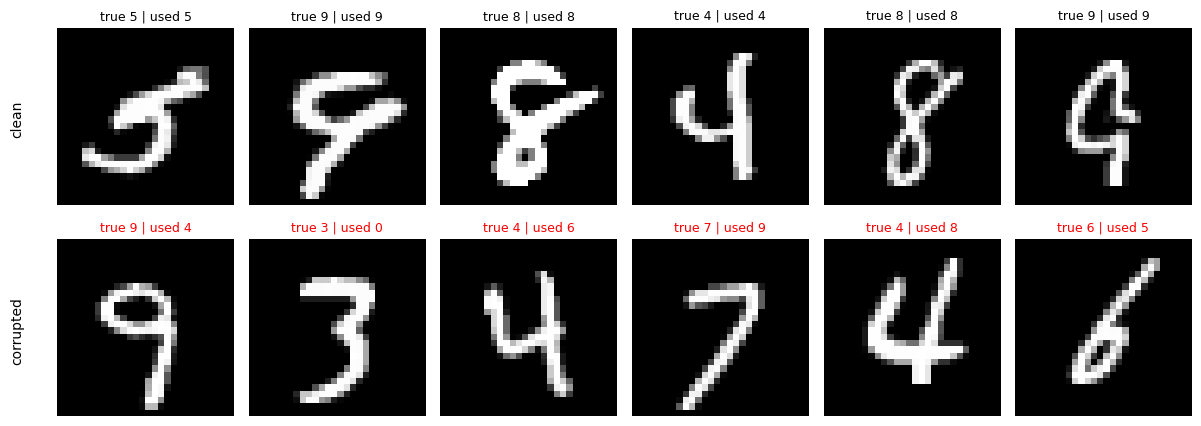

In [11]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for row, ids in enumerate([torch.where(~corrupted_mask)[0][:6], torch.where(corrupted_mask)[0][:6]]):
    for ax, i in zip(axes[row], ids):
        ax.imshow(splits["x_train"][i].squeeze(), cmap="gray")
        ax.set_title(f"true {splits['y_train_clean'][i].item()} | used {splits['y_train'][i].item()}",
                     color="black" if row == 0 else "red", fontsize=9)
        ax.axis("off")
axes[0, 0].text(-8, 14, "clean", rotation=90, va="center")
axes[1, 0].text(-8, 14, "corrupted", rotation=90, va="center")
plt.tight_layout()
plt.show()

### Define Loss Functions

In [12]:
LL_REG = 0.0

def lower_loss(ll_model, data, ul_model, stochastic=False, seed=None, **kwargs):
    """J(w, theta): sample-weighted training cross-entropy"""
    images, labels, sample_ids = data["train"]
    per_sample_losses = F.cross_entropy(ll_model(images), labels, reduction="none")
    sample_weights = ul_model(sample_ids)
    loss = (sample_weights * per_sample_losses).mean()
    if LL_REG:
        loss = loss+LL_REG*sum((p.square()/(1+p.square())).sum() for p in ll_model.parameters())
    return loss 


def upper_loss(ll_model, data, ul_model, stochastic=False, seed=None, **kwargs):
    """F(w, theta): validation cross-entropy"""
    images, labels = data["val"]
    return F.cross_entropy(ll_model(images), labels)

### Optimisers

Hyperparameters for PABLO, BOME and TSP are the MNIST values from `ShelleyCode/TSPComparison.ipynb`.
AID, AAL and PBGD-Free have **not** been tuned on this problem.

* **STABLE** is left out: it builds the full $d_w \times d_w$ lower-level Hessian explicitly ($d_w = 7850$), one backward pass per row, every step.
* **PBGD-Free** only updates $\theta$ along $\nabla_\theta F$, and $F$ does not depend on $\theta$ here, so its sample weights never move.
  It is kept as a "no cleaning" baseline.

In [13]:
SGD_MOMENTUM = partial(torch.optim.SGD, momentum=0.9)

HPARAMS = {

    # "PABLO": dict(lr_w=1e-4, lr_theta=0.01, rmsprop_alpha=0.99, rho=1e-4, lr_lambda=1e-4,
    #               tau=1.7e-4, y_rate=1.0, lambda_bound=1, grad_clip=None),
    # "BOME": dict(opt="sgdm", inner_steps=10, inner_lr=0.33, eta=2.1, lr_w=0.033, lr_theta=10.0, barrier="grad_norm"),
    # BLO_optimiser_TSP (practical variant, torch.optim updates)
    # tuned for the same setting as PABLO: 78.6% ± 0.6 final test acc over seeds 0-4 (previous values: 77.0% ± 0.3)
    # "TSP": dict(gamma=0.25, delta=0.0, p=0.003, eta_z=0.003, lr_y=0.033, lr_x=225, dual_lr=0.7,
    #             constraint_ema=0.01, lambda_ema=1.0, anchor_ema=0.5, lambda_init=5.0),
    #       gamma  Moreau smoothing parameter        delta  constraint slack
    #   p      proximal (anchor) weight          tau    dual step size
    #   mu     dual smoothing (lambda EMA)       theta  constraint smoothing (h EMA)
    #   eta    z step size                       alpha  x step size
    #   beta   y step size                       omega  anchor EMA
    # "TSP": dict(gamma=1.1, delta=0.0, p=1, eta=0.5, beta=0.5, alpha=0.5, tau=0.005,
    #         theta=0.5, mu=0.05, omega=0.1, lambda_init=0.77),
    # "TSP": dict(gamma=1.8, delta=0.0, p=1e-4, eta=0.026, beta=0.015, alpha=500.0, tau=0.067, theta=0.01, mu=0.05, omega=0.1, lambda_init=2.6),
    # "TSP": dict(gamma=2, delta=0.0, p=1, eta=0.01, beta=.01, alpha=0.01, tau=0.01, theta=0.01, mu=0.999, omega=0.999, lambda_init=1.),
    # "AAL": dict(L_f=1, L_grad_g=3.0, L_H=0.001, gamma=0.26, rho0=0.1, alpha=1e-3, eps=0.01, tau=0.1),
    # "PBGD-Free": dict(gamma=10.0, eta=0.5, eta_gamma=0.01, K=1),

    "PABLO": dict(lr_w=0.004, lr_theta=0.27, rmsprop_alpha=0.99, rho=0.18, lr_lambda=0.0001,
                  tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=None, warmup_ratio=10/1000, total_steps=1000),
    "BOME": dict(opt="sgdm", inner_steps=10, inner_lr=0.33, eta=2.1, lr_w=0.033, lr_theta=10.0, barrier="grad_norm"),
    "TSP": dict(gamma=2, delta=0.0, p=1e-4, eta=0.052, beta=.14, alpha=500., tau=0.67, theta=0.01, mu=0.05, omega=0.999, lambda_init=1.),
    # "AAL": dict(L_f=1, L_grad_g=3.0, L_H=0.001, gamma=0.26, rho0=0.1, alpha=1e-3, eps=0.0, tau=0.1),
    "AAL": dict(rho0=0.01, alpha=0.0001, eps=1e-6, t=8, tau=0.1)
}

METHODS = [ "PABLO", "AAL", "BOME", "TSP"]#, "PBGD-Free"]
# METHODS = [ "AAL",]#, "PBGD-Free"]


def build_optimiser(method, classifier, weight_model):
    h = HPARAMS[method]
    common = dict(ll_model=classifier, ul_model=weight_model, lower_loss_fn=lower_loss, upper_loss_fn=upper_loss,
                  stochastic=False, device=device)

    if method == "PABLO":
        rms = {"alpha": h["rmsprop_alpha"]}
        return BLO_optimiser_PABLO_Prox_Bound(**common,
            w_optimiser=torch.optim.RMSprop, theta_optimiser=torch.optim.RMSprop, lambda_optimiser=torch.optim.SGD,
            w_optimiser_kwargs=rms, theta_optimiser_kwargs=rms,
            lr_w=h["lr_w"], lr_theta=h["lr_theta"], rho=h["rho"], lr_lambda=h["lr_lambda"],
            tau=h["tau"], gamma=h["y_rate"] / h["tau"], lambda_bound=h["lambda_bound"], grad_clip=h["grad_clip"],warmup_ratio=h["warmup_ratio"],
            total_steps=h["total_steps"])

    if method == "BOME":
        bome_opt = {"sgdm": SGD_MOMENTUM, "adam": torch.optim.Adam, "rmsprop": torch.optim.RMSprop}[h.get("opt", "sgdm")]
        return BLO_optimiser_BOME(**common, inner_steps=h["inner_steps"], inner_lr=h["inner_lr"], eta=h["eta"],
            lr_w=h["lr_w"], lr_theta=h["lr_theta"], w_optimiser=bome_opt, theta_optimiser=bome_opt,
            barrier=h["barrier"])

    if method == "TSP":
        return BLO_optimiser_TSP(**common, **h)

    if method == "AID":
        return BLO_optimiser_AID_Neumann(**common, **h)

    if method == "AAL":
        return BLO_optimiser_AAL(**common, **h)

    if method == "PBGD-Free":
        return BLO_optimiser_PBGD_Free(**common, **h)

    raise ValueError(f"unknown method: {method}")

### Train

In [14]:
NUM_ITERS = 10000
BATCH_SIZE = 64
# SEED = 100
EVAL_EVERY = 10

all_results_and_seeds = {}

for seed in range(4):
    results = {}
    for method in METHODS:
        classifier = MNISTMLP(seed=seed).to(device)
        weight_model = SampleWeightModel(N_TRAIN).to(device)
        optimiser = build_optimiser(method, classifier, weight_model)

        history = run_hypercleaning(optimiser, classifier, weight_model, datasets, corrupted_mask,
                                    num_iters=NUM_ITERS, batch_size=BATCH_SIZE, seed=seed,
                                    eval_every=EVAL_EVERY, print_every=100, device=device, name=method)
        results[method] = {"history": history, "classifier": classifier, "weight_model": weight_model}
    all_results_and_seeds[seed] = results
    print()
    #AAL         1000 | LL=0.9653 | UL=0.7655 | test acc=87.38% | clean w=0.502 | corrupt w=0.496 | cleaning F1=95.56% | 5s

PABLO        100 | LL=0.6246 | UL=0.2072 | test acc=91.77% | clean w=0.514 | corrupt w=0.143 | cleaning F1=75.62% | 0s
PABLO        200 | LL=0.3970 | UL=0.0800 | test acc=92.86% | clean w=0.496 | corrupt w=0.073 | cleaning F1=78.29% | 1s
PABLO        300 | LL=0.2880 | UL=0.2073 | test acc=93.36% | clean w=0.477 | corrupt w=0.041 | cleaning F1=78.85% | 1s
PABLO        400 | LL=0.1915 | UL=0.0271 | test acc=94.69% | clean w=0.469 | corrupt w=0.030 | cleaning F1=78.72% | 2s
PABLO        500 | LL=0.1310 | UL=0.0460 | test acc=94.71% | clean w=0.464 | corrupt w=0.023 | cleaning F1=78.52% | 2s
PABLO        600 | LL=0.1109 | UL=0.0209 | test acc=94.78% | clean w=0.461 | corrupt w=0.019 | cleaning F1=78.43% | 3s
PABLO        700 | LL=0.1169 | UL=0.0092 | test acc=94.87% | clean w=0.461 | corrupt w=0.016 | cleaning F1=78.38% | 3s
PABLO        800 | LL=0.0917 | UL=0.0072 | test acc=94.93% | clean w=0.460 | corrupt w=0.015 | cleaning F1=78.37% | 3s
PABLO        900 | LL=0.0895 | UL=0.0044 | test 

KeyboardInterrupt: 

### Results

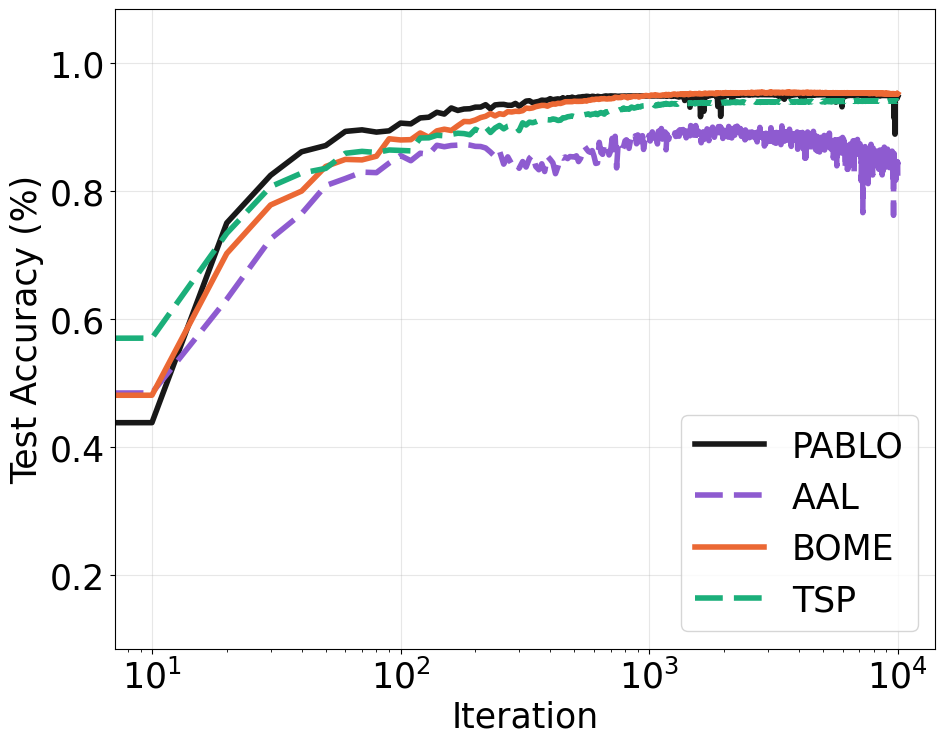

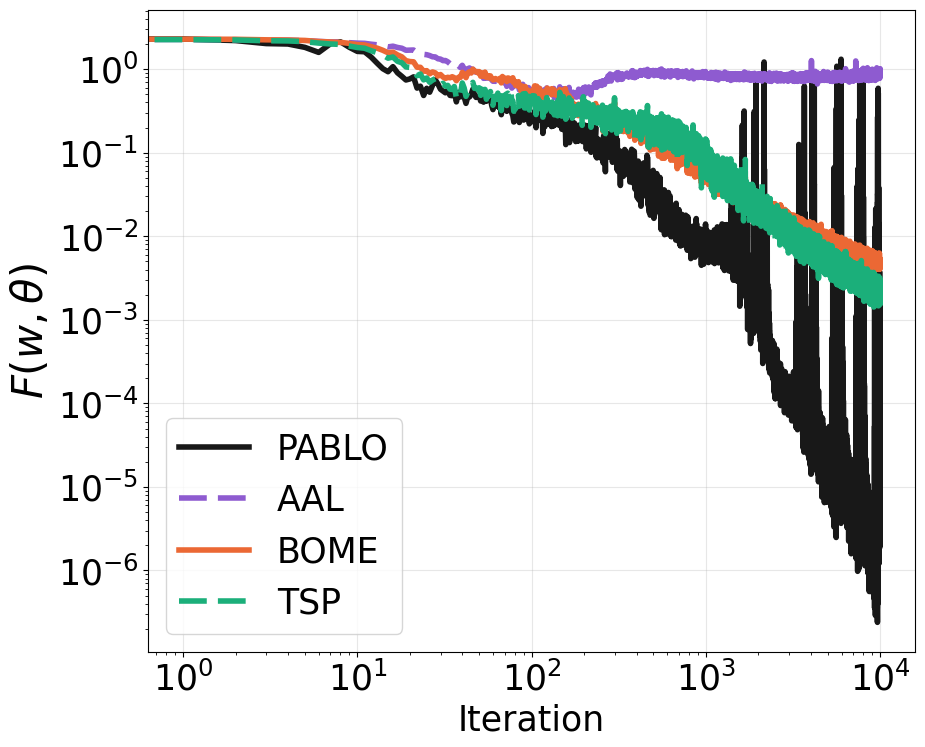

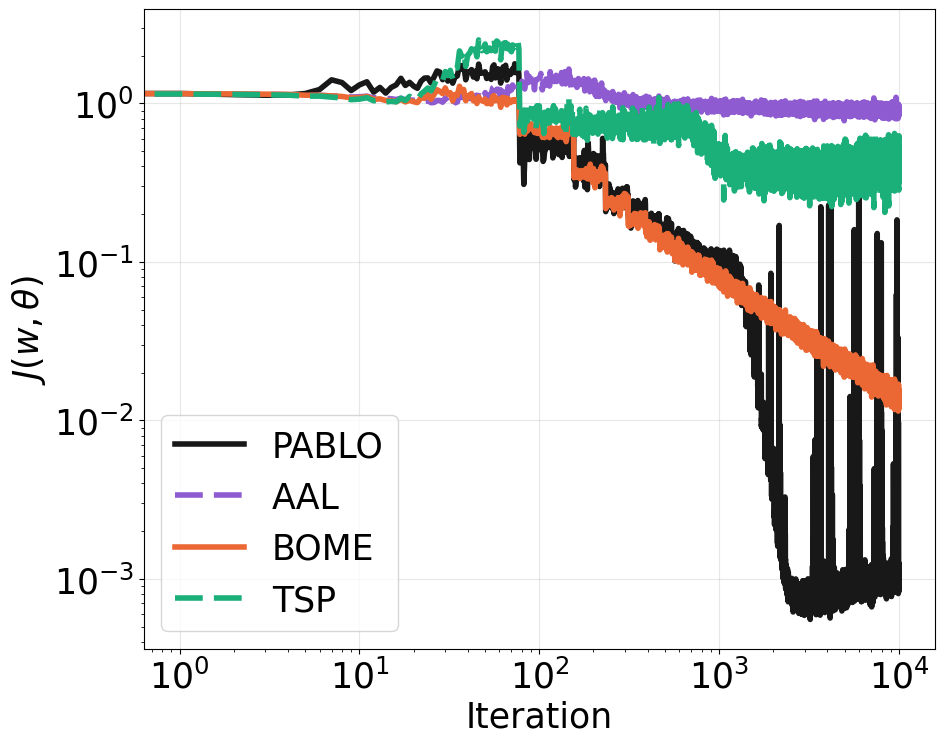

In [152]:
COLOURS = {"PABLO": "#181818", "BOME": "#eb6834", "TSP": "#1baf7a", "STABLE": "#eda100",
           "AID": "#3b7dd8", "AAL": "#8e5bd0", "PBGD-Free": "#d6457a"}
LINESTYLES = {"PABLO": "-", "BOME": "-", "STABLE": "-",
              "TSP": (0, (5, 2)), "AAL": (0, (5, 2)), "PBGD-Free": "--"}

saveplot = False

METHODS_PLOT = all_results_and_seeds[0].keys()
plt.rcParams.update({'font.size': 25})
fig, axes = plt.subplots(1, 1, figsize=(10,8))
for m in METHODS_PLOT:

    test_acc = np.mean([result[m]["history"]["test_accuracy"] for seed, result in all_results_and_seeds.items() ],0)
    iters = range(0, NUM_ITERS+1, EVAL_EVERY)
    axes.plot(iters, test_acc,
                color=COLOURS[m], label=m, linestyle=LINESTYLES[m], linewidth=4)
axes.set_ylabel('Test Accuracy (%)'); 
axes.set_xlabel("Iteration"); 
axes.grid(alpha=0.3)
axes.legend()
axes.set_ylim(axes.get_ylim()[0], axes.get_ylim()[0]+1.)
# axes.set_xlim(-8,200)
axes.set_xscale('log')
if saveplot:
    plt.savefig('MNIST_HyperClean_Test_full.png', dpi=300)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 1, figsize=(10,8))
for m in METHODS_PLOT:
    res = np.mean([ res[m]['history']['ul_loss'] for s, res in all_results_and_seeds.items()],0)
    plt.semilogy(range(len(res)), res,color=COLOURS[m],linestyle=LINESTYLES[m], label=m, linewidth=4)
    # axes.set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3)
axes.legend()
axes.set_ylabel(r'$F(w,\theta)$', fontsize=30) 
axes.set_xlabel("Iteration"); 
axes.grid(alpha=0.3)
# axes.set_xlim(-8,200)
plt.tight_layout()
axes.set_xscale('log')
if saveplot:
    plt.savefig('MNIST_HyperClean_F.png', dpi=300)
plt.show()


fig, axes = plt.subplots(1, 1, figsize=(10,8))
for m in METHODS_PLOT:

    test_acc = np.mean([result[m]["history"]["ll_loss"] for seed, result in all_results_and_seeds.items() ],0)
    axes.semilogy(range(len(res)), test_acc,
                color=COLOURS[m],linestyle=LINESTYLES[m],  label=m, linewidth=4)
    # axes.set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3)
axes.legend()
axes.set_ylabel(r'$J(w,\theta)$') 
axes.set_xlabel("Iteration"); 
axes.grid(alpha=0.3)
axes.set_xscale('log')
plt.tight_layout()
if saveplot:
    plt.savefig('MNIST_HyperClean_J.png', dpi=300)
plt.show()


In [ ]:
print(f"{'method':<10} {'test acc':>9} {'test F1':>9} {'clean F1':>9} {'clean w':>8} {'corrupt w':>10}")
for method, r in results.items():
    h = r["history"]
    print(f"{method:<10} {100*h['test_accuracy'][-1]:8.2f}% {100*h['test_macro_f1'][-1]:8.2f}% "
          f"{100*h['cleaning_f1'][-1]:8.2f}% {h['clean_weight'][-1]:8.3f} {h['corrupted_weight'][-1]:10.3f}"
          + ("" if h["valid"] else "   (diverged)"))

method      test acc   test F1  clean F1  clean w  corrupt w
PABLO         82.30%    82.28%    91.50%    0.749      0.205


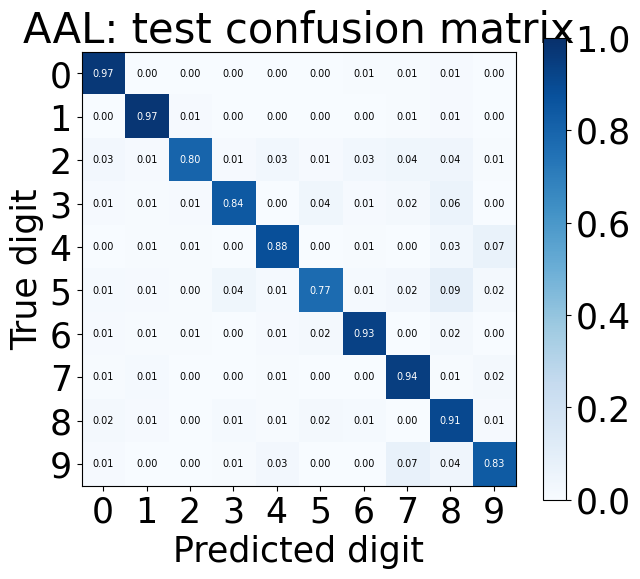

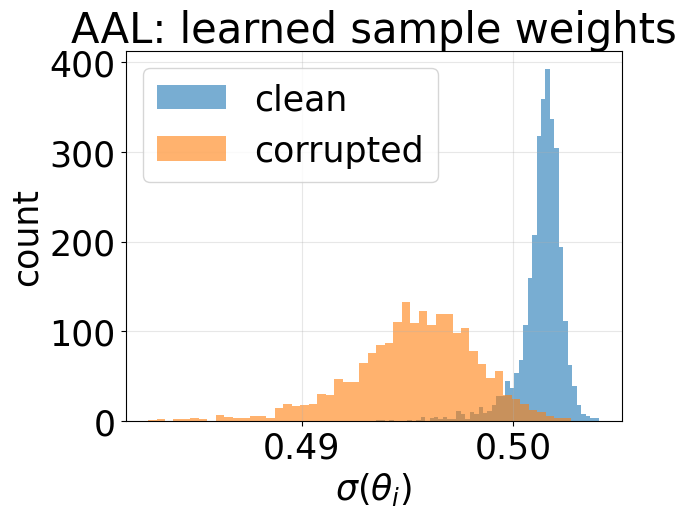

In [106]:
METHOD = "AAL"
_, _, _, confusion = evaluate_classifier(results[METHOD]["classifier"],
                                         torch.utils.data.DataLoader(datasets["test"], batch_size=1000), device)
plot_confusion_matrix(confusion, title=f"{METHOD}: test confusion matrix")
plt.show()

weights = results[METHOD]["weight_model"](torch.arange(N_TRAIN)).detach()
plt.hist(weights[~corrupted_mask].numpy(), bins=50, alpha=0.6, label="clean")
plt.hist(weights[corrupted_mask].numpy(), bins=50, alpha=0.6, label="corrupted")
plt.xlabel(r"$\sigma(\theta_i)$"); plt.ylabel("count"); plt.title(f"{METHOD}: learned sample weights")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# MNIST Conditioning

In [ ]:
SEED_C    = 0
N_OUTER   = 30
N_ITERS_C = 500
LR_W      = 0.05
LR_THETA = 0.1
CG_ITERS  = 50
CG_TOL    = 1e-3
BATCH_SIZE = 64

torch.manual_seed(SEED_C)
cond_classifier = MNISTMLP(seed=SEED_C).to(device)
cond_theta      = SampleWeightModel(N_TRAIN, init_logit=0.0).to(device)
print(cond_theta.raw_theta[0:5])

w_params  = list(cond_classifier.parameters())
data_full = {
    "train": (splits["x_train"].to(device), splits["y_train"].to(device), torch.arange(N_TRAIN, device=device)),
    "val":   (splits["x_val"].to(device),   splits["y_val"].to(device))
}

def hvp(v):
    ll     = lower_loss(cond_classifier, data_full, cond_theta)
    gw     = torch.autograd.grad(ll, w_params, create_graph=True)
    gw_vec = torch.cat([g.flatten() for g in gw])
    Hv     = torch.autograd.grad((gw_vec * v).sum(), w_params)
    return torch.cat([g.flatten() for g in Hv]).detach()

for outer in range(N_OUTER):

    # ── Inner loop: solve min_w J(w, theta) ──────────────────────────────────
    train_iter_c, val_iter_c = make_batch_iterators(datasets["train"], datasets["val"],
                                                    batch_size=BATCH_SIZE, seed=SEED_C + outer)
    opt_w = torch.optim.SGD(w_params, lr=LR_W, momentum=0.9)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt_w, T_max=N_ITERS_C)

    #freeze theta 
    cond_theta.raw_theta.requires_grad_(False)
    cond_theta.raw_theta.grad = None    

    for t in range(1, N_ITERS_C + 1):
        data = get_batch(train_iter_c, val_iter_c, device)
        opt_w.zero_grad()
        loss = lower_loss(cond_classifier, data, cond_theta)
        loss.backward()
        opt_w.step()
        sched.step()
        if t % 500 == 0:
            print(f"outer {outer} | inner {t:4d} | LL={loss.item():.4f} | lr={sched.get_last_lr()[0]:.5f}")

    # ── CG: solve H_ww v = ∇_w F ─────────────────────────────────────────────
    ul_loss = upper_loss(cond_classifier, data_full, cond_theta)
    b = torch.cat([g.flatten() for g in
                   torch.autograd.grad(ul_loss, w_params)]).detach()

    v, r, p = torch.zeros_like(b), b.clone(), b.clone()
    rr = r @ r
    for i in range(CG_ITERS):
        Ap     = hvp(p)
        alpha  = rr / (p @ Ap + 1e-10)
        v      = v + alpha * p
        r      = r - alpha * Ap
        rr_new = r @ r
        p      = r + (rr_new / rr) * p
        rr     = rr_new
        if rr.sqrt() < CG_TOL:
            print(f"  CG converged at iter {i+1}, |r|={rr.sqrt():.2e}")
            break
    
    #unfreeze theta 
    cond_theta.raw_theta.requires_grad_(True)

    # ── Hypergradient: -(∇²_wθ J)^T v ────────────────────────────────────────
    ll2     = lower_loss(cond_classifier, data_full, cond_theta)
    gw2     = torch.autograd.grad(ll2, w_params, create_graph=True)
    gw_vec2 = torch.cat([g.flatten() for g in gw2])
    hypergrad = -torch.autograd.grad(gw_vec2, cond_theta.raw_theta,
                                      grad_outputs=v.detach())[0]
    with torch.no_grad():
        cond_theta.raw_theta.sub_(LR_THETA*hypergrad)
        LR_THETA *= 0.999

    print(f"outer {outer} | hypergrad norm={hypergrad.norm().item():.4f}")

tensor([0., 0., 0., 0., 0.], grad_fn=<SliceBackward0>)
outer 0 | inner  500 | LL=0.8333 | lr=0.00000
outer 0 | hypergrad norm=0.0111
outer 1 | inner  500 | LL=0.8910 | lr=0.00000
outer 1 | hypergrad norm=0.0103
outer 2 | inner  500 | LL=0.7107 | lr=0.00000
outer 2 | hypergrad norm=0.0313
outer 3 | inner  500 | LL=0.5991 | lr=0.00000
outer 3 | hypergrad norm=0.0110
outer 4 | inner  500 | LL=0.5767 | lr=0.00000
outer 4 | hypergrad norm=0.0297
outer 5 | inner  500 | LL=0.5721 | lr=0.00000
outer 5 | hypergrad norm=0.0184
outer 6 | inner  500 | LL=0.4702 | lr=0.00000
outer 6 | hypergrad norm=0.0176
outer 7 | inner  500 | LL=0.3398 | lr=0.00000
outer 7 | hypergrad norm=0.0197
outer 8 | inner  500 | LL=0.2432 | lr=0.00000
outer 8 | hypergrad norm=0.0546
outer 9 | inner  500 | LL=0.2133 | lr=0.00000
outer 9 | hypergrad norm=0.0433
outer 10 | inner  500 | LL=0.1748 | lr=0.00000
outer 10 | hypergrad norm=0.0372
outer 11 | inner  500 | LL=0.1307 | lr=0.00000
outer 11 | hypergrad norm=0.0286
outer

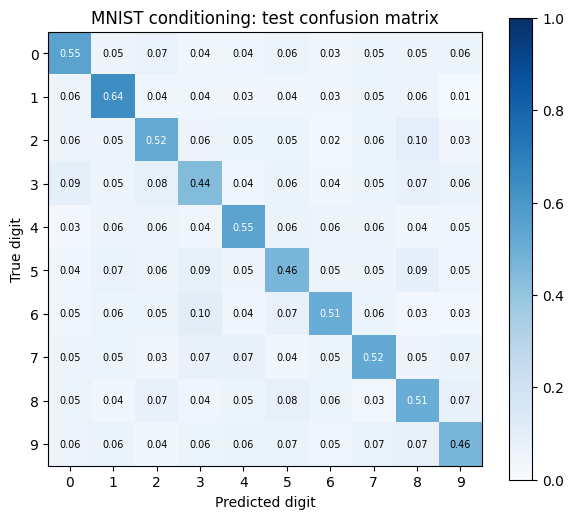

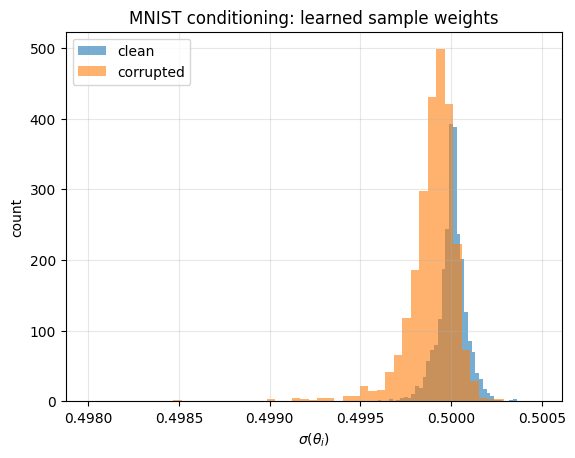

In [39]:
_, _, _, confusion = evaluate_classifier(cond_classifier,
                                         torch.utils.data.DataLoader(datasets["test"], batch_size=1000), device)
plot_confusion_matrix(confusion, title="MNIST conditioning: test confusion matrix")
plt.show()

weights = cond_theta(torch.arange(N_TRAIN)).detach()
plt.hist(weights[~corrupted_mask].numpy(), bins=50, alpha=0.6, label="clean")
plt.hist(weights[corrupted_mask].numpy(), bins=50, alpha=0.6, label="corrupted")
plt.xlabel(r"$\sigma(\theta_i)$"); plt.ylabel("count"); plt.title("MNIST conditioning: learned sample weights")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [36]:
print(cond_theta.raw_theta[0:5])

tensor([-0.0005, -0.0041, -0.0040, -0.0045, -0.0076], grad_fn=<SliceBackward0>)


## CIFAR-10 with a simple CNN

Same experiment as above on CIFAR-10: the same split sizes, corruption fraction, loss functions, `HPARAMS`, `METHODS`,
`NUM_ITERS`, `BATCH_SIZE` and `SEED`. Only the data and the lower-level model change. The classifier is the 3-layer CNN
from `ShelleyCode/CIFARComparison.ipynb`.

* `HPARAMS` were tuned on MNIST with the MLP, not on this problem.
* The first run downloads CIFAR-10 (about 170 MB) into `DATA_ROOT`.

In [171]:
from data_utils import load_corrupted_cifar10

class CIFARClassifier(nn.Module):
    """Lower-level model w: small CNN (from ShelleyCode/CIFARComparison.ipynb)"""
    def __init__(self, seed:int=None):
        super().__init__()
        if seed is not None:
            torch.manual_seed(seed)
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 10))

    def forward(self, images):
        return self.net(images)


# N_TRAIN, N_VAL, N_TEST
splits_cifar = load_corrupted_cifar10(n_train=N_TRAIN, n_val=N_VAL, n_test=N_TEST,
                                      corruption_frac=CORRUPTION_FRAC, seed=DATA_SEED, root=DATA_ROOT)
datasets_cifar = make_datasets(splits_cifar)
corrupted_mask_cifar = splits_cifar["corrupted_mask"]

assert torch.equal(corrupted_mask_cifar, splits_cifar["y_train"] != splits_cifar["y_train_clean"])
print("Train / val / test:", len(datasets_cifar["train"]), len(datasets_cifar["val"]), len(datasets_cifar["test"]))
print(f"Corrupted training labels: {corrupted_mask_cifar.sum().item()} ({100 * corrupted_mask_cifar.float().mean().item():.1f}%)")

Train / val / test: 4992 4992 10000
Corrupted training labels: 2496 (50.0%)


PABLO        100 | LL=0.9459 | UL=1.9241 | test acc=27.66% | clean w=0.418 | corrupt w=0.402 | cleaning F1=59.01% | 40s
PABLO        200 | LL=0.8426 | UL=1.7270 | test acc=31.28% | clean w=0.365 | corrupt w=0.332 | cleaning F1=61.85% | 80s
PABLO        300 | LL=0.7607 | UL=1.4842 | test acc=42.70% | clean w=0.316 | corrupt w=0.267 | cleaning F1=64.43% | 120s
PABLO        400 | LL=0.5323 | UL=1.6953 | test acc=38.18% | clean w=0.275 | corrupt w=0.213 | cleaning F1=65.73% | 160s
PABLO        500 | LL=0.5316 | UL=1.6578 | test acc=45.32% | clean w=0.237 | corrupt w=0.169 | cleaning F1=66.66% | 200s
PABLO        600 | LL=0.3363 | UL=1.3258 | test acc=49.01% | clean w=0.203 | corrupt w=0.134 | cleaning F1=67.24% | 240s
PABLO        700 | LL=0.3119 | UL=1.3159 | test acc=50.77% | clean w=0.178 | corrupt w=0.103 | cleaning F1=67.62% | 278s
PABLO        800 | LL=0.1680 | UL=1.0171 | test acc=50.13% | clean w=0.156 | corrupt w=0.079 | cleaning F1=67.57% | 316s
PABLO        900 | LL=0.1475 | UL=

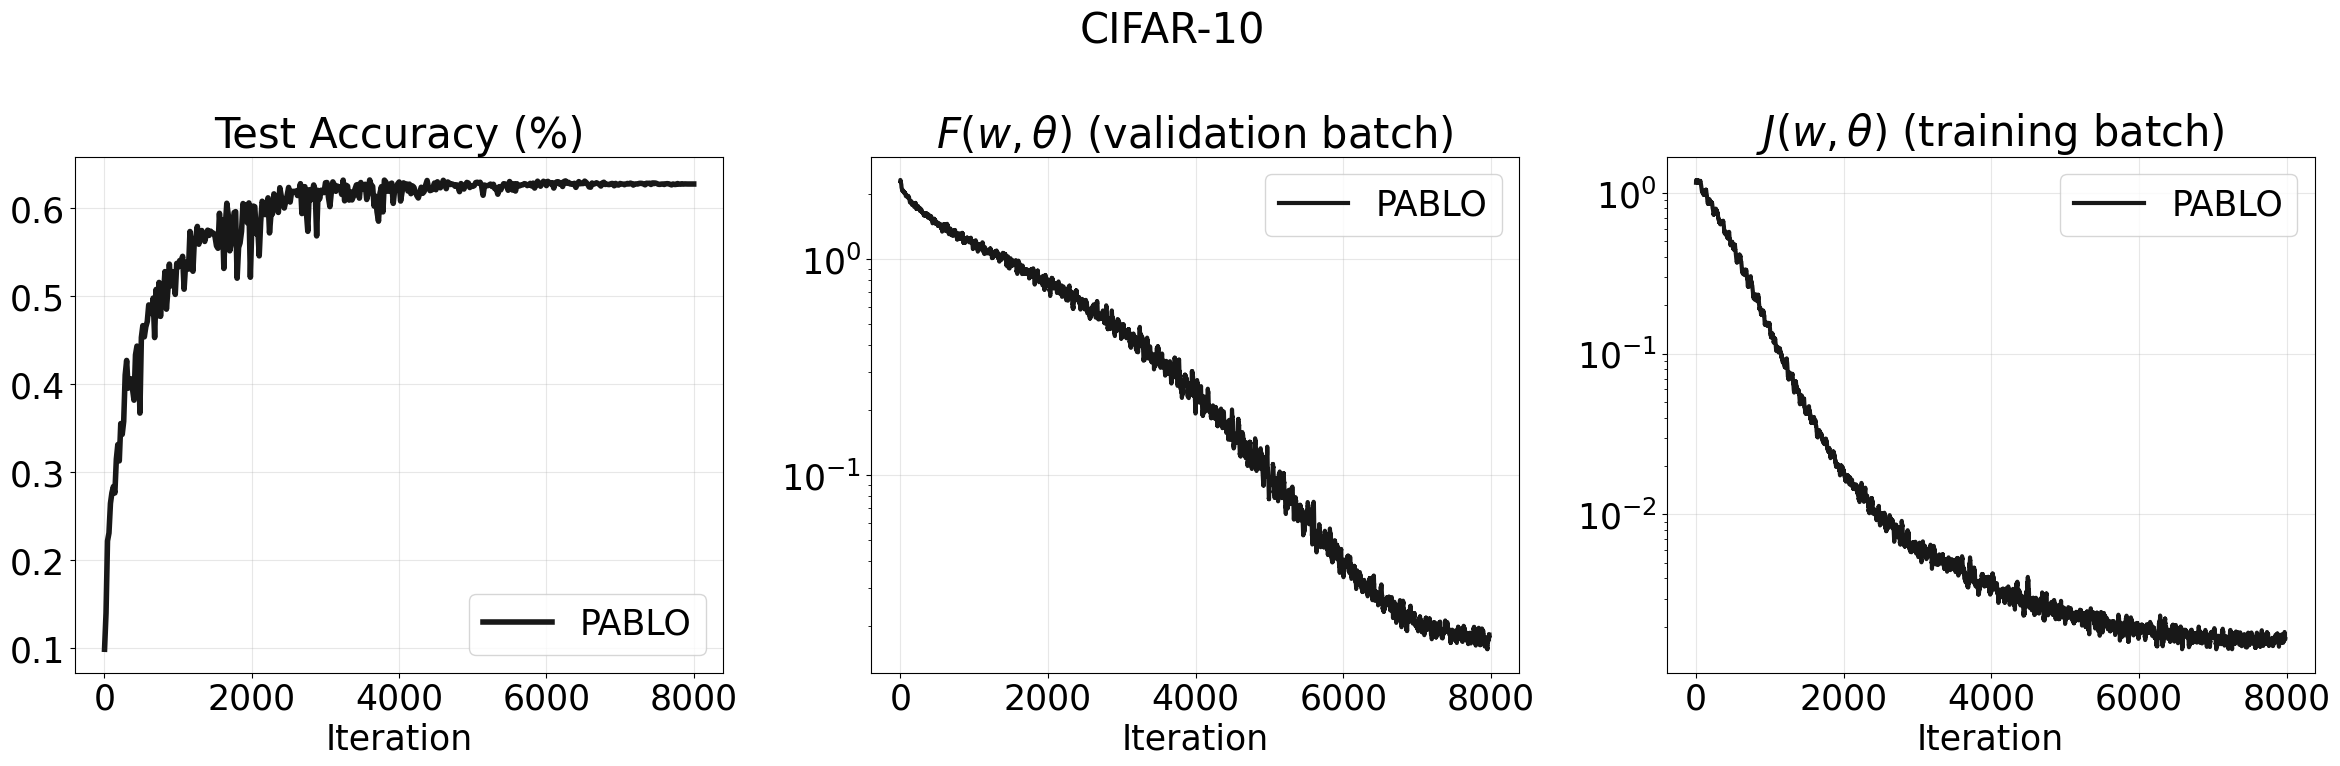

method      test acc   test F1  clean F1  clean w  corrupt w
PABLO         62.76%    62.79%    69.91%    0.149      0.003
BOME         100 | LL=1.1291 | UL=1.8808 | test acc=25.66% | clean w=0.488 | corrupt w=0.480 | cleaning F1=58.42% | 61s
BOME         200 | LL=1.0004 | UL=1.7952 | test acc=35.13% | clean w=0.474 | corrupt w=0.444 | cleaning F1=63.94% | 119s
BOME         300 | LL=0.9908 | UL=1.6868 | test acc=33.07% | clean w=0.458 | corrupt w=0.406 | cleaning F1=66.26% | 177s
BOME         400 | LL=0.9399 | UL=1.5344 | test acc=42.09% | clean w=0.438 | corrupt w=0.362 | cleaning F1=67.26% | 235s
BOME         500 | LL=0.8423 | UL=1.5107 | test acc=43.09% | clean w=0.418 | corrupt w=0.321 | cleaning F1=67.92% | 293s
BOME         600 | LL=0.7055 | UL=1.4324 | test acc=47.77% | clean w=0.396 | corrupt w=0.283 | cleaning F1=67.97% | 351s
BOME         700 | LL=0.6442 | UL=1.2434 | test acc=54.69% | clean w=0.377 | corrupt w=0.248 | cleaning F1=68.11% | 409s
BOME         800 | LL=0.4695 | U

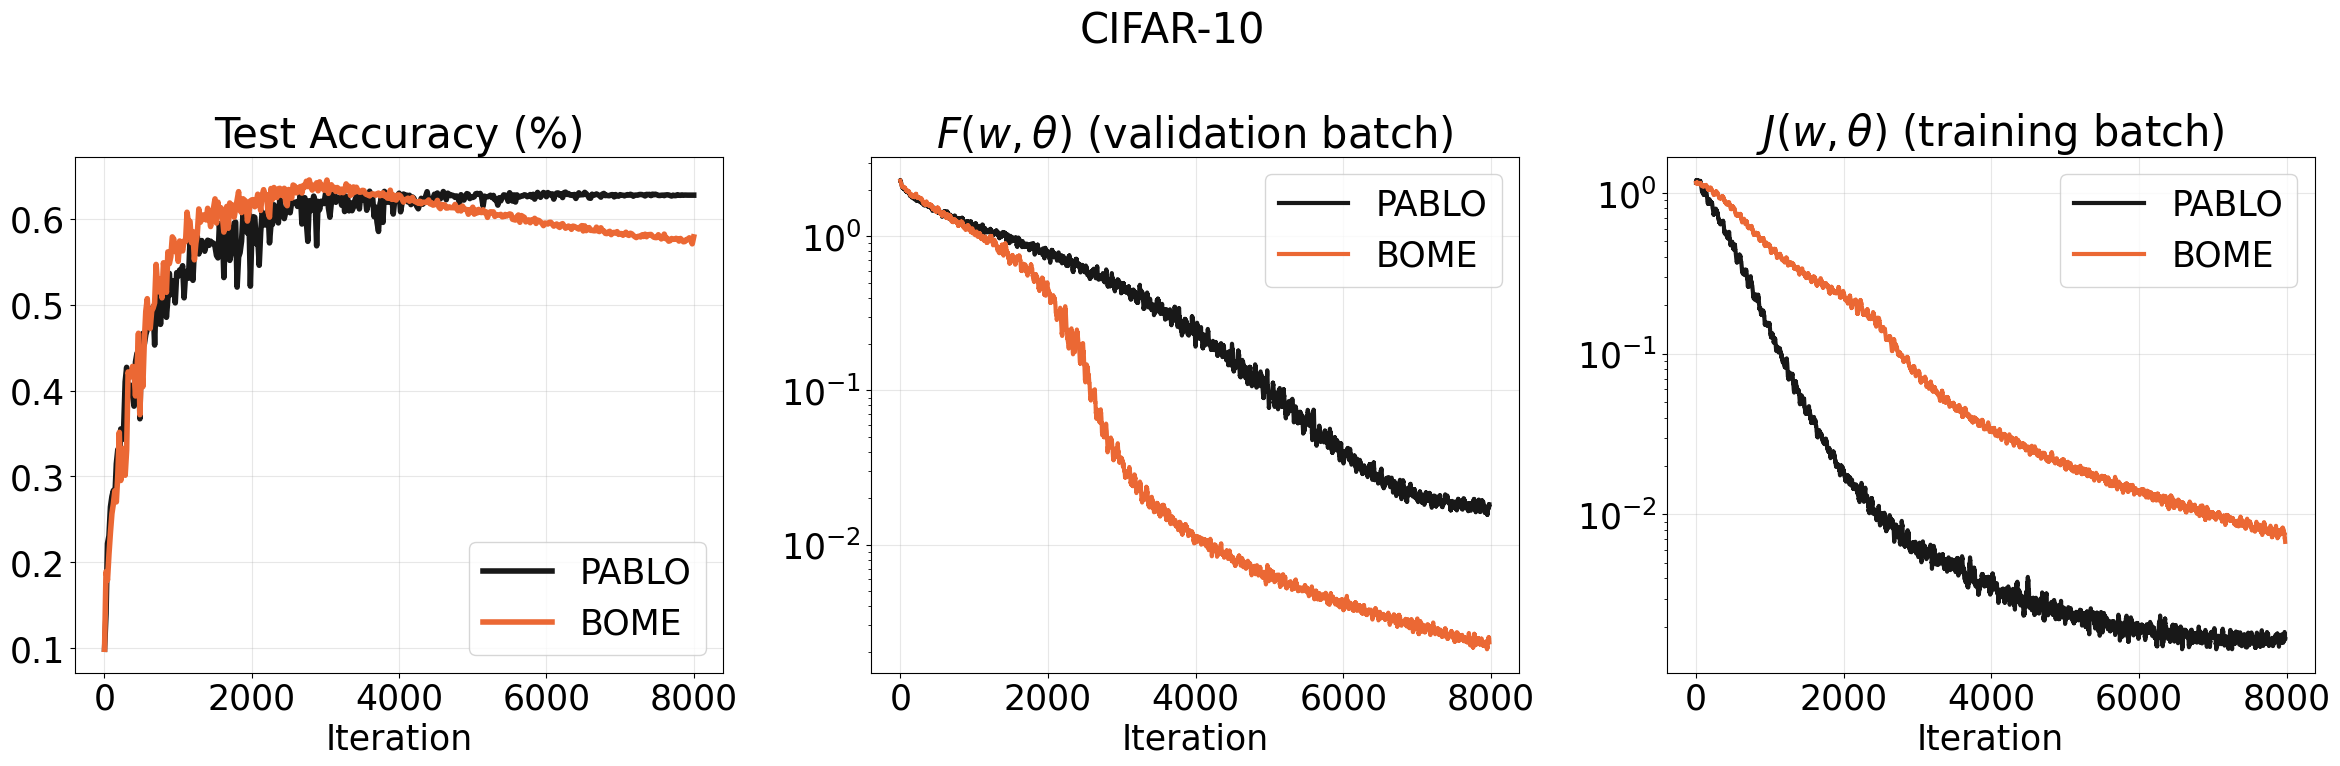

method      test acc   test F1  clean F1  clean w  corrupt w
BOME          62.76%    62.79%    69.91%    0.149      0.003
BOME          57.90%    57.79%    67.40%    0.185      0.016
TSP          100 | LL=1.0804 | UL=1.8902 | test acc=29.51% | clean w=0.517 | corrupt w=0.474 | cleaning F1=57.32% | 33s
TSP          200 | LL=1.2316 | UL=1.7998 | test acc=35.28% | clean w=0.521 | corrupt w=0.453 | cleaning F1=62.93% | 64s
TSP          300 | LL=1.2516 | UL=1.5858 | test acc=38.65% | clean w=0.521 | corrupt w=0.453 | cleaning F1=63.01% | 94s
TSP          400 | LL=1.2530 | UL=1.7260 | test acc=36.07% | clean w=0.521 | corrupt w=0.452 | cleaning F1=63.23% | 125s
TSP          500 | LL=1.3708 | UL=1.8903 | test acc=31.47% | clean w=0.522 | corrupt w=0.441 | cleaning F1=65.08% | 156s
TSP          600 | LL=1.1093 | UL=1.5619 | test acc=42.35% | clean w=0.524 | corrupt w=0.416 | cleaning F1=68.11% | 187s
TSP          700 | LL=1.0631 | UL=1.5438 | test acc=45.35% | clean w=0.529 | corrupt w=0.389 |

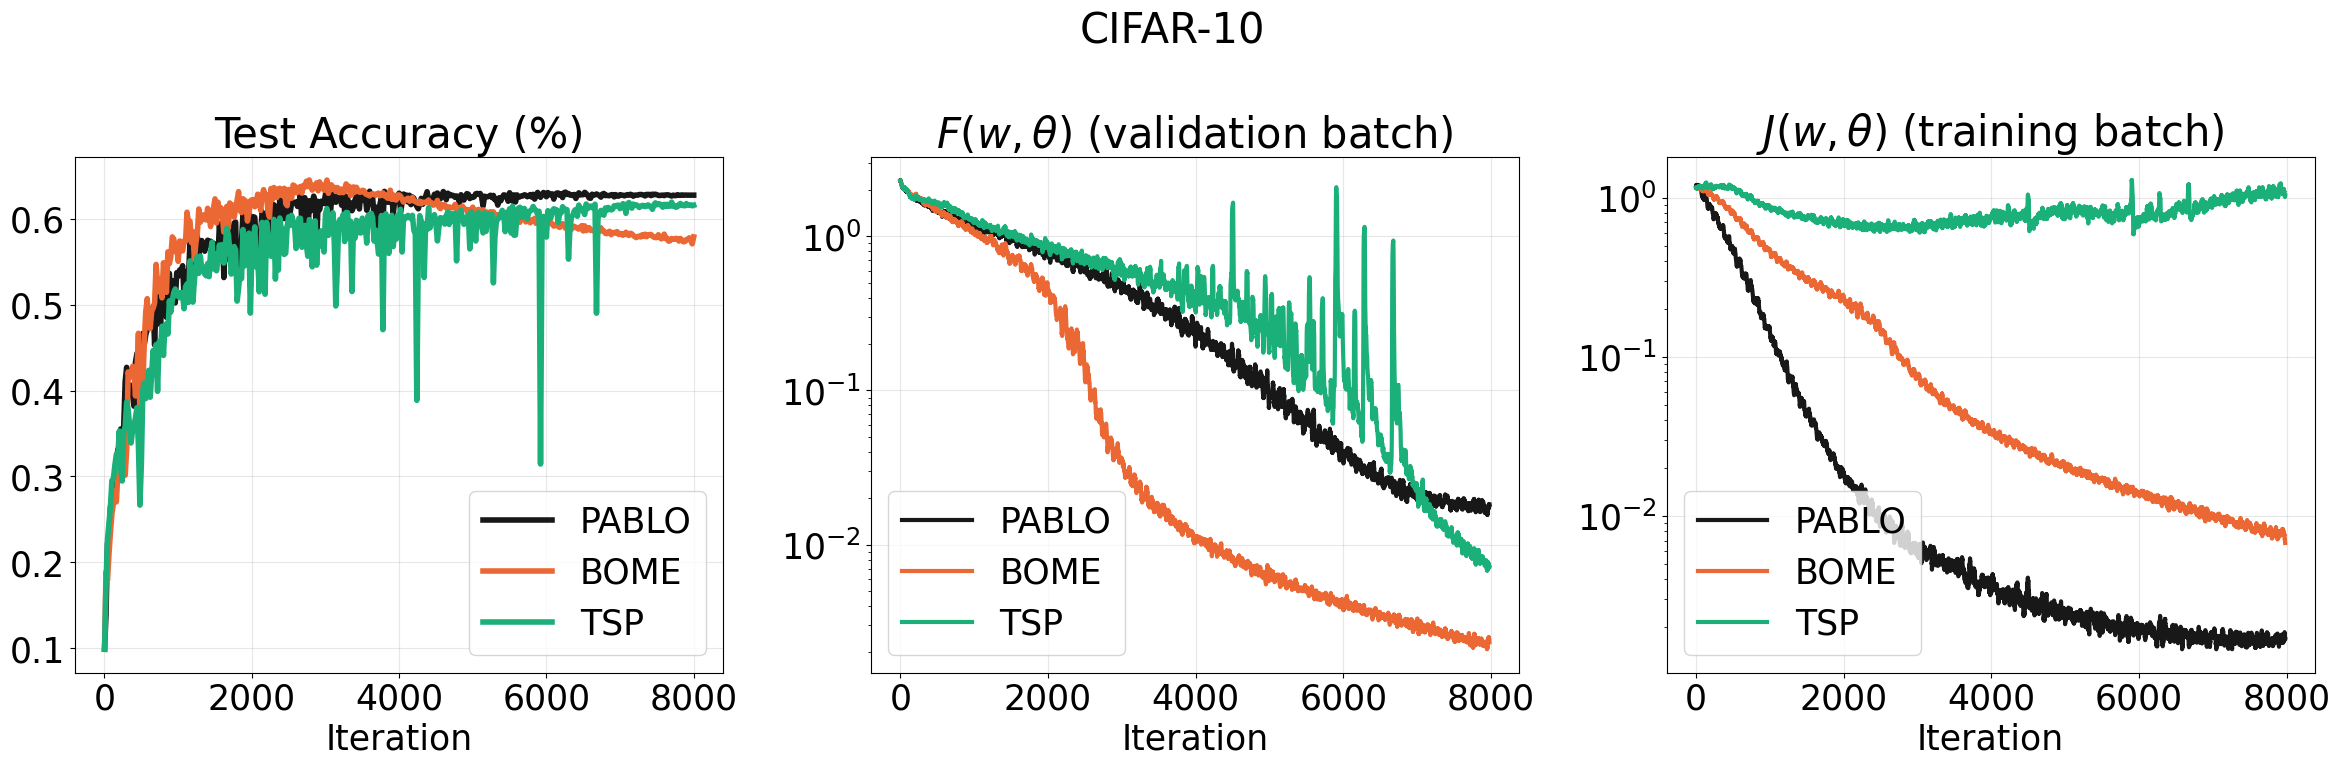

method      test acc   test F1  clean F1  clean w  corrupt w
TSP           62.76%    62.79%    69.91%    0.149      0.003
TSP           57.90%    57.79%    67.40%    0.185      0.016
TSP           61.58%    61.54%    77.47%    0.504      0.153
AAL          100 | LL=1.1181 | UL=2.0262 | test acc=24.82% | clean w=0.500 | corrupt w=0.500 | cleaning F1=58.05% | 30s
AAL          200 | LL=1.1340 | UL=2.0142 | test acc=26.59% | clean w=0.500 | corrupt w=0.500 | cleaning F1=63.52% | 57s
AAL          300 | LL=1.1633 | UL=1.7506 | test acc=32.70% | clean w=0.500 | corrupt w=0.500 | cleaning F1=66.57% | 85s
AAL          400 | LL=1.1758 | UL=1.8014 | test acc=35.06% | clean w=0.500 | corrupt w=0.500 | cleaning F1=68.25% | 113s
AAL          500 | LL=1.2143 | UL=1.8407 | test acc=30.25% | clean w=0.500 | corrupt w=0.500 | cleaning F1=69.68% | 141s
AAL          600 | LL=1.1367 | UL=1.7969 | test acc=36.15% | clean w=0.500 | corrupt w=0.499 | cleaning F1=70.81% | 168s
AAL          700 | LL=1.1125 | UL

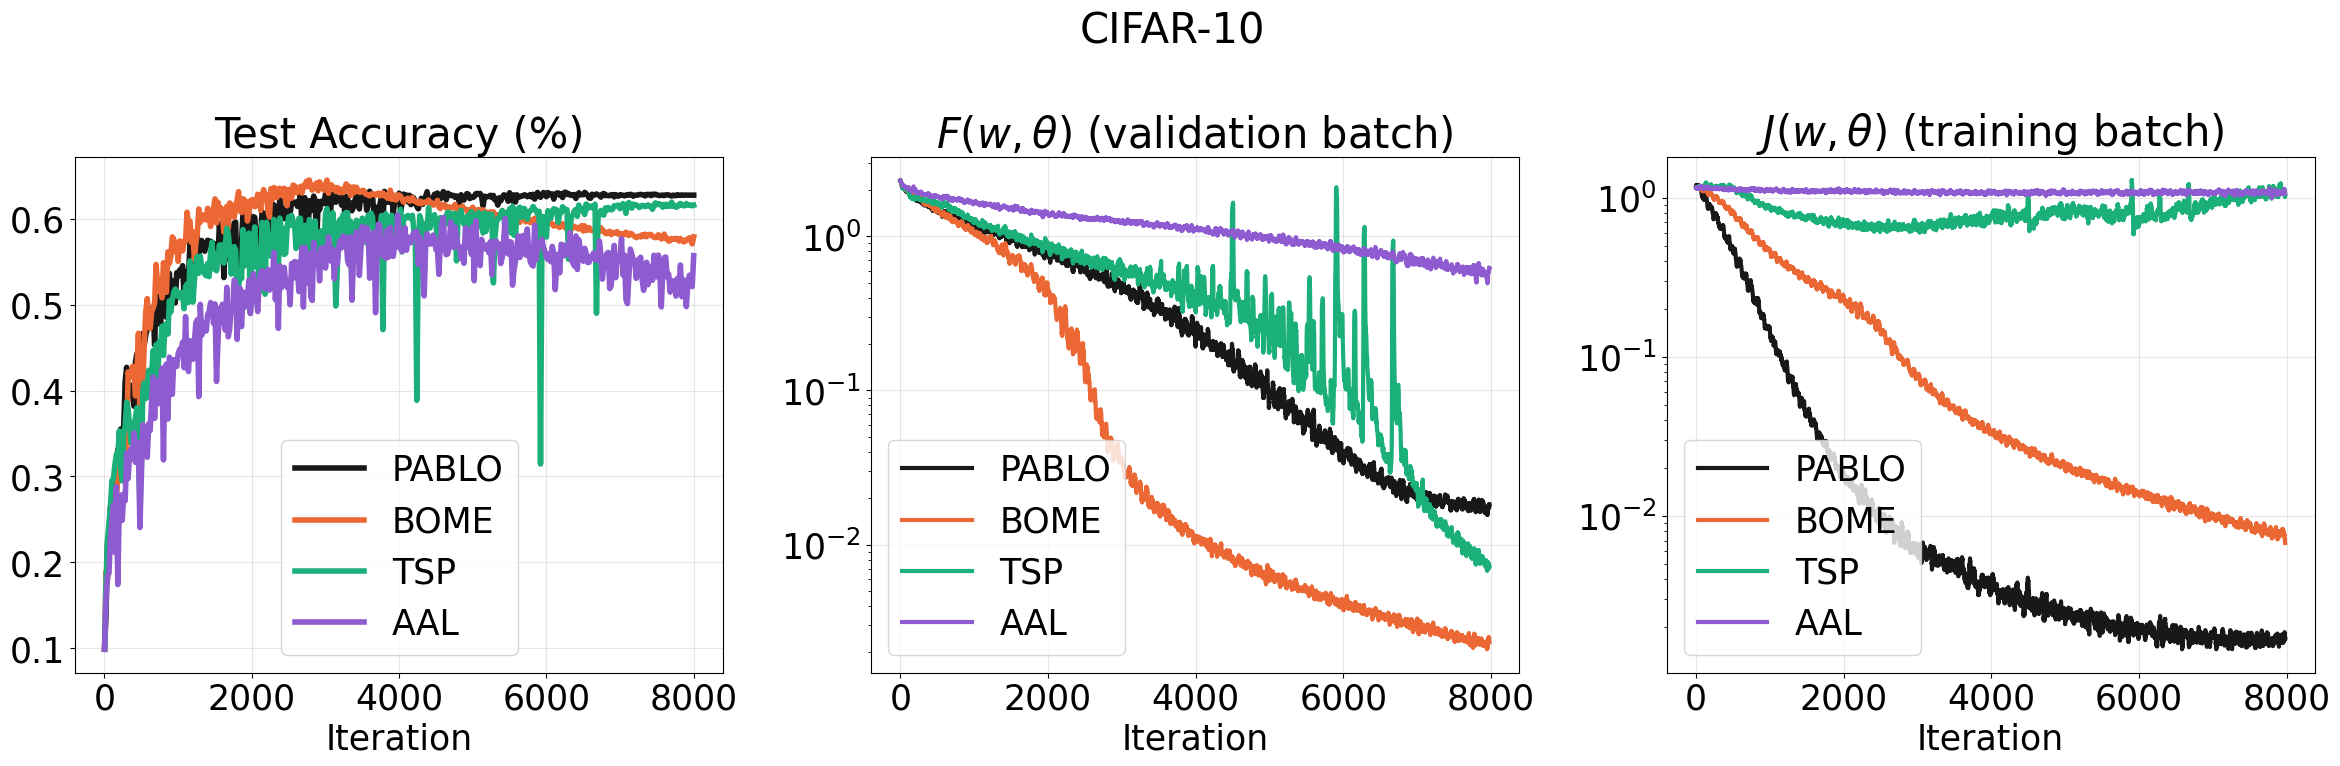

method      test acc   test F1  clean F1  clean w  corrupt w
AAL           62.76%    62.79%    69.91%    0.149      0.003
AAL           57.90%    57.79%    67.40%    0.185      0.016
AAL           61.58%    61.54%    77.47%    0.504      0.153
AAL           55.71%    54.97%    84.86%    0.506      0.482


In [176]:
SEED = 0
BATCH_SIZE=64
NUM_ITERS = 8000
EVAL_EVERY = 20


# All params manually tuned already
HPARAMS = {
    "PABLO": dict(lr_w=0.002, lr_theta=0.1, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001,tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=10.0, warmup_ratio=10/NUM_ITERS, total_steps=NUM_ITERS),
    "BOME": dict(opt="sgdm", inner_steps=10, inner_lr=0.33, eta=2.1, lr_w=0.06, lr_theta=5.0, barrier="grad_norm"),
    "TSP": dict(gamma=2, delta=0.0, p=1e-4, eta=0.1, beta=.14, alpha=200., tau=0.67, theta=0.01, mu=0.05, omega=0.999, lambda_init=1.),
    "AAL": dict(rho0=0.01, alpha=0.000, eps=1e-6, t=5, tau=0.1),
}

METHODS = ["PABLO", "BOME", "TSP", "AAL"]

methods_to_plot = []

results_cifar = {}
for method in METHODS:
    classifier = CIFARClassifier(seed=SEED).to(device)
    weight_model = SampleWeightModel(N_TRAIN).to(device)
    optimiser = build_optimiser(method, classifier, weight_model)

    history = run_hypercleaning(optimiser, classifier, weight_model, datasets_cifar, corrupted_mask_cifar,
                                num_iters=NUM_ITERS, batch_size=BATCH_SIZE, seed=SEED,
                                eval_every=EVAL_EVERY, print_every=100, device=device, name=method)
    results_cifar[method] = {"history": history, "classifier": classifier, "weight_model": weight_model}
    print()


    # ------ PLOT ------
    methods_to_plot.append(method)
    fig, axes = plt.subplots(1, 3, figsize=(24,8))

    for m2p in methods_to_plot:
        h = results_cifar[m2p]["history"]
        axes[0].plot([i+1 for i in h["eval_iterations"]], h["test_accuracy"], color=COLOURS[m2p], label=m2p, linewidth=4)
    axes[0].set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3); axes[0].legend()

    for ax, (key, title) in zip(axes[1:], [("ul_loss", r"$F(w,\theta)$ (validation batch)"), ("ll_loss", r"$J(w,\theta)$ (training batch)")]):
        for m2p in methods_to_plot:
            plot_metric(results_cifar[m2p]["history"][key],linewidth=3, plot_type="mov", mean_window=20, logy=True, marker="-", ax=ax)
            ax.lines[-1].set_color(COLOURS[m2p]); ax.lines[-1].set_label(m2p)
        ax.set_title(title); ax.set_xlabel("Iteration"); ax.grid(alpha=0.3)
        ax.legend()

    fig.suptitle("CIFAR-10")
    plt.tight_layout()
    plt.show()

    print(f"{'method':<10} {'test acc':>9} {'test F1':>9} {'clean F1':>9} {'clean w':>8} {'corrupt w':>10}")
    for m2p in methods_to_plot:
        h = results_cifar[m2p]["history"]
        print(f"{method:<10} {100*h['test_accuracy'][-1]:8.2f}% {100*h['test_macro_f1'][-1]:8.2f}% "
        
            f"{100*h['cleaning_f1'][-1]:8.2f}% {h['clean_weight'][-1]:8.3f} {h['corrupted_weight'][-1]:10.3f}"
            + ("" if h["valid"] else "   (diverged)"))

In [ ]:
import json
from datetime import datetime

save_data = True
today = datetime.now().strftime("%Y-%m-%d-%h-%m")

if save_data:
    histories_only = {
        method_name: content["history"] 
        for method_name, content in results_cifar.items()
    }

    # 2. Dump the filtered dictionary to a JSON file
    with open(f"cifar_hypercleaning_results_{today}.json", "w") as f:
        json.dump(histories_only, f, indent=4)

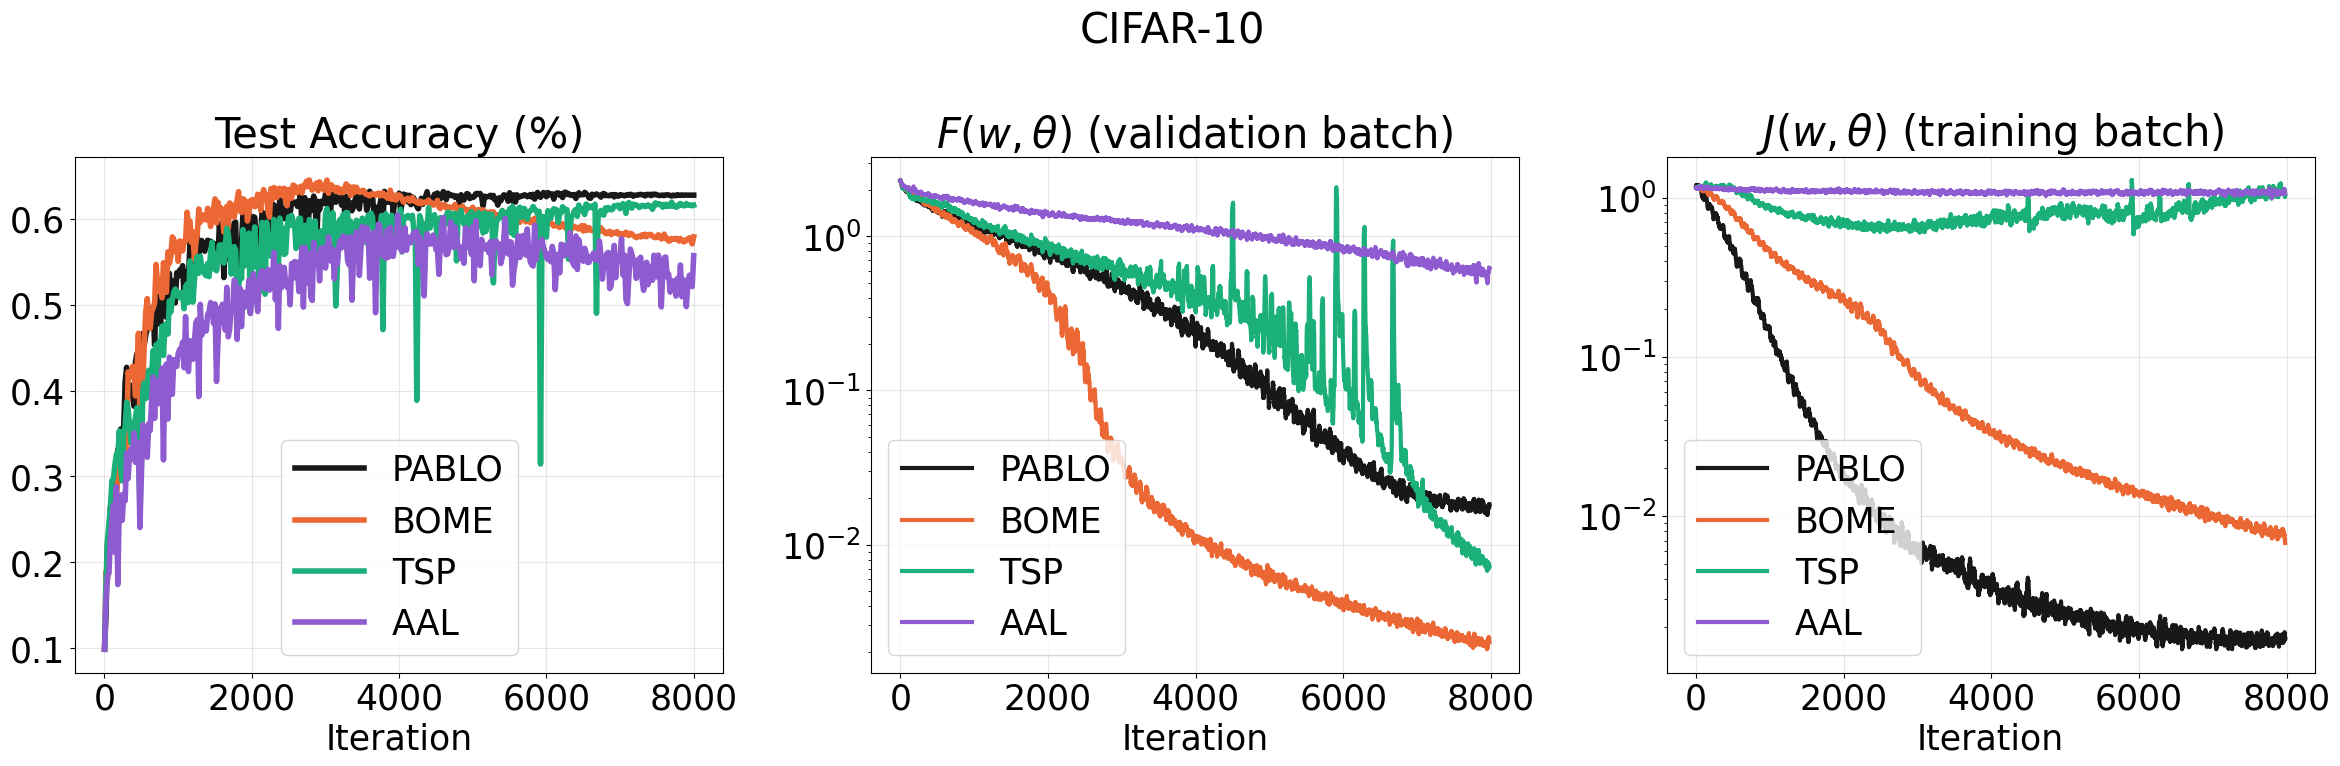

method      test acc   test F1  clean F1  clean w  corrupt w
PABLO         62.76%    62.79%    69.91%    0.149      0.003
BOME          57.90%    57.79%    67.40%    0.185      0.016
TSP           61.58%    61.54%    77.47%    0.504      0.153
AAL           55.71%    54.97%    84.86%    0.506      0.482


In [185]:
fig, axes = plt.subplots(1, 3, figsize=(24,8))

for method, r in results_cifar.items():
    h = r["history"]
    axes[0].plot([i+1 for i in h["eval_iterations"]], h["test_accuracy"], color=COLOURS[method], label=method, linewidth=4)
axes[0].set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3); axes[0].legend()

for ax, (key, title) in zip(axes[1:], [("ul_loss", r"$F(w,\theta)$ (validation batch)"), ("ll_loss", r"$J(w,\theta)$ (training batch)")]):
    for method, r in results_cifar.items():
        plot_metric(r["history"][key],linewidth=3, plot_type="mov", mean_window=20, logy=True, marker="-", ax=ax)
        ax.lines[-1].set_color(COLOURS[method]); ax.lines[-1].set_label(method)
    ax.set_title(title); ax.set_xlabel("Iteration"); ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("CIFAR-10")
plt.tight_layout()
plt.show()

print(f"{'method':<10} {'test acc':>9} {'test F1':>9} {'clean F1':>9} {'clean w':>8} {'corrupt w':>10}")
for method, r in results_cifar.items():
    h = r["history"]
    print(f"{method:<10} {100*h['test_accuracy'][-1]:8.2f}% {100*h['test_macro_f1'][-1]:8.2f}% "
    
          f"{100*h['cleaning_f1'][-1]:8.2f}% {h['clean_weight'][-1]:8.3f} {h['corrupted_weight'][-1]:10.3f}"
          + ("" if h["valid"] else "   (diverged)"))

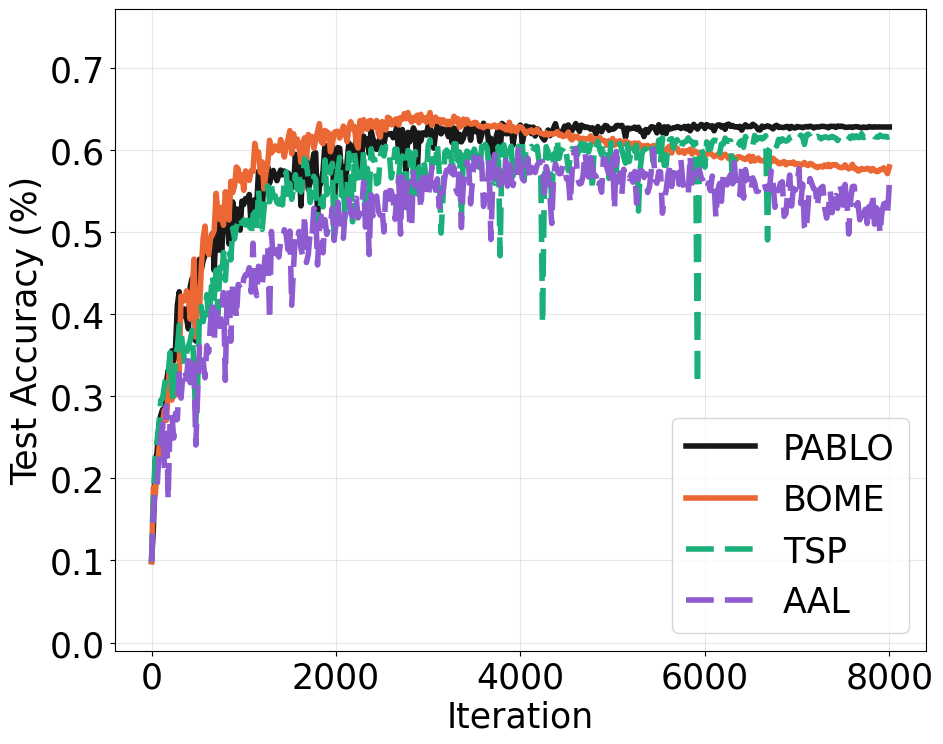

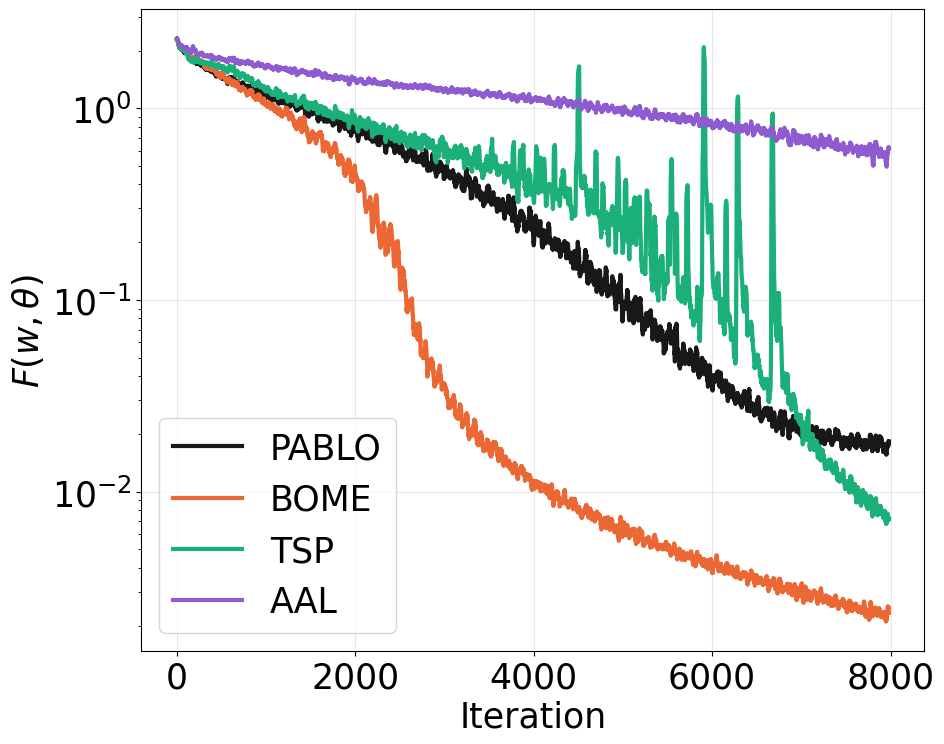

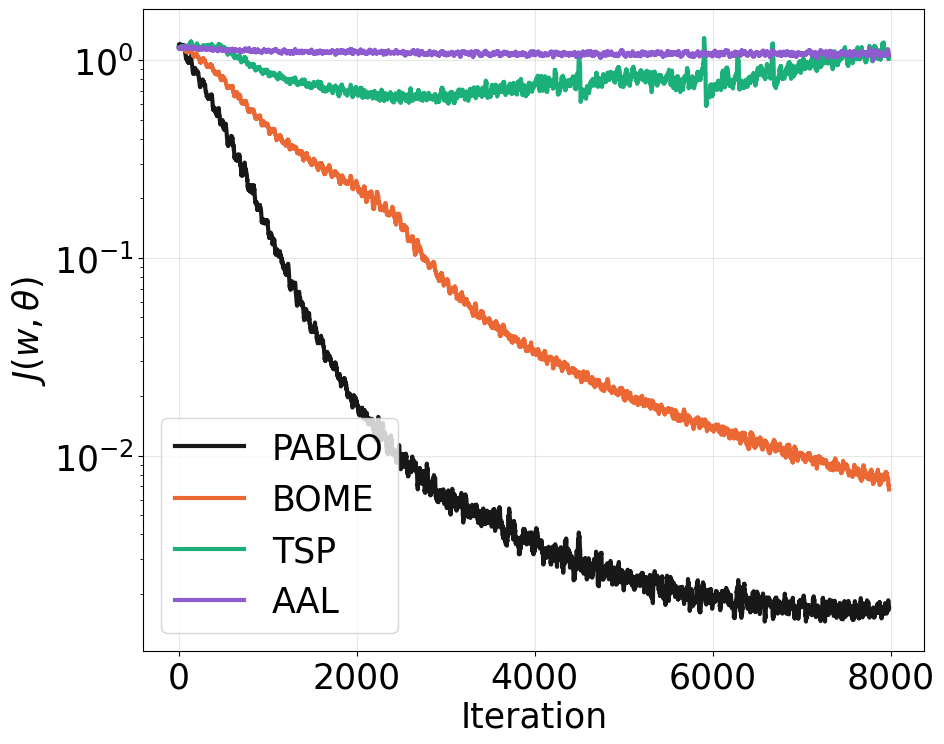

In [ ]:
COLOURS = {"PABLO": "#181818", "BOME": "#eb6834", "TSP": "#1baf7a", "STABLE": "#eda100",
           "AID": "#3b7dd8", "AAL": "#8e5bd0", "PBGD-Free": "#d6457a"}
LINESTYLES = {"PABLO": "-", "BOME": "-", "STABLE": "-",
              "TSP": (0, (5, 2)), "AAL": (0, (5, 2)), "PBGD-Free": "--"}

saveplot = False

METHODS_PLOT = results_cifar.keys()

plt.rcParams.update({'font.size': 25})
fig, axes = plt.subplots(1, 1, figsize=(10,8))
for m in METHODS_PLOT:

    test_acc = np.mean([results_cifar[m]["history"]["test_accuracy"] for seed, result in all_results_and_seeds.items() ],0)
    iters = range(0, NUM_ITERS+1, EVAL_EVERY)
    axes.plot(iters, test_acc,
                color=COLOURS[m], label=m, linestyle=LINESTYLES[m], linewidth=4)
axes.set_ylabel('Test Accuracy (%)'); 
axes.set_xlabel("Iteration"); 
axes.grid(alpha=0.3)
axes.legend()
axes.set_ylim(-0.01, axes.get_ylim()[0]+0.7)
# axes.set_xlim(-8,200)
# axes.set_xscale('log')
if saveplot:
    plt.savefig('CIFAR_HyperClean_Test_full.png', dpi=300)
plt.tight_layout()
plt.show()


for (key, title) in [("ul_loss", r"$F(w,\theta)$"), ("ll_loss", r"$J(w,\theta)$")]:
    fig, ax = plt.subplots(1, 1, figsize=(10,8))
    for method, r in results_cifar.items():
        plot_metric(r["history"][key],linewidth=3, plot_type="mov", mean_window=20, logy=True, marker="-", ax=ax)
        ax.lines[-1].set_color(COLOURS[method]); ax.lines[-1].set_label(method)
    ax.set_ylabel(title); 
    ax.set_xlabel("Iteration"); 
    ax.grid(alpha=0.3)
    ax.legend()
    if saveplot:
        plt.savefig(f'CIFAR_HyperClean_{key}_full.png', dpi=300)
    plt.tight_layout()
    plt.show()




# fig, axes = plt.subplots(1, 1, figsize=(10,8))
# for m in METHODS_PLOT:
#     res = np.mean([ res[m]['history']['ul_loss'] for res in results_cifar.keys()],0)
#     plt.semilogy(range(len(res)), res,color=COLOURS[m],linestyle=LINESTYLES[m], label=m, linewidth=4)
#     # axes.set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3)
# axes.legend()
# axes.set_ylabel(r'$F(w,\theta)$', fontsize=30) 
# axes.set_xlabel("Iteration"); 
# axes.grid(alpha=0.3)
# # axes.set_xlim(-8,200)
# plt.tight_layout()
# axes.set_xscale('log')
# if saveplot:
#     plt.savefig('CIFAR_HyperClean_F.png', dpi=300)
# plt.show()


# fig, axes = plt.subplots(1, 1, figsize=(10,8))
# for m in METHODS_PLOT:

#     test_acc = np.mean([result[m]["history"]["ll_loss"] for seed, result in results_cifar.items() ],0)
#     axes.semilogy(range(len(res)), test_acc,
#                 color=COLOURS[m],linestyle=LINESTYLES[m],  label=m, linewidth=4)
#     # axes.set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3)
# axes.legend()
# axes.set_ylabel(r'$J(w,\theta)$') 
# axes.set_xlabel("Iteration"); 
# axes.grid(alpha=0.3)
# axes.set_xscale('log')
# plt.tight_layout()
# if saveplot:
#     plt.savefig('CIFAR_HyperClean_J.png', dpi=300)
# plt.show()


In [165]:
ITER_COMP_TOL = 2
def ScoreCurve(results, window:int=100)->float:
    ll = np.asarray(results['mean_ll_loss'])
    ul = np.asarray(results['mean_ul_loss'])
    auc = np.mean(np.log10(ll.clip(1e-16))) + np.mean(np.log10(ul.clip(1e-16)))
    mask = (ll < ITER_COMP_TOL) & (ul < ITER_COMP_TOL)
    iter_comp = int(np.argmax(mask)) if mask.any() else None
    return iter_comp, auc

def ScoreTest(test_curve, window:int=None)->float:
    if window:
        return np.mean(test_curve[-window:])
    return max(test_curve)

AAL          100 | LL=1.1463 | UL=2.2812 | test acc=12.27% | clean w=0.500 | corrupt w=0.500 | cleaning F1=55.92% | 26s
AAL          200 | LL=1.1228 | UL=2.2495 | test acc=15.11% | clean w=0.500 | corrupt w=0.500 | cleaning F1=53.64% | 52s
AAL          300 | LL=1.1310 | UL=2.1536 | test acc=19.48% | clean w=0.500 | corrupt w=0.500 | cleaning F1=54.32% | 77s
AAL          400 | LL=1.1634 | UL=2.1276 | test acc=21.35% | clean w=0.500 | corrupt w=0.500 | cleaning F1=51.10% | 103s
AAL          500 | LL=1.1262 | UL=2.1661 | test acc=22.53% | clean w=0.500 | corrupt w=0.500 | cleaning F1=53.84% | 130s



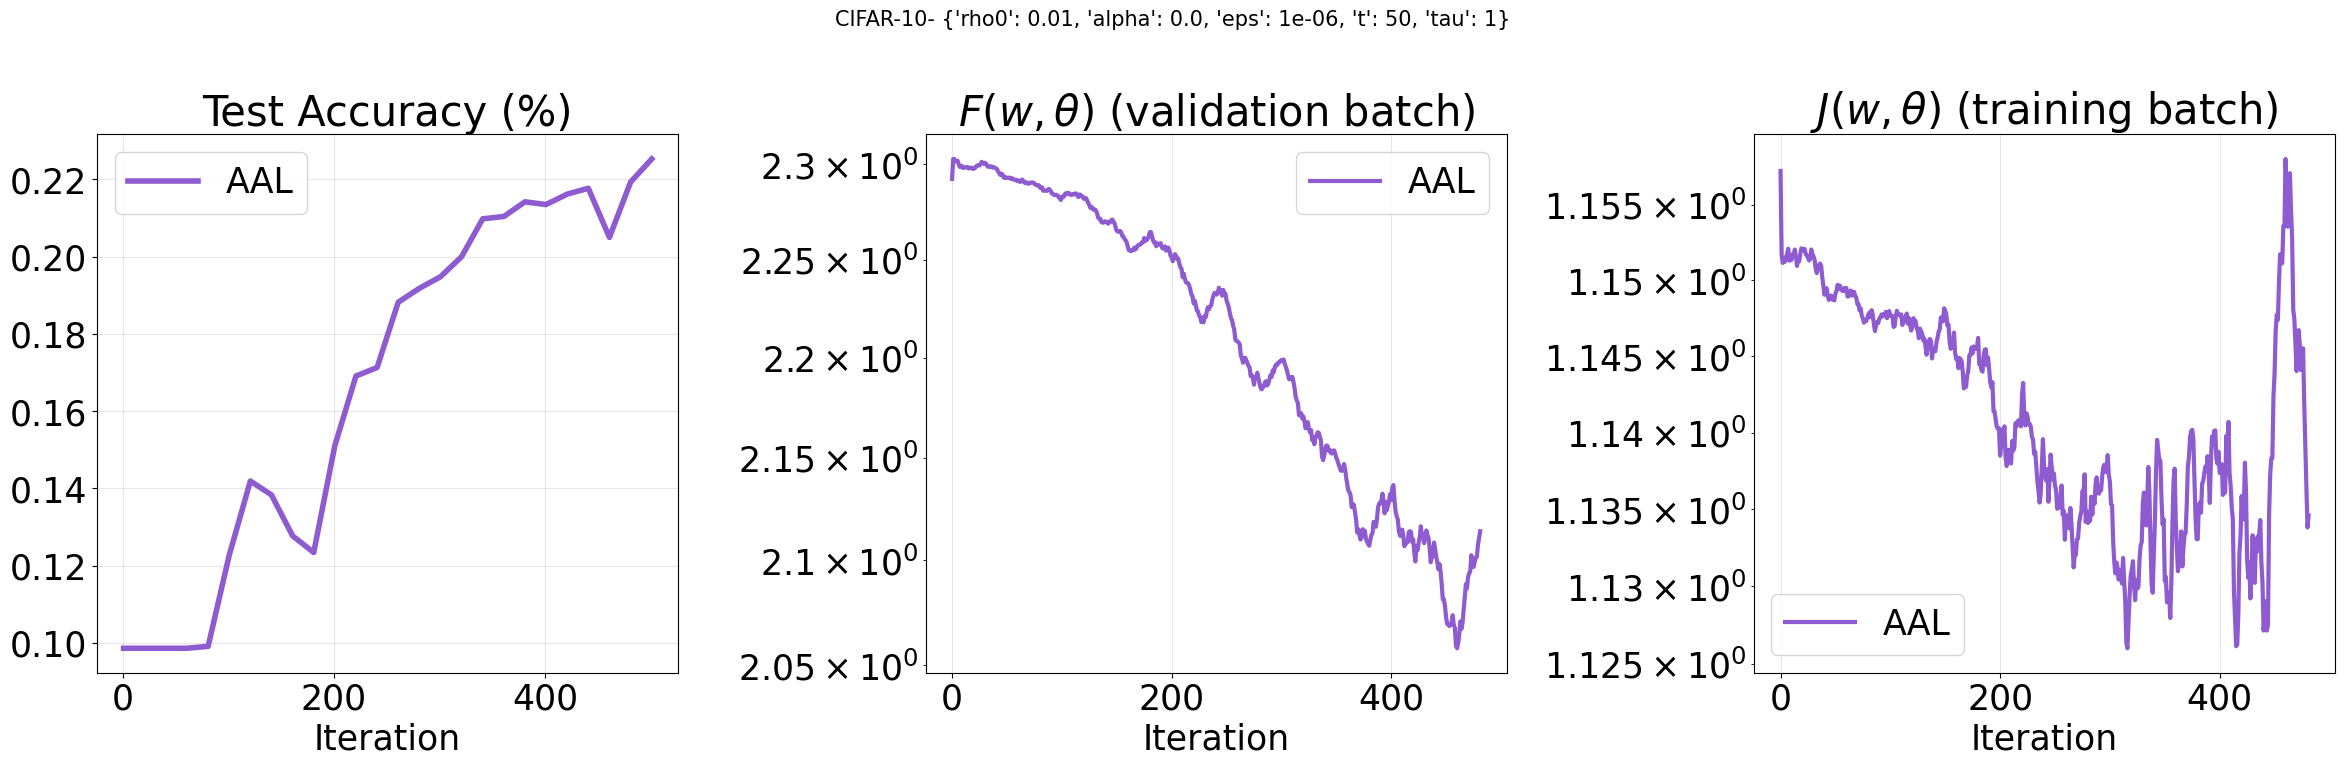

In [161]:
# "PABLO": dict(lr_w=0.004, lr_theta=0.8, rmsprop_alpha=0.99, rho=0.02, lr_lambda=0.0001,tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=None),

# settings from MNIST
# HPARAMS["PABLO"] =dict(lr_w=0.004, lr_theta=0.3, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001, tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=1.0)
    # "PABLO": dict(lr_w=0.004, lr_theta=0.27, rmsprop_alpha=0.99, rho=0.18, lr_lambda=0.0001,
    #               tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=None),

BATCH_SIZE=64
NUM_ITERS = 500
EVAL_EVERY = 20
SEED=0


HPARAMS["AAL"] = dict(rho0=0.01, alpha=0.000, eps=1e-6, t=50, tau=1)

# HPARAMS["PABLO"] =dict(lr_w=0.004, lr_theta=0.08, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001, tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=None,
#                        warmup_ratio=0.02, total_steps=NUM_ITERS)


m = "AAL"

results_cifar = {}
for method in [m]:
    classifier = CIFARClassifier(seed=SEED).to(device)
    weight_model = SampleWeightModel(N_TRAIN).to(device)
    optimiser = build_optimiser(method, classifier, weight_model)

    history = run_hypercleaning(optimiser, classifier, weight_model, datasets_cifar, corrupted_mask_cifar,
                                num_iters=NUM_ITERS, batch_size=BATCH_SIZE, seed=SEED,
                                eval_every=EVAL_EVERY, print_every=100, device=device, name=method)
    results_cifar[method] = {"history": history, "classifier": classifier, "weight_model": weight_model}
    print()


fig, axes = plt.subplots(1, 3, figsize=(24,8))

for method, r in results_cifar.items():
    h = r["history"]
    axes[0].plot([i+1 for i in h["eval_iterations"]], h["test_accuracy"], color=COLOURS[method], label=method, linewidth=4)
axes[0].set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3); axes[0].legend()

for ax, (key, title) in zip(axes[1:], [("ul_loss", r"$F(w,\theta)$ (validation batch)"), ("ll_loss", r"$J(w,\theta)$ (training batch)")]):
    for method, r in results_cifar.items():
        plot_metric(r["history"][key],linewidth=3, plot_type="mov", mean_window=20, logy=True, marker="-", ax=ax)
        ax.lines[-1].set_color(COLOURS[method]); ax.lines[-1].set_label(method)
    ax.set_title(title); ax.set_xlabel("Iteration"); ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(f"CIFAR-10- {HPARAMS[m]}", fontsize=15)
plt.tight_layout()
plt.show()



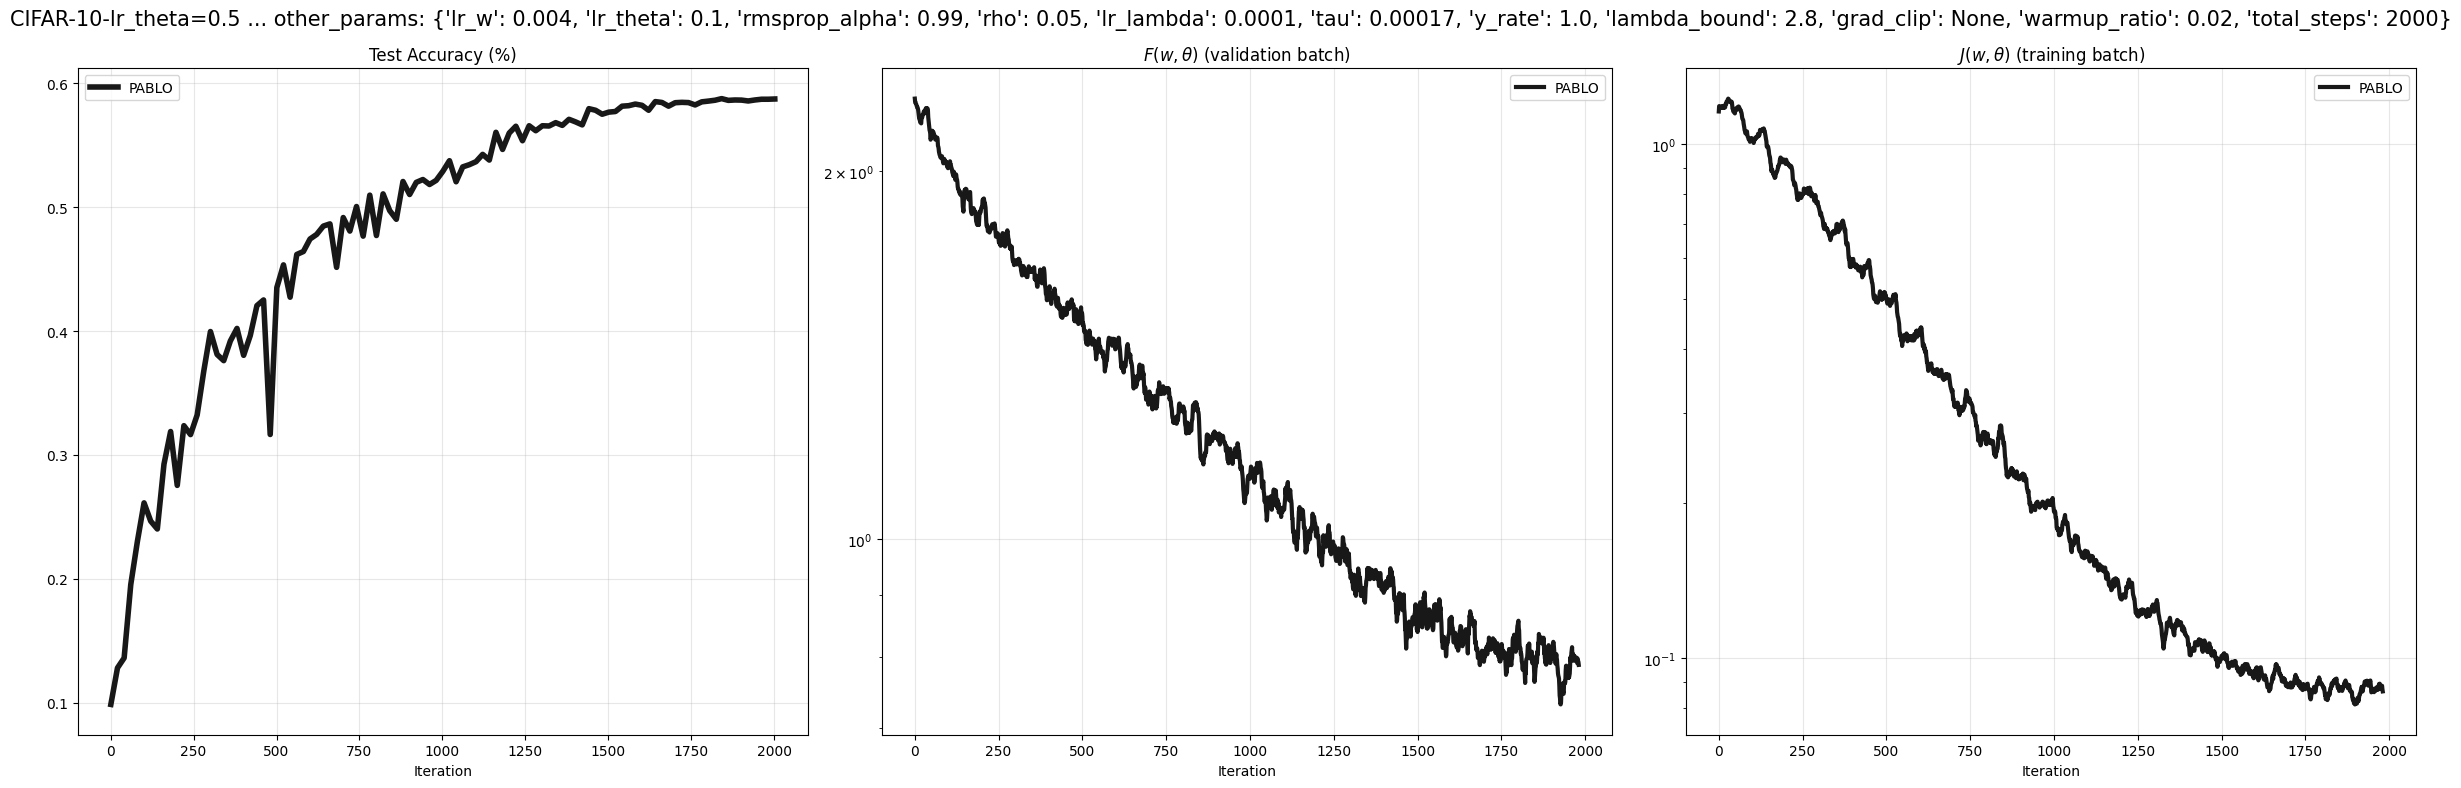

In [68]:

fig, axes = plt.subplots(1, 3, figsize=(24,8))

for method, r in results_cifar.items():
    h = r["history"]
    axes[0].plot([i+1 for i in h["eval_iterations"]], h["test_accuracy"], color=COLOURS[method], label=method, linewidth=4)
axes[0].set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3); axes[0].legend()

for ax, (key, title) in zip(axes[1:], [("ul_loss", r"$F(w,\theta)$ (validation batch)"), ("ll_loss", r"$J(w,\theta)$ (training batch)")]):
    for method, r in results_cifar.items():
        plot_metric(r["history"][key],linewidth=3, plot_type="mov", mean_window=20, logy=True, marker="-", ax=ax)
        ax.lines[-1].set_color(COLOURS[method]); ax.lines[-1].set_label(method)
    ax.set_title(title); ax.set_xlabel("Iteration"); ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(f"CIFAR-10-{param}={param_val} ... other_params: {HPARAMS[m]}", fontsize=15)
plt.tight_layout()
plt.show()

PABLO        100 | LL=1.0054 | UL=1.9075 | test acc=29.51% | clean w=0.422 | corrupt w=0.408 | cleaning F1=58.61% | 24s
PABLO        200 | LL=0.8222 | UL=1.6981 | test acc=33.39% | clean w=0.367 | corrupt w=0.335 | cleaning F1=62.23% | 45s
PABLO        300 | LL=0.7909 | UL=1.4539 | test acc=43.38% | clean w=0.316 | corrupt w=0.267 | cleaning F1=64.23% | 69s
PABLO        400 | LL=0.5451 | UL=1.6616 | test acc=39.77% | clean w=0.278 | corrupt w=0.212 | cleaning F1=66.39% | 97s
PABLO        500 | LL=0.5044 | UL=1.5998 | test acc=45.31% | clean w=0.242 | corrupt w=0.167 | cleaning F1=66.81% | 127s
PABLO        600 | LL=0.3552 | UL=1.2598 | test acc=48.74% | clean w=0.212 | corrupt w=0.130 | cleaning F1=67.55% | 159s
PABLO        700 | LL=0.3459 | UL=1.3069 | test acc=51.34% | clean w=0.185 | corrupt w=0.101 | cleaning F1=67.75% | 188s
PABLO        800 | LL=0.1845 | UL=0.9687 | test acc=51.36% | clean w=0.163 | corrupt w=0.078 | cleaning F1=67.65% | 216s
PABLO        900 | LL=0.1570 | UL=1.

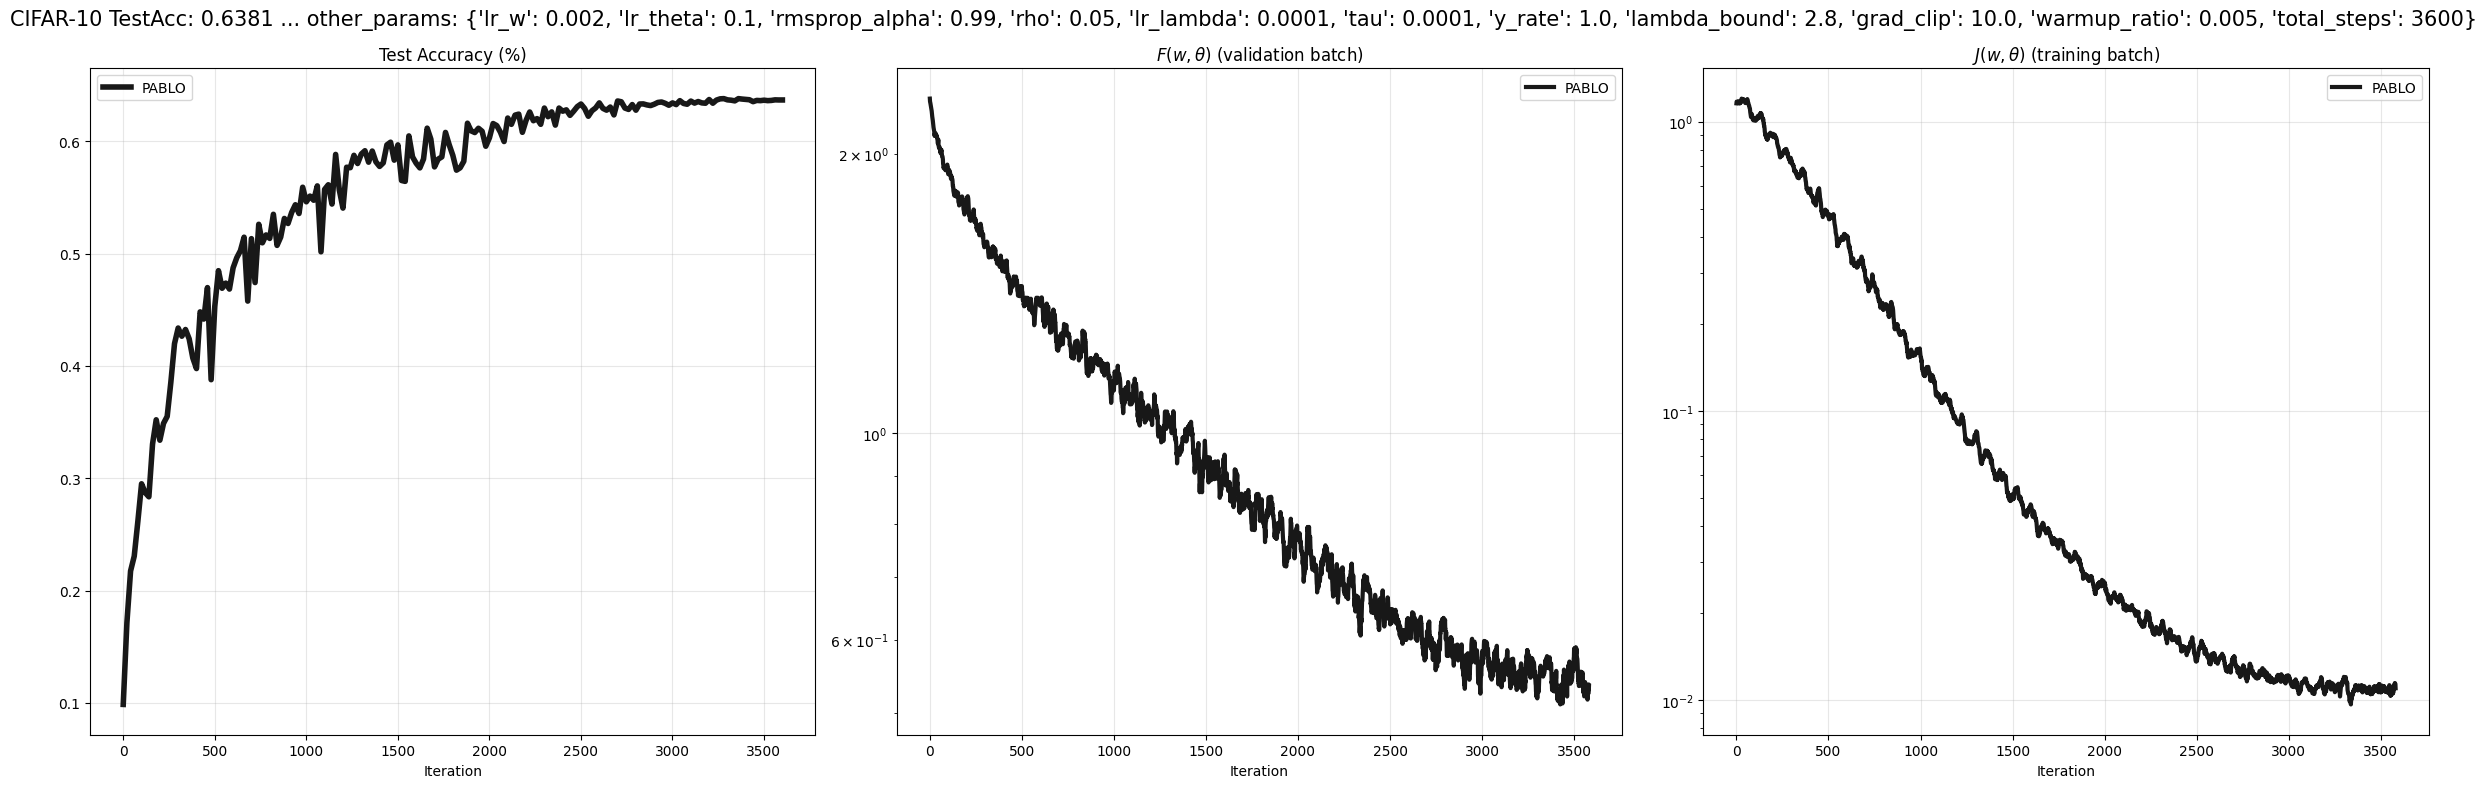

Best score: 0.0986 lr_theta: 0.5
PABLO        100 | LL=0.9520 | UL=1.9386 | test acc=27.63% | clean w=0.418 | corrupt w=0.402 | cleaning F1=58.82% | 30s
PABLO        200 | LL=0.8759 | UL=1.7382 | test acc=28.89% | clean w=0.364 | corrupt w=0.331 | cleaning F1=61.83% | 58s
PABLO        300 | LL=0.7609 | UL=1.4771 | test acc=42.37% | clean w=0.312 | corrupt w=0.266 | cleaning F1=64.28% | 90s
PABLO        400 | LL=0.5071 | UL=1.6685 | test acc=39.10% | clean w=0.274 | corrupt w=0.214 | cleaning F1=65.73% | 125s
PABLO        500 | LL=0.4941 | UL=1.6338 | test acc=46.84% | clean w=0.239 | corrupt w=0.170 | cleaning F1=66.73% | 155s
PABLO        600 | LL=0.3118 | UL=1.2924 | test acc=48.85% | clean w=0.207 | corrupt w=0.135 | cleaning F1=67.07% | 187s
PABLO        700 | LL=0.3118 | UL=1.3200 | test acc=51.28% | clean w=0.184 | corrupt w=0.105 | cleaning F1=67.54% | 214s
PABLO        800 | LL=0.1821 | UL=1.0208 | test acc=49.69% | clean w=0.162 | corrupt w=0.082 | cleaning F1=67.69% | 244s
PA

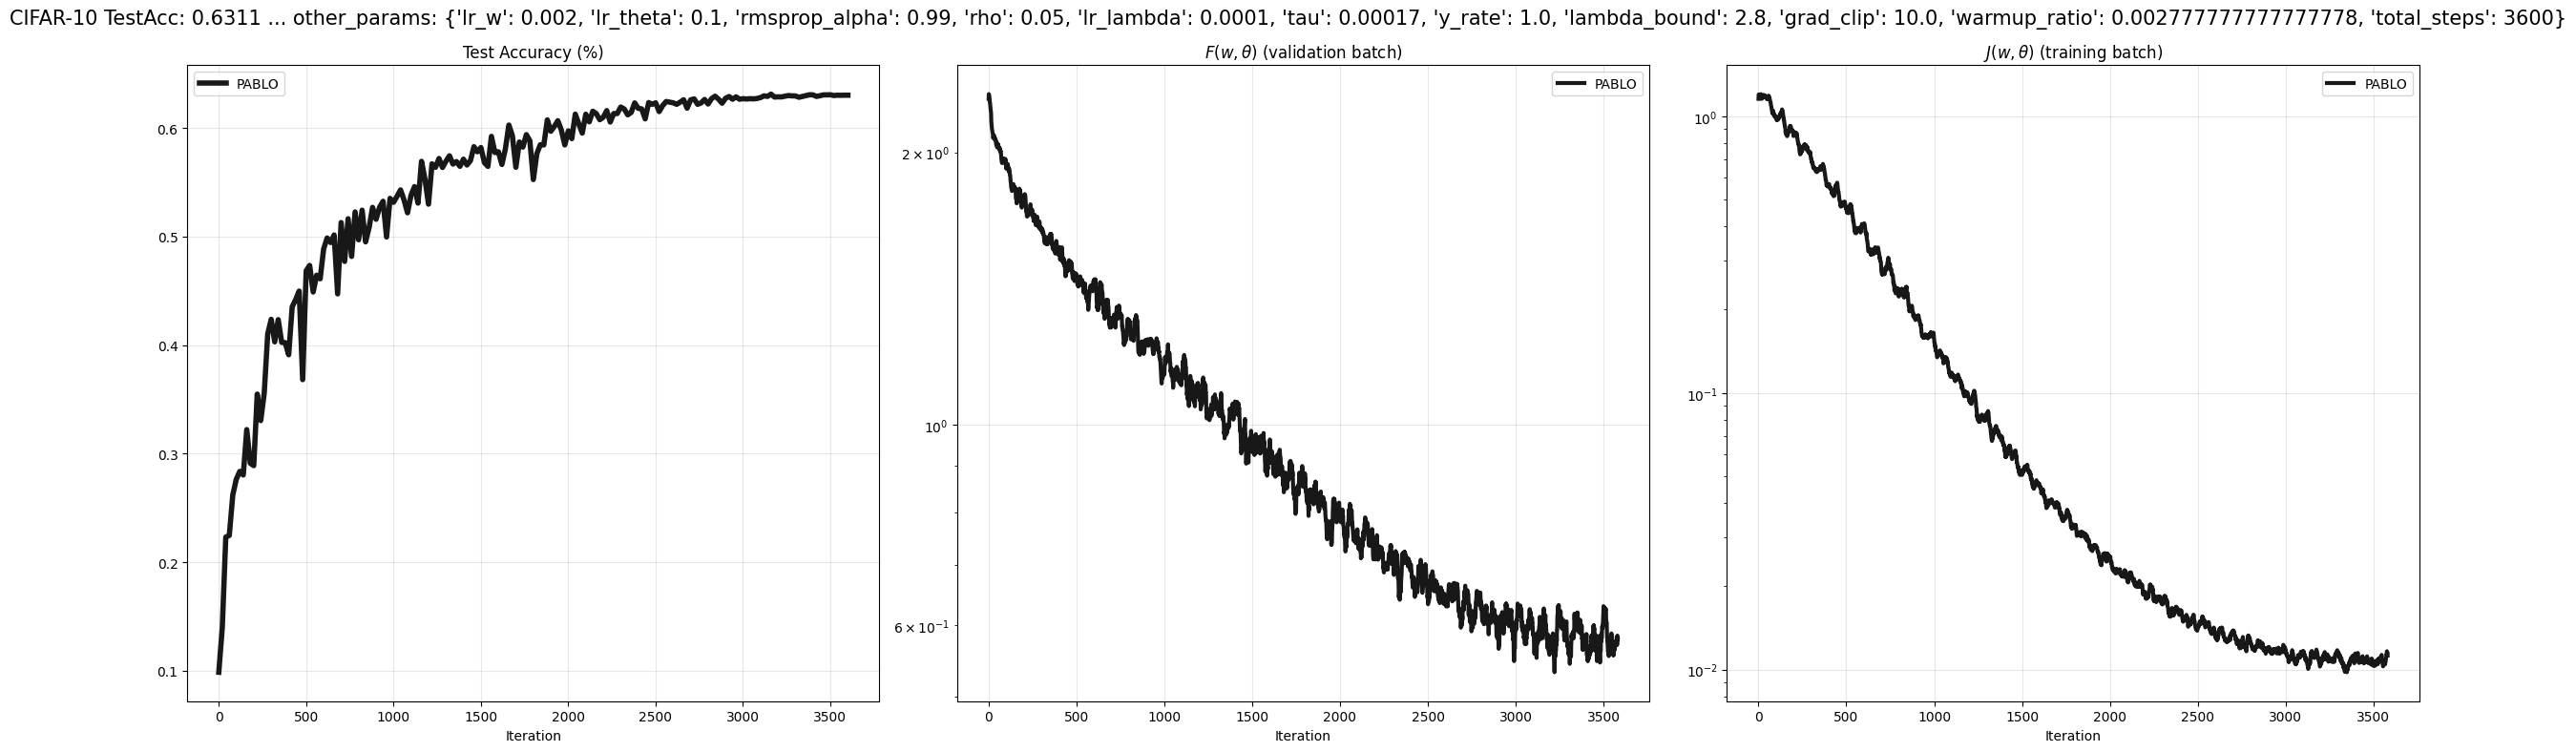

Best score: 0.0986 lr_theta: 0.5
PABLO        100 | LL=1.0715 | UL=1.9496 | test acc=31.22% | clean w=0.427 | corrupt w=0.400 | cleaning F1=59.65% | 28s
PABLO        200 | LL=0.8751 | UL=1.6886 | test acc=32.20% | clean w=0.369 | corrupt w=0.324 | cleaning F1=62.47% | 56s
PABLO        300 | LL=0.8586 | UL=1.4653 | test acc=43.61% | clean w=0.317 | corrupt w=0.256 | cleaning F1=64.40% | 87s
PABLO        400 | LL=0.5934 | UL=1.6245 | test acc=40.79% | clean w=0.275 | corrupt w=0.203 | cleaning F1=66.25% | 123s
PABLO        500 | LL=0.3760 | UL=1.5530 | test acc=42.80% | clean w=0.238 | corrupt w=0.159 | cleaning F1=67.15% | 159s
PABLO        600 | LL=0.3429 | UL=1.2877 | test acc=50.29% | clean w=0.203 | corrupt w=0.124 | cleaning F1=67.22% | 194s
PABLO        700 | LL=0.2642 | UL=1.3070 | test acc=50.96% | clean w=0.174 | corrupt w=0.095 | cleaning F1=67.55% | 229s
PABLO        800 | LL=0.1842 | UL=0.8976 | test acc=52.44% | clean w=0.149 | corrupt w=0.074 | cleaning F1=67.44% | 264s
PA

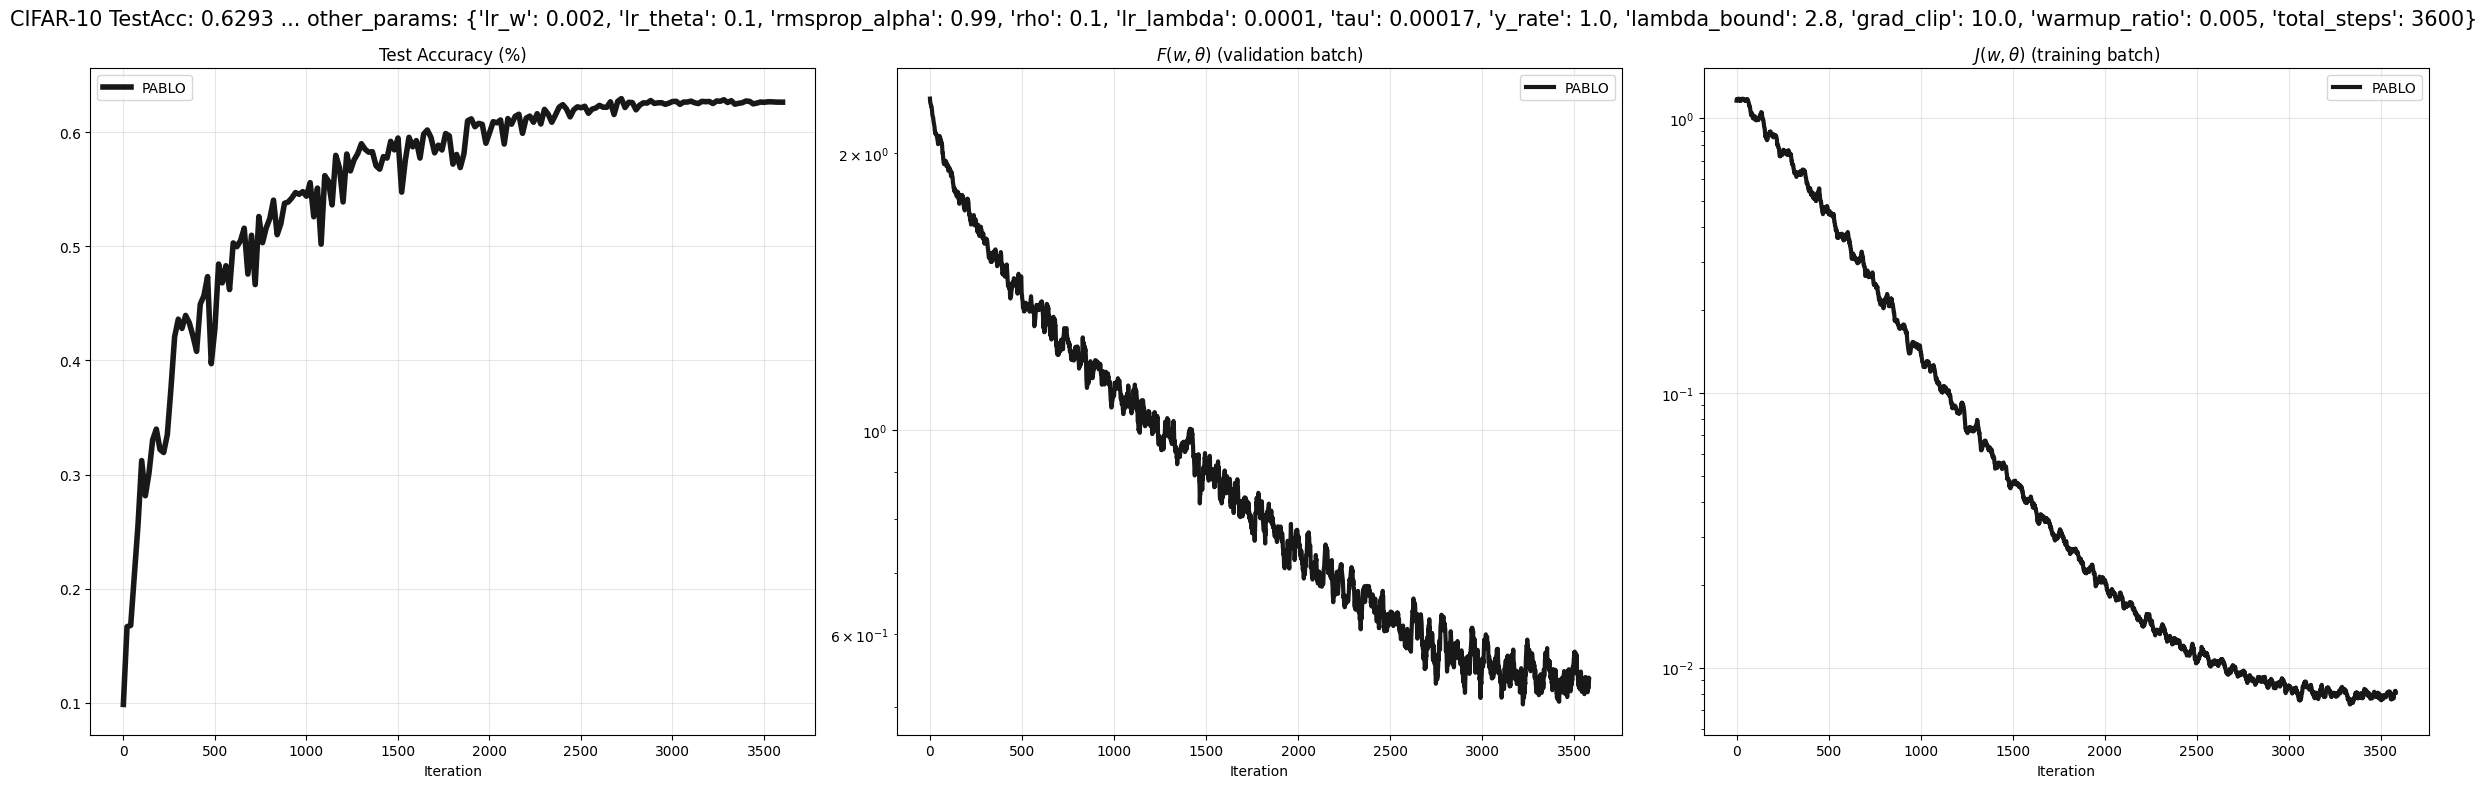

Best score: 0.0986 lr_theta: 0.5
PABLO        100 | LL=1.0135 | UL=1.8697 | test acc=29.34% | clean w=0.421 | corrupt w=0.407 | cleaning F1=58.57% | 28s
PABLO        200 | LL=0.9191 | UL=1.8154 | test acc=32.43% | clean w=0.372 | corrupt w=0.326 | cleaning F1=62.47% | 54s
PABLO        300 | LL=0.8614 | UL=1.4936 | test acc=41.67% | clean w=0.336 | corrupt w=0.257 | cleaning F1=65.22% | 81s
PABLO        400 | LL=0.5073 | UL=1.6894 | test acc=40.01% | clean w=0.311 | corrupt w=0.203 | cleaning F1=66.96% | 110s
PABLO        500 | LL=0.4327 | UL=1.6880 | test acc=41.94% | clean w=0.286 | corrupt w=0.163 | cleaning F1=67.59% | 137s
PABLO        600 | LL=0.3001 | UL=1.2975 | test acc=48.07% | clean w=0.265 | corrupt w=0.128 | cleaning F1=68.43% | 167s
PABLO        700 | LL=0.2945 | UL=1.3391 | test acc=50.02% | clean w=0.248 | corrupt w=0.100 | cleaning F1=69.06% | 195s
PABLO        800 | LL=0.2231 | UL=1.0091 | test acc=50.22% | clean w=0.233 | corrupt w=0.080 | cleaning F1=68.88% | 221s
PA

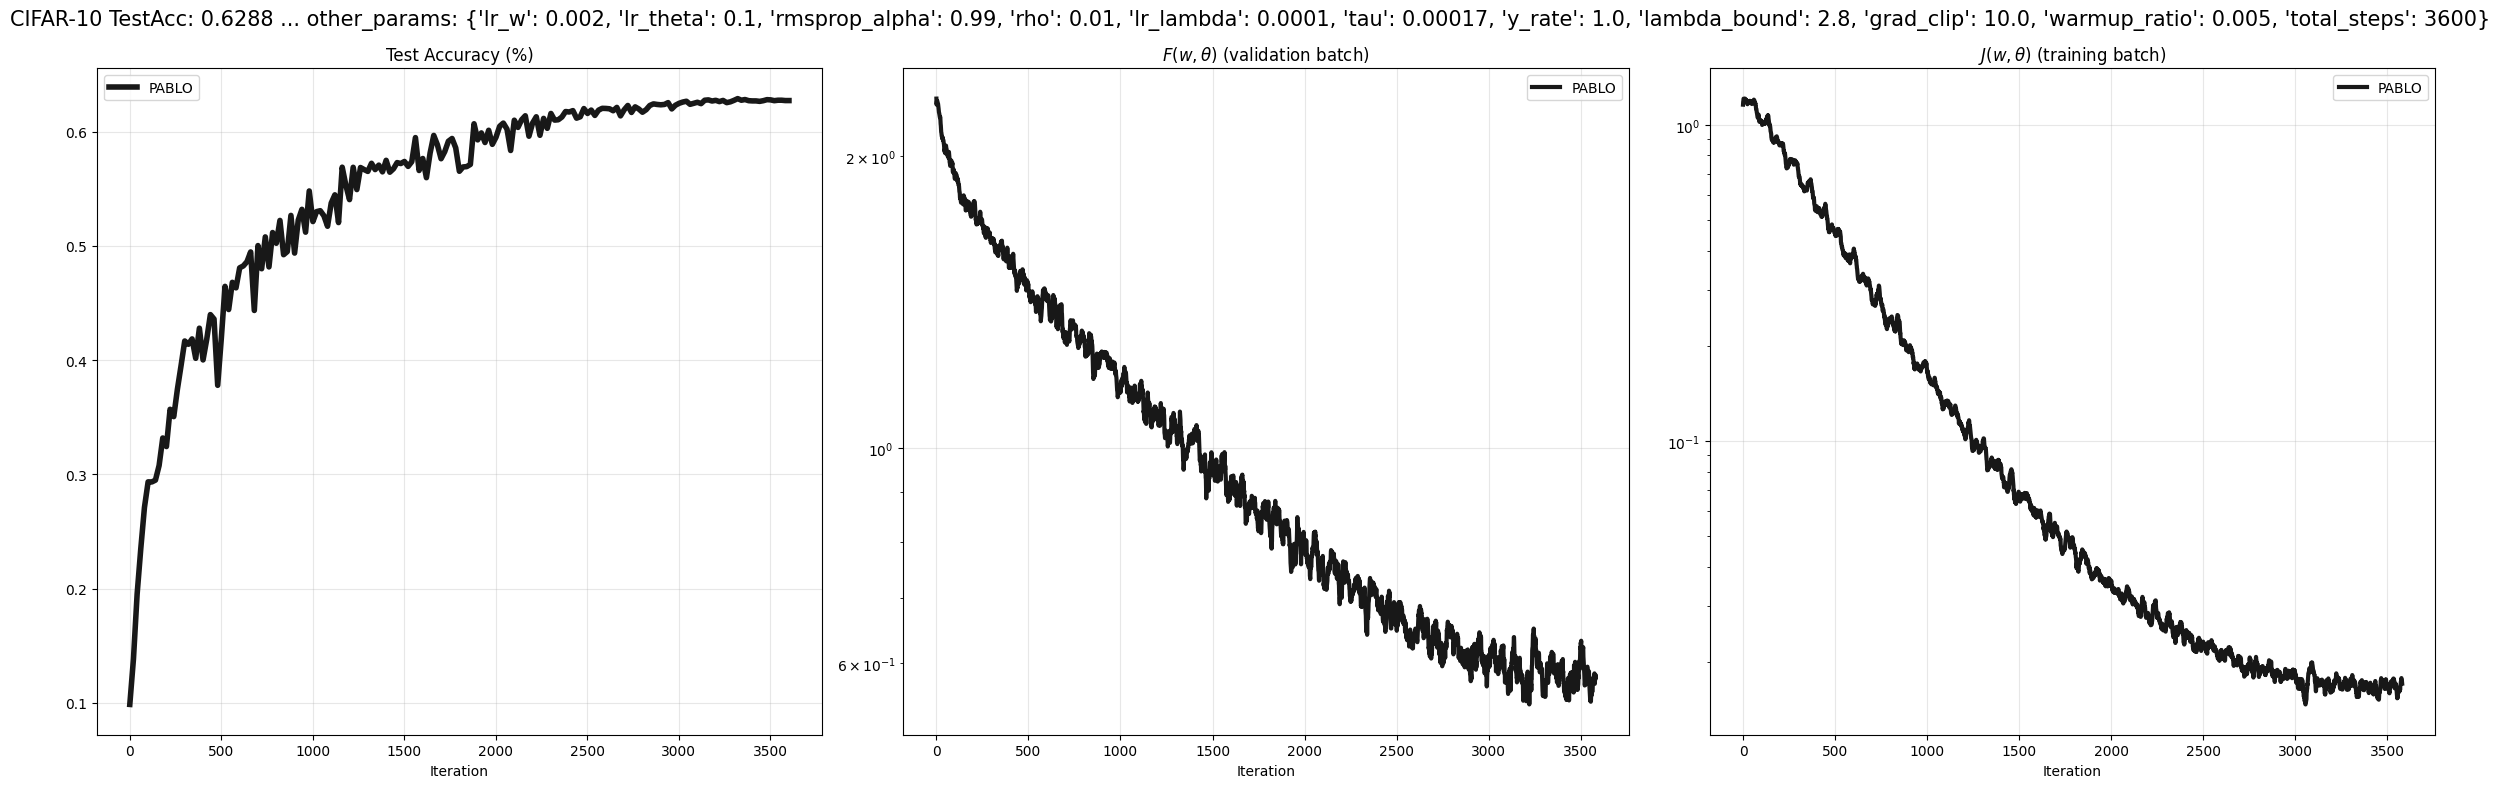

Best score: 0.0986 lr_theta: 0.5
PABLO        100 | LL=1.0053 | UL=1.9560 | test acc=29.44% | clean w=0.422 | corrupt w=0.401 | cleaning F1=59.31% | 28s
PABLO        200 | LL=0.9374 | UL=1.7806 | test acc=32.92% | clean w=0.364 | corrupt w=0.329 | cleaning F1=62.09% | 55s
PABLO        300 | LL=0.8543 | UL=1.4773 | test acc=42.30% | clean w=0.316 | corrupt w=0.268 | cleaning F1=64.08% | 80s
PABLO        400 | LL=0.5714 | UL=1.5895 | test acc=41.67% | clean w=0.277 | corrupt w=0.215 | cleaning F1=65.87% | 106s
PABLO        500 | LL=0.4974 | UL=1.7330 | test acc=46.89% | clean w=0.240 | corrupt w=0.172 | cleaning F1=66.57% | 132s
PABLO        600 | LL=0.2910 | UL=1.2685 | test acc=49.78% | clean w=0.206 | corrupt w=0.136 | cleaning F1=66.79% | 158s
PABLO        700 | LL=0.3586 | UL=1.2670 | test acc=51.66% | clean w=0.180 | corrupt w=0.107 | cleaning F1=67.27% | 184s
PABLO        800 | LL=0.1724 | UL=0.9531 | test acc=50.97% | clean w=0.157 | corrupt w=0.084 | cleaning F1=67.41% | 210s
PA

KeyboardInterrupt: 

In [80]:
# "PABLO": dict(lr_w=0.004, lr_theta=0.8, rmsprop_alpha=0.99, rho=0.02, lr_lambda=0.0001,tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=None),

# settings from MNIST
# HPARAMS["PABLO"] =dict(lr_w=0.004, lr_theta=0.27, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001, tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=1.0)

BATCH_SIZE=64
NUM_ITERS = 3600
EVAL_EVERY = 20
SEED=0


TEST_SCORE_WINDOW = 100 // EVAL_EVERY



hparams = [ 
            # dict(lr_w=0.002, lr_theta=0.5, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001, tau=0.0001, y_rate=1.0, lambda_bound=2.8, grad_clip=10.0, warmup_ratio=0.02, total_steps=NUM_ITERS),
            dict(lr_w=0.002, lr_theta=0.1, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001, tau=0.0001, y_rate=1.0, lambda_bound=2.8, grad_clip=10.0, warmup_ratio=18/3600, total_steps=NUM_ITERS),
            dict(lr_w=0.002, lr_theta=0.1, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001, tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=10.0, warmup_ratio=10/3600, total_steps=NUM_ITERS),
            dict(lr_w=0.002, lr_theta=0.1, rmsprop_alpha=0.99, rho=0.1, lr_lambda=0.0001, tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=10.0, warmup_ratio=18/3600, total_steps=NUM_ITERS),
            dict(lr_w=0.002, lr_theta=0.1, rmsprop_alpha=0.99, rho=0.01, lr_lambda=0.0001, tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=10.0, warmup_ratio=18/3600, total_steps=NUM_ITERS),
            dict(lr_w=0.002, lr_theta=0.1, rmsprop_alpha=0.99, rho=0.01, lr_lambda=0.00001, tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=10.0, warmup_ratio=18/3600, total_steps=NUM_ITERS),]
            # dict(lr_w=0.006, lr_theta=0.5, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001, tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=10.0, warmup_ratio=0.02, total_steps=NUM_ITERS),
            # dict(lr_w=0.006, lr_theta=0.5, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001, tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=10.0, warmup_ratio=0.04, total_steps=NUM_ITERS),
            # dict(lr_w=0.006, lr_theta=0.1, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001, tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=10.0, warmup_ratio=0.02, total_steps=NUM_ITERS),
            # dict(lr_w=0.006, lr_theta=0.1, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001, tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=10.0, warmup_ratio=0.04, total_steps=NUM_ITERS),
            # dict(lr_w=0.004, lr_theta=0.1, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001, tau=0.00001, y_rate=1.0, lambda_bound=2.8, grad_clip=10.0, warmup_ratio=0.02, total_steps=NUM_ITERS),
            # dict(lr_w=0.004, lr_theta=0.1, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001, tau=0.0001, y_rate=1.0, lambda_bound=2.8, grad_clip=10.0, warmup_ratio=0.04, total_steps=NUM_ITERS),
            # dict(lr_w=0.004, lr_theta=0.1, rmsprop_alpha=0.99, rho=0.05, lr_lambda=0.0001, tau=0.0001, y_rate=0.5, lambda_bound=10.0, grad_clip=10.0, warmup_ratio=0.04, total_steps=NUM_ITERS),
            # dict(lr_w=0.008, lr_theta=0.1, rmsprop_alpha=0.98, rho=0.05, lr_lambda=0.0001, tau=0.0001, y_rate=0.5, lambda_bound=10.0, grad_clip=10.0, warmup_ratio=0.04, total_steps=NUM_ITERS),
            # dict(lr_w=0.002, lr_theta=0.3, rmsprop_alpha=0.97, rho=0.01, lr_lambda=0.0001, tau=0.00001, y_rate=0.5, lambda_bound=10.0, grad_clip=10.0, warmup_ratio=0.04, total_steps=NUM_ITERS),]

              

for hparam in hparams:


        
    HPARAMS[m] = hparam

    results_cifar = {}
    for method in [m]:
        classifier = CIFARClassifier(seed=SEED).to(device)
        weight_model = SampleWeightModel(N_TRAIN).to(device)
        optimiser = build_optimiser(method, classifier, weight_model)

        history = run_hypercleaning(optimiser, classifier, weight_model, datasets_cifar, corrupted_mask_cifar,
                                    num_iters=NUM_ITERS, batch_size=BATCH_SIZE, seed=SEED,
                                    eval_every=EVAL_EVERY, print_every=100, device=device, name=method)
        results_cifar[method] = {"history": history, "classifier": classifier, "weight_model": weight_model}
        print()

        print('TestAcc last 100:', ScoreTest(results_cifar[m]["history"]["test_accuracy"]))
        print(hparam)

        fig, axes = plt.subplots(1, 3, figsize=(24,8))

        for method, r in results_cifar.items():
            h = r["history"]
            axes[0].plot([i+1 for i in h["eval_iterations"]], h["test_accuracy"], color=COLOURS[method], label=method, linewidth=4)
        axes[0].set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3); axes[0].legend()

        for ax, (key, title) in zip(axes[1:], [("ul_loss", r"$F(w,\theta)$ (validation batch)"), ("ll_loss", r"$J(w,\theta)$ (training batch)")]):
            for method, r in results_cifar.items():
                plot_metric(r["history"][key],linewidth=3, plot_type="mov", mean_window=20, logy=True, marker="-", ax=ax)
                ax.lines[-1].set_color(COLOURS[method]); ax.lines[-1].set_label(method)
            ax.set_title(title); ax.set_xlabel("Iteration"); ax.grid(alpha=0.3)
            ax.legend()

        fig.suptitle(f"CIFAR-10 TestAcc: {ScoreTest(results_cifar[m]["history"]["test_accuracy"])} ... other_params: {HPARAMS[m]}", fontsize=15)
        plt.tight_layout()
        plt.show()

        
    print(f'Best score: {best_score} {param}: {param_val}')
    HPARAMS[m][param] = best_param

PABLO        100 | LL=0.8833 | UL=1.8736 | test acc=29.31% | clean w=0.357 | corrupt w=0.326 | cleaning F1=59.00% | 33s
PABLO        200 | LL=0.6228 | UL=1.7716 | test acc=34.00% | clean w=0.308 | corrupt w=0.278 | cleaning F1=60.63% | 66s
PABLO        300 | LL=0.6487 | UL=1.6132 | test acc=37.16% | clean w=0.261 | corrupt w=0.218 | cleaning F1=63.02% | 99s
PABLO        400 | LL=0.5003 | UL=1.6970 | test acc=38.83% | clean w=0.210 | corrupt w=0.170 | cleaning F1=63.96% | 135s



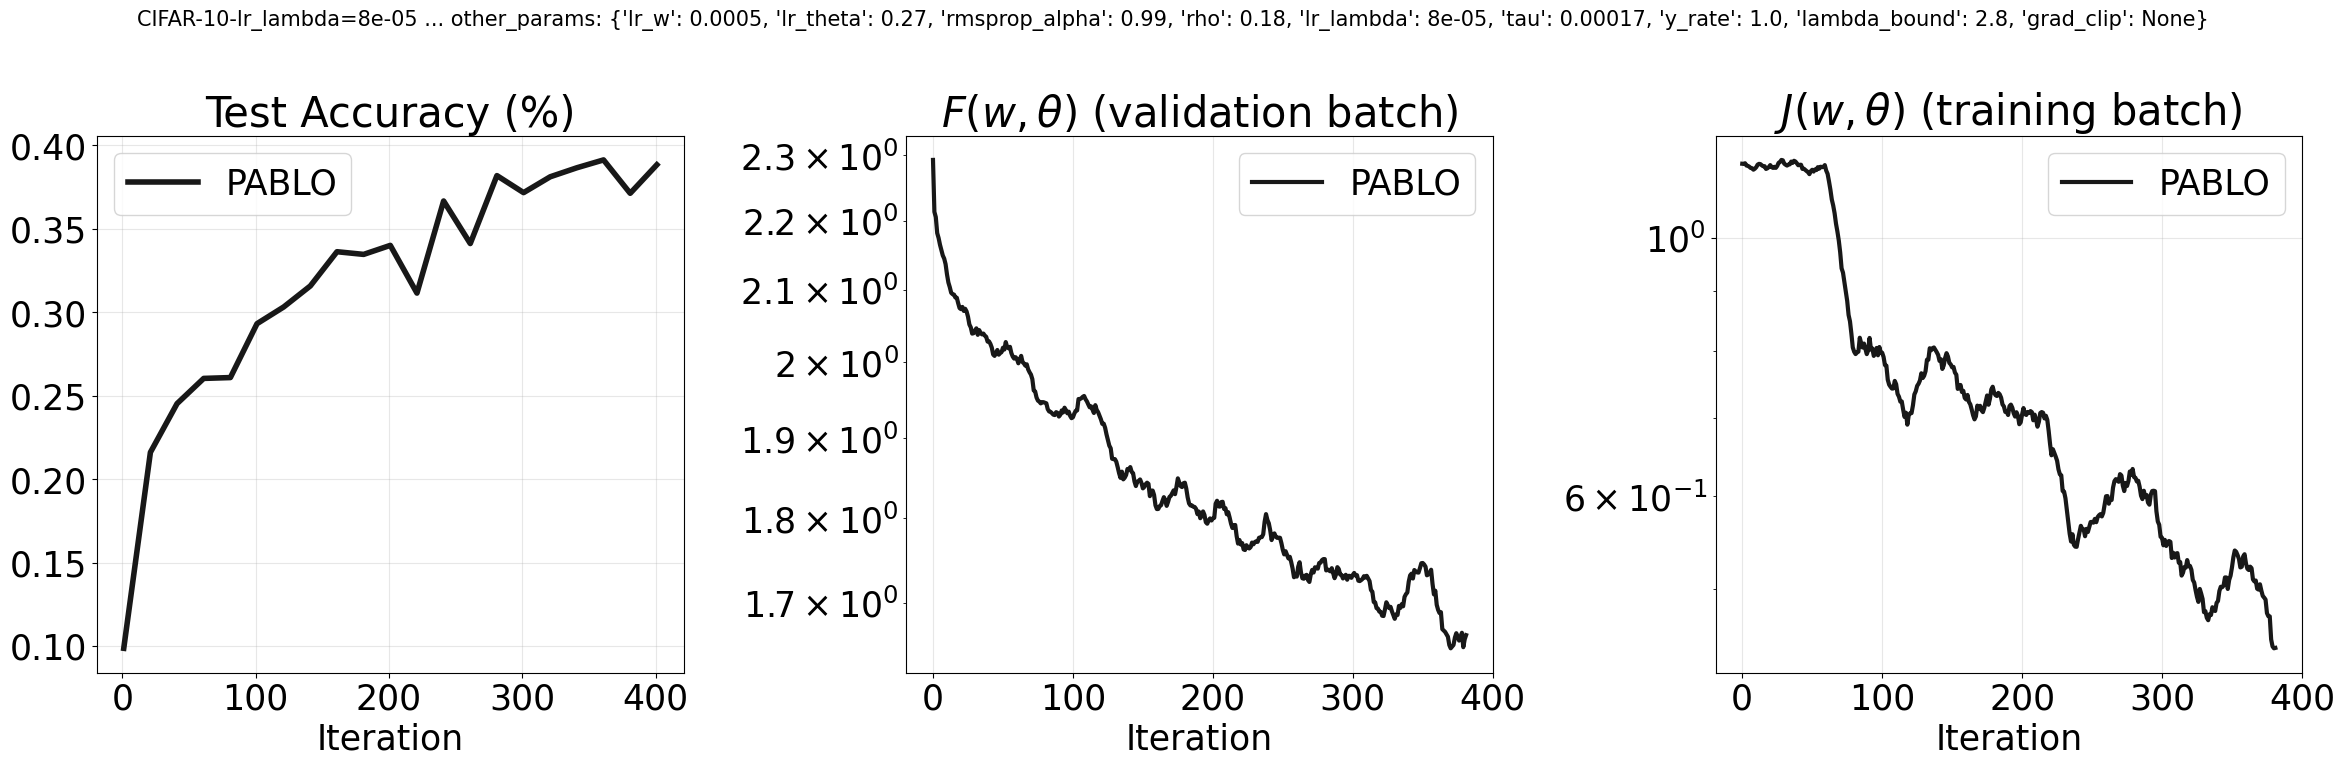

PABLO        100 | LL=0.9138 | UL=1.8706 | test acc=29.57% | clean w=0.355 | corrupt w=0.326 | cleaning F1=58.90% | 38s
PABLO        200 | LL=0.6194 | UL=1.7730 | test acc=33.93% | clean w=0.307 | corrupt w=0.279 | cleaning F1=60.38% | 74s
PABLO        300 | LL=0.6334 | UL=1.6151 | test acc=37.24% | clean w=0.258 | corrupt w=0.218 | cleaning F1=62.74% | 109s
PABLO        400 | LL=0.4925 | UL=1.6981 | test acc=38.96% | clean w=0.209 | corrupt w=0.170 | cleaning F1=64.15% | 145s



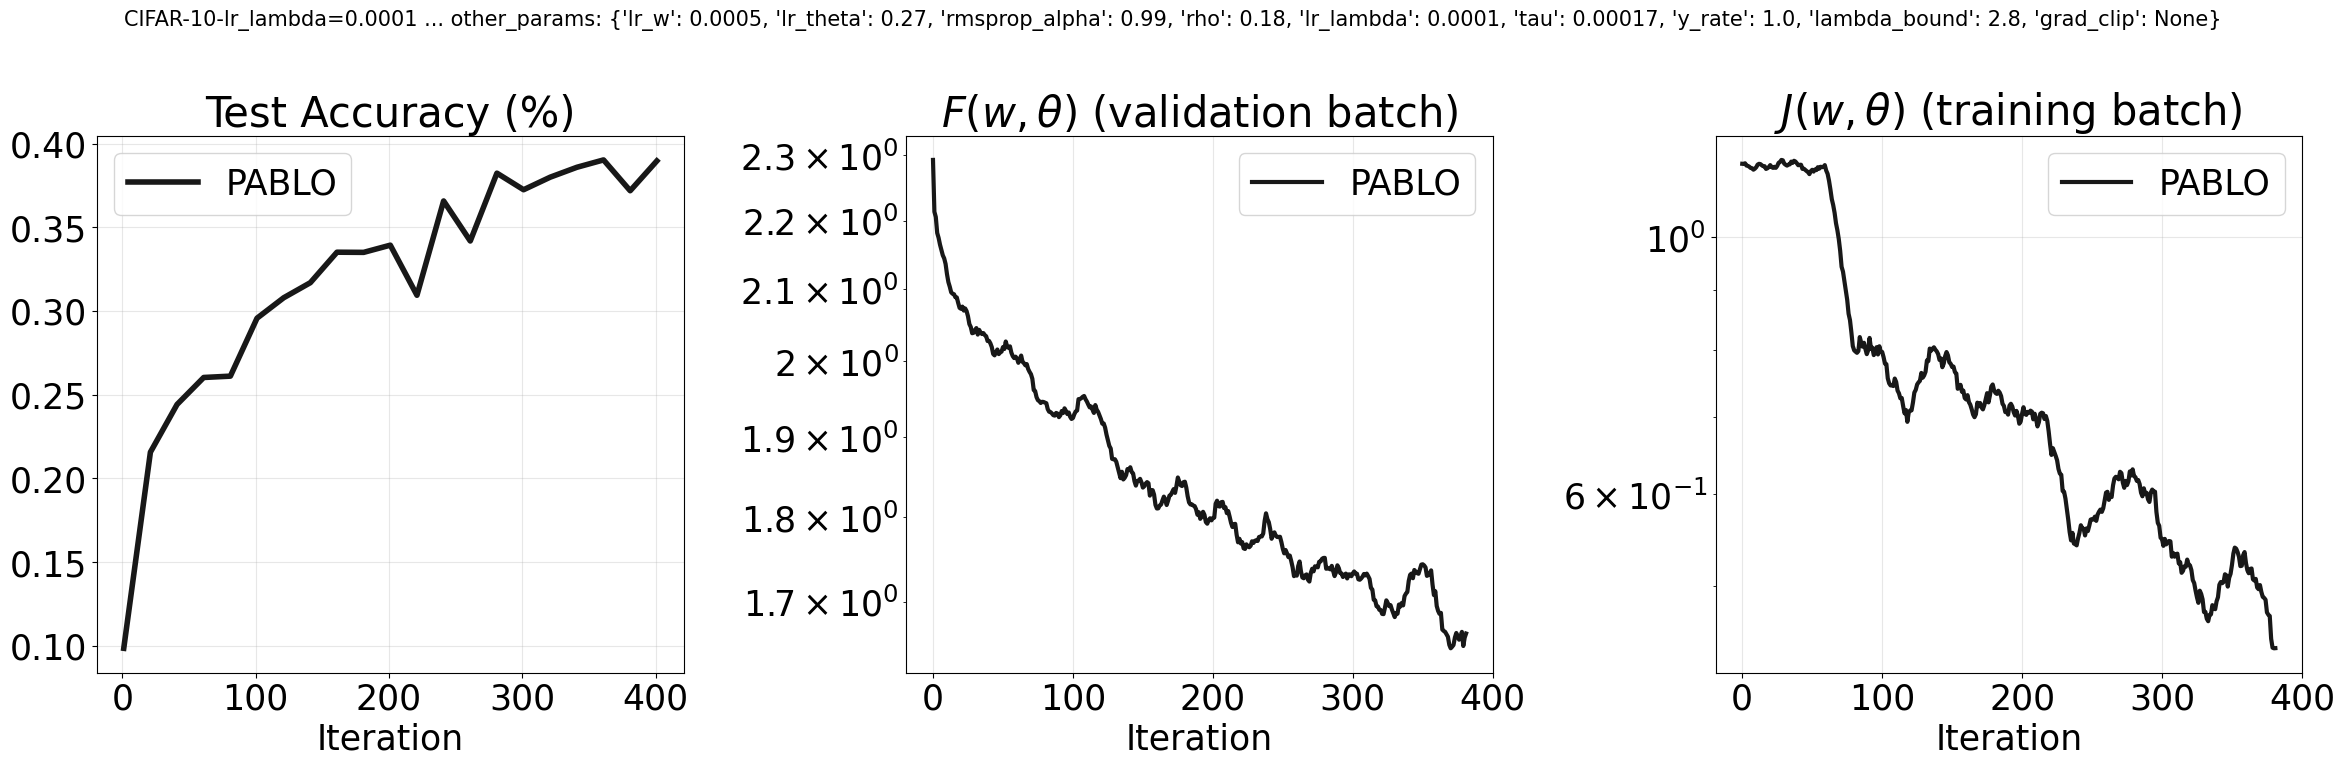

PABLO        100 | LL=0.9160 | UL=1.8687 | test acc=29.95% | clean w=0.356 | corrupt w=0.326 | cleaning F1=59.00% | 39s
PABLO        200 | LL=0.6270 | UL=1.7714 | test acc=34.13% | clean w=0.310 | corrupt w=0.275 | cleaning F1=60.94% | 75s
PABLO        300 | LL=0.6275 | UL=1.6136 | test acc=37.08% | clean w=0.264 | corrupt w=0.215 | cleaning F1=63.15% | 111s
PABLO        400 | LL=0.4529 | UL=1.7024 | test acc=39.11% | clean w=0.216 | corrupt w=0.166 | cleaning F1=64.49% | 147s



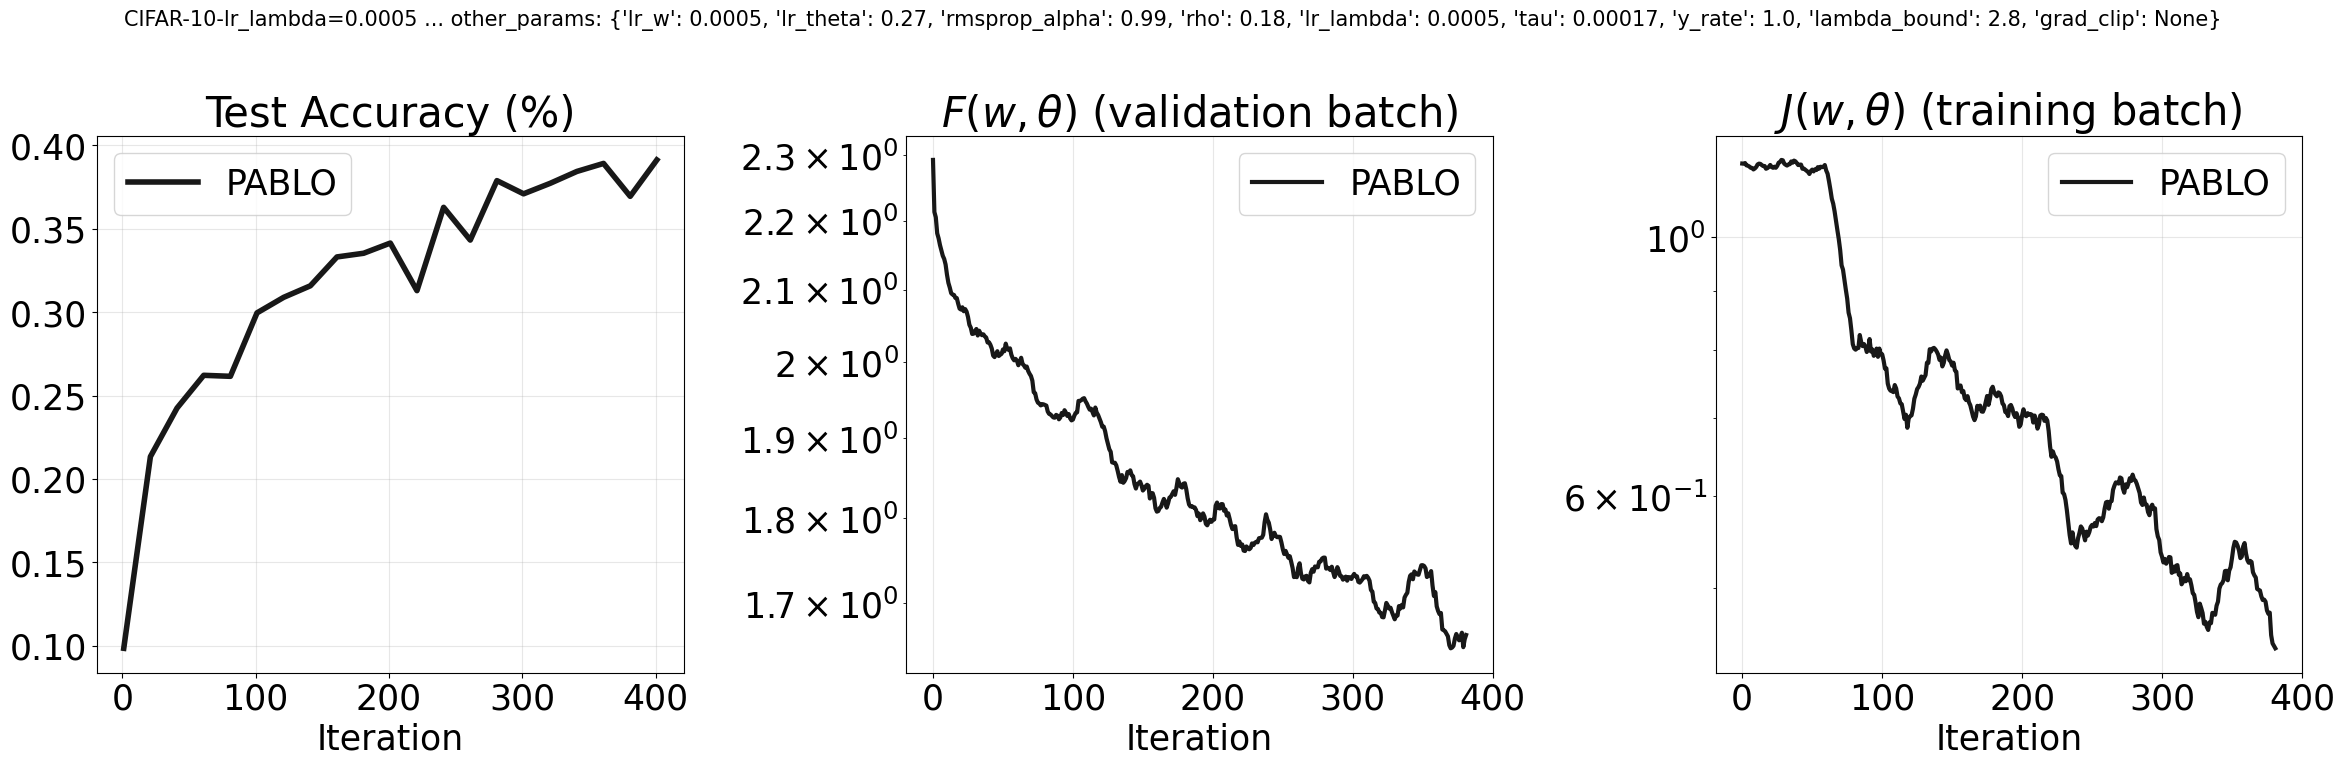

PABLO        100 | LL=0.9155 | UL=1.8687 | test acc=29.98% | clean w=0.357 | corrupt w=0.327 | cleaning F1=58.91% | 38s
PABLO        200 | LL=0.6229 | UL=1.7743 | test acc=33.94% | clean w=0.310 | corrupt w=0.275 | cleaning F1=60.75% | 75s
PABLO        300 | LL=0.6362 | UL=1.6245 | test acc=36.96% | clean w=0.265 | corrupt w=0.215 | cleaning F1=62.90% | 111s
PABLO        400 | LL=0.4027 | UL=1.7047 | test acc=39.12% | clean w=0.218 | corrupt w=0.164 | cleaning F1=64.64% | 148s



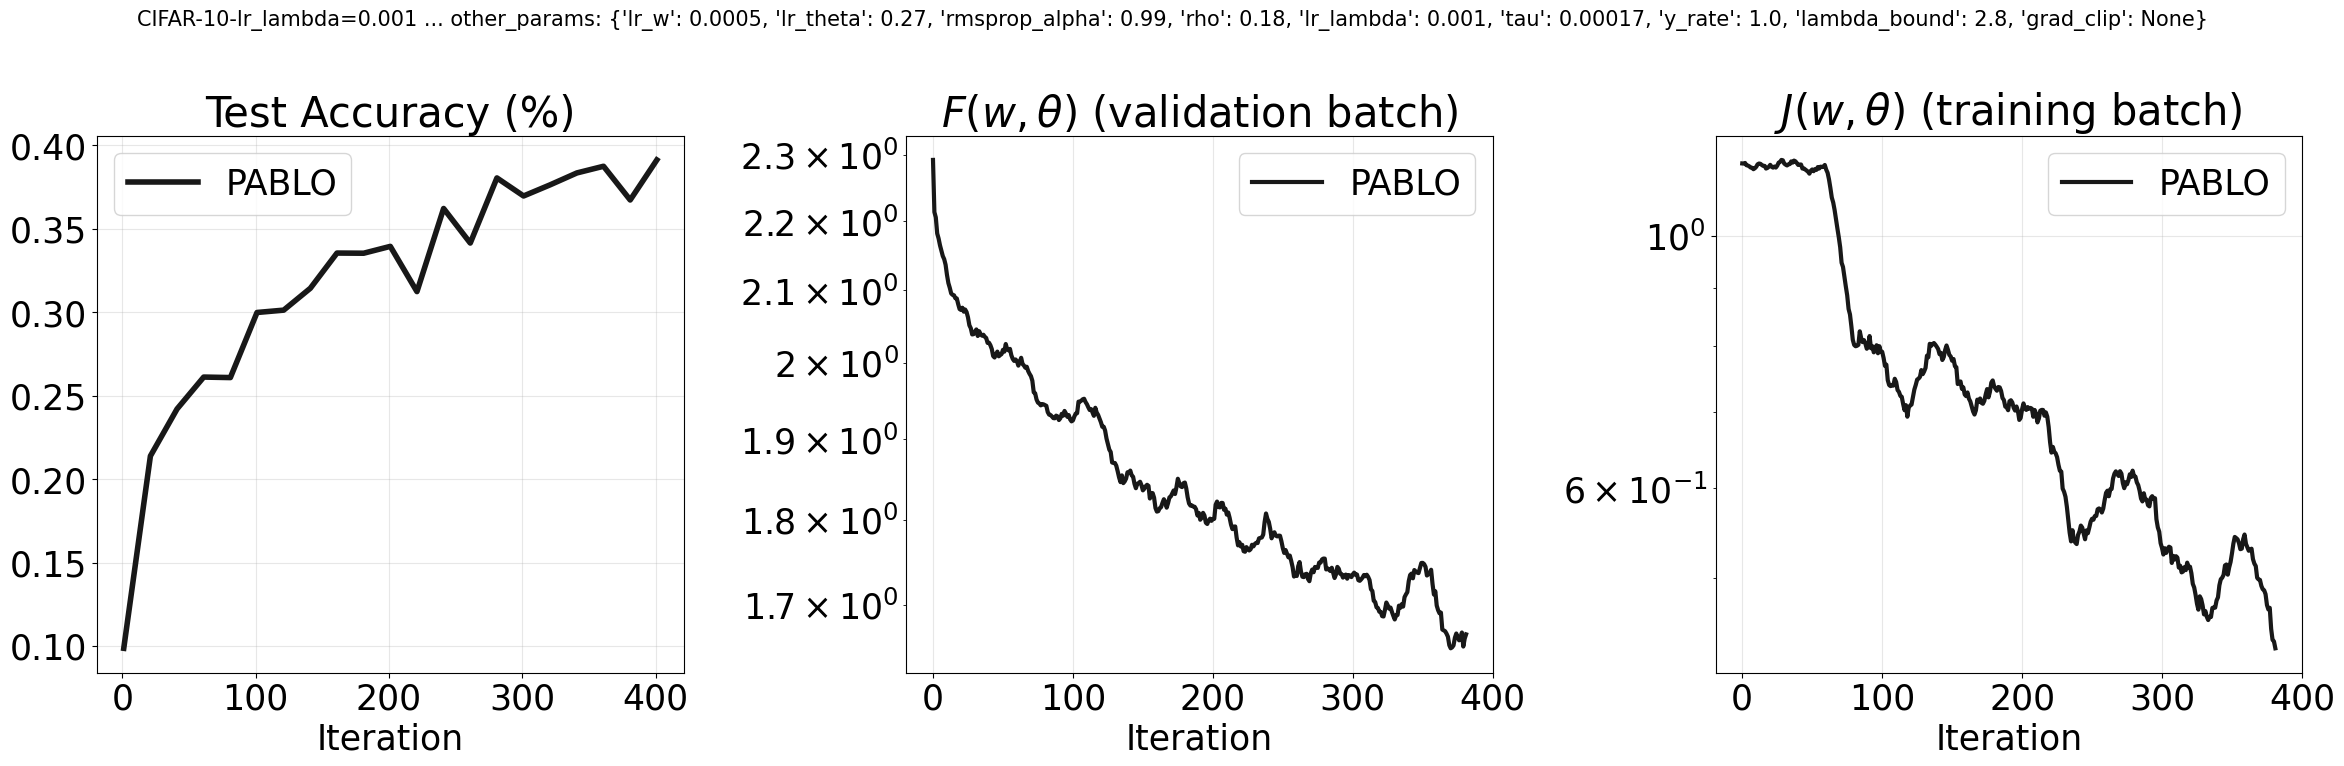

In [ ]:
BATCH_SIZE=64
NUM_ITERS = 400
EVAL_EVERY = 20
SEED=0

# "PABLO": dict(lr_w=0.0005, lr_theta=0.8, rmsprop_alpha=0.99, rho=0.18, lr_lambda=0.0001,tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=None)
HPARAMS = {
    "PABLO": dict(lr_w=0.004, lr_theta=0.8, rmsprop_alpha=0.99, rho=0.02, lr_lambda=0.0001,
        tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=None),}

m = "PABLO"
param = "lr_lambda"
param_vals = [0.00008, 0.00001, 0.0005, 0.001]

for param_val in param_vals:
    HPARAMS = {"PABLO": dict(lr_w=0.0005, lr_theta=0.27, rmsprop_alpha=0.99, rho=0.18, lr_lambda=0.0001,
        tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=None),}
    
    HPARAMS[m][param] = param_val

    results_cifar = {}
    for method in [m]:
        classifier = CIFARClassifier(seed=SEED).to(device)
        weight_model = SampleWeightModel(N_TRAIN).to(device)
        optimiser = build_optimiser(method, classifier, weight_model)

        history = run_hypercleaning(optimiser, classifier, weight_model, datasets_cifar, corrupted_mask_cifar,
                                    num_iters=NUM_ITERS, batch_size=BATCH_SIZE, seed=SEED,
                                    eval_every=EVAL_EVERY, print_every=100, device=device, name=method)
        results_cifar[method] = {"history": history, "classifier": classifier, "weight_model": weight_model}
        print()

    fig, axes = plt.subplots(1, 3, figsize=(24,8))

    for method, r in results_cifar.items():
        h = r["history"]
        axes[0].plot([i+1 for i in h["eval_iterations"]], h["test_accuracy"], color=COLOURS[method], label=method, linewidth=4)
    axes[0].set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3); axes[0].legend()

    for ax, (key, title) in zip(axes[1:], [("ul_loss", r"$F(w,\theta)$ (validation batch)"), ("ll_loss", r"$J(w,\theta)$ (training batch)")]):
        for method, r in results_cifar.items():
            plot_metric(r["history"][key],linewidth=3, plot_type="mov", mean_window=20, logy=True, marker="-", ax=ax)
            ax.lines[-1].set_color(COLOURS[method]); ax.lines[-1].set_label(method)
        ax.set_title(title); ax.set_xlabel("Iteration"); ax.grid(alpha=0.3)
        ax.legend()

    fig.suptitle(f"CIFAR-10-{param}={param_val} ... other_params: {HPARAMS[m]}", fontsize=15)
    plt.tight_layout()
    plt.show()

PABLO        100 | LL=0.9193 | UL=1.9993 | test acc=23.21% | clean w=0.422 | corrupt w=0.412 | cleaning F1=58.04% | 32s
PABLO        200 | LL=0.7826 | UL=2.0130 | test acc=26.43% | clean w=0.378 | corrupt w=0.354 | cleaning F1=60.53% | 63s
PABLO        300 | LL=0.8047 | UL=1.8743 | test acc=26.07% | clean w=0.335 | corrupt w=0.303 | cleaning F1=62.41% | 93s
PABLO        400 | LL=0.5934 | UL=1.9733 | test acc=28.81% | clean w=0.296 | corrupt w=0.261 | cleaning F1=63.81% | 124s



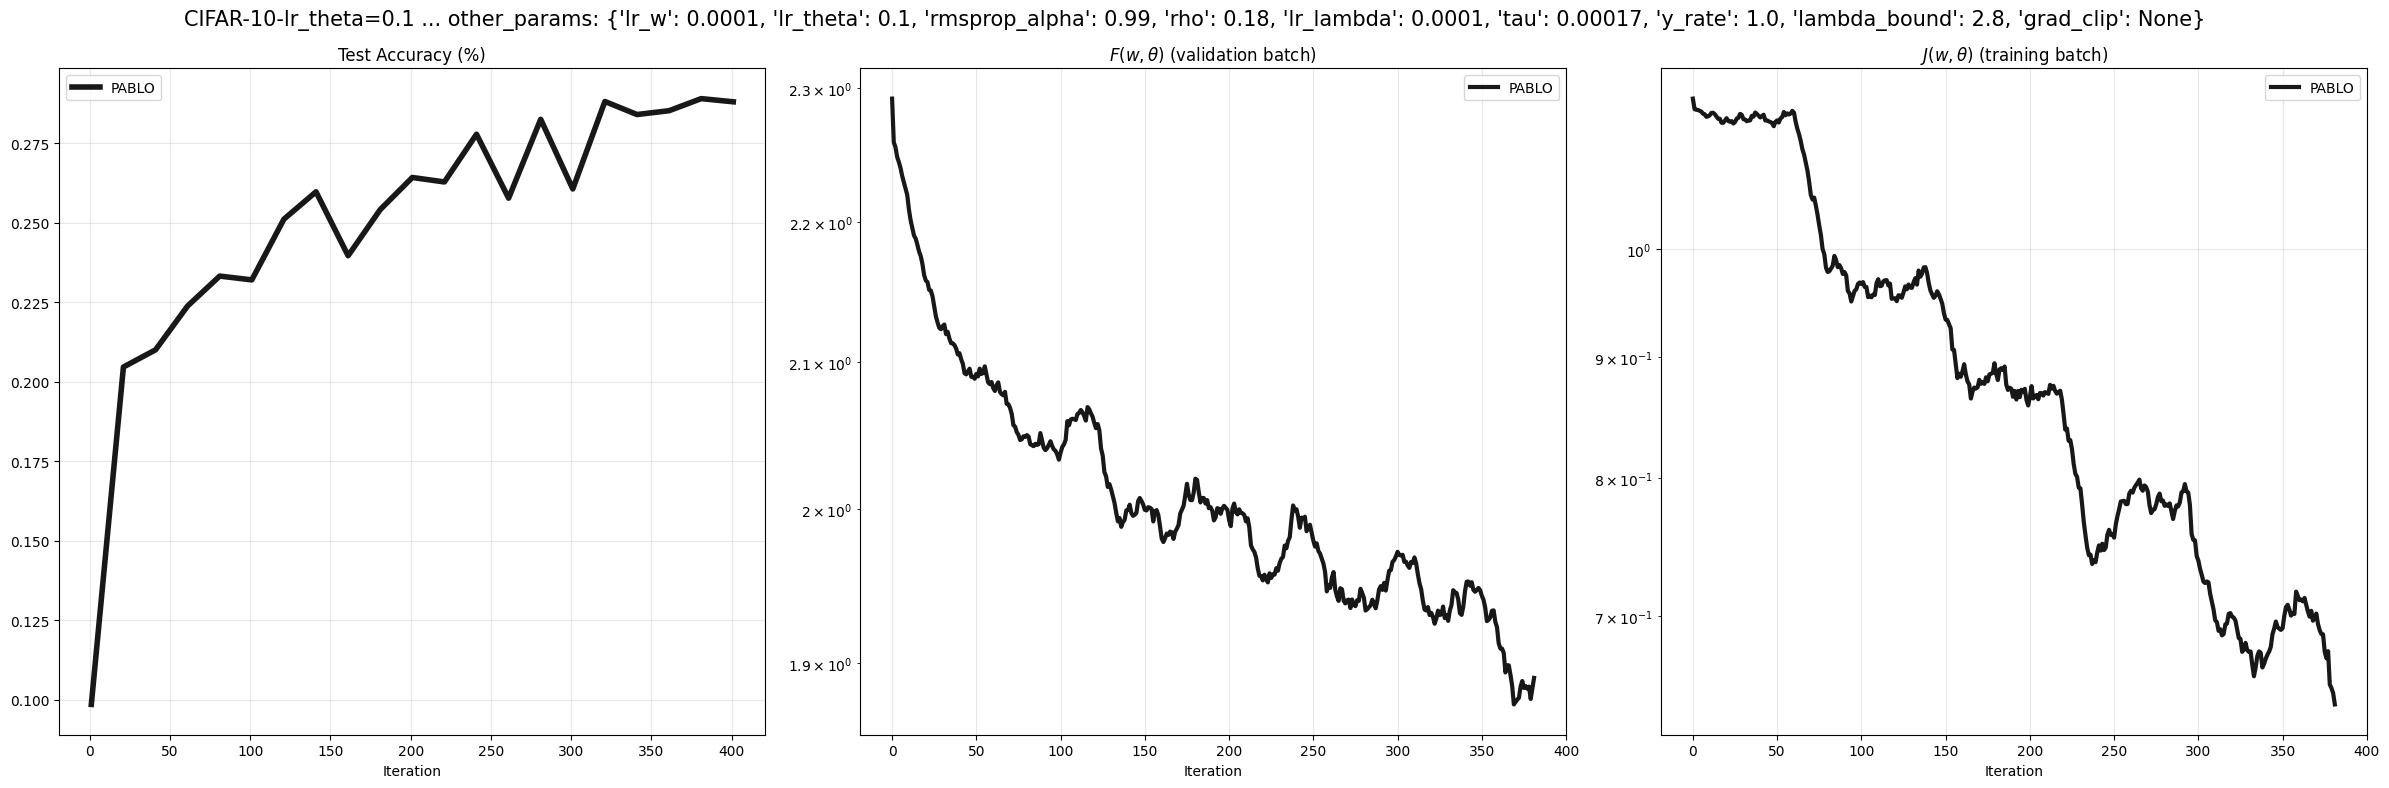

PABLO        100 | LL=0.7893 | UL=2.0008 | test acc=23.21% | clean w=0.383 | corrupt w=0.368 | cleaning F1=57.89% | 32s
PABLO        200 | LL=0.6954 | UL=2.0130 | test acc=26.64% | clean w=0.347 | corrupt w=0.313 | cleaning F1=60.19% | 63s
PABLO        300 | LL=0.6921 | UL=1.8747 | test acc=26.08% | clean w=0.298 | corrupt w=0.257 | cleaning F1=62.67% | 93s
PABLO        400 | LL=0.4890 | UL=1.9720 | test acc=28.91% | clean w=0.252 | corrupt w=0.211 | cleaning F1=63.81% | 124s



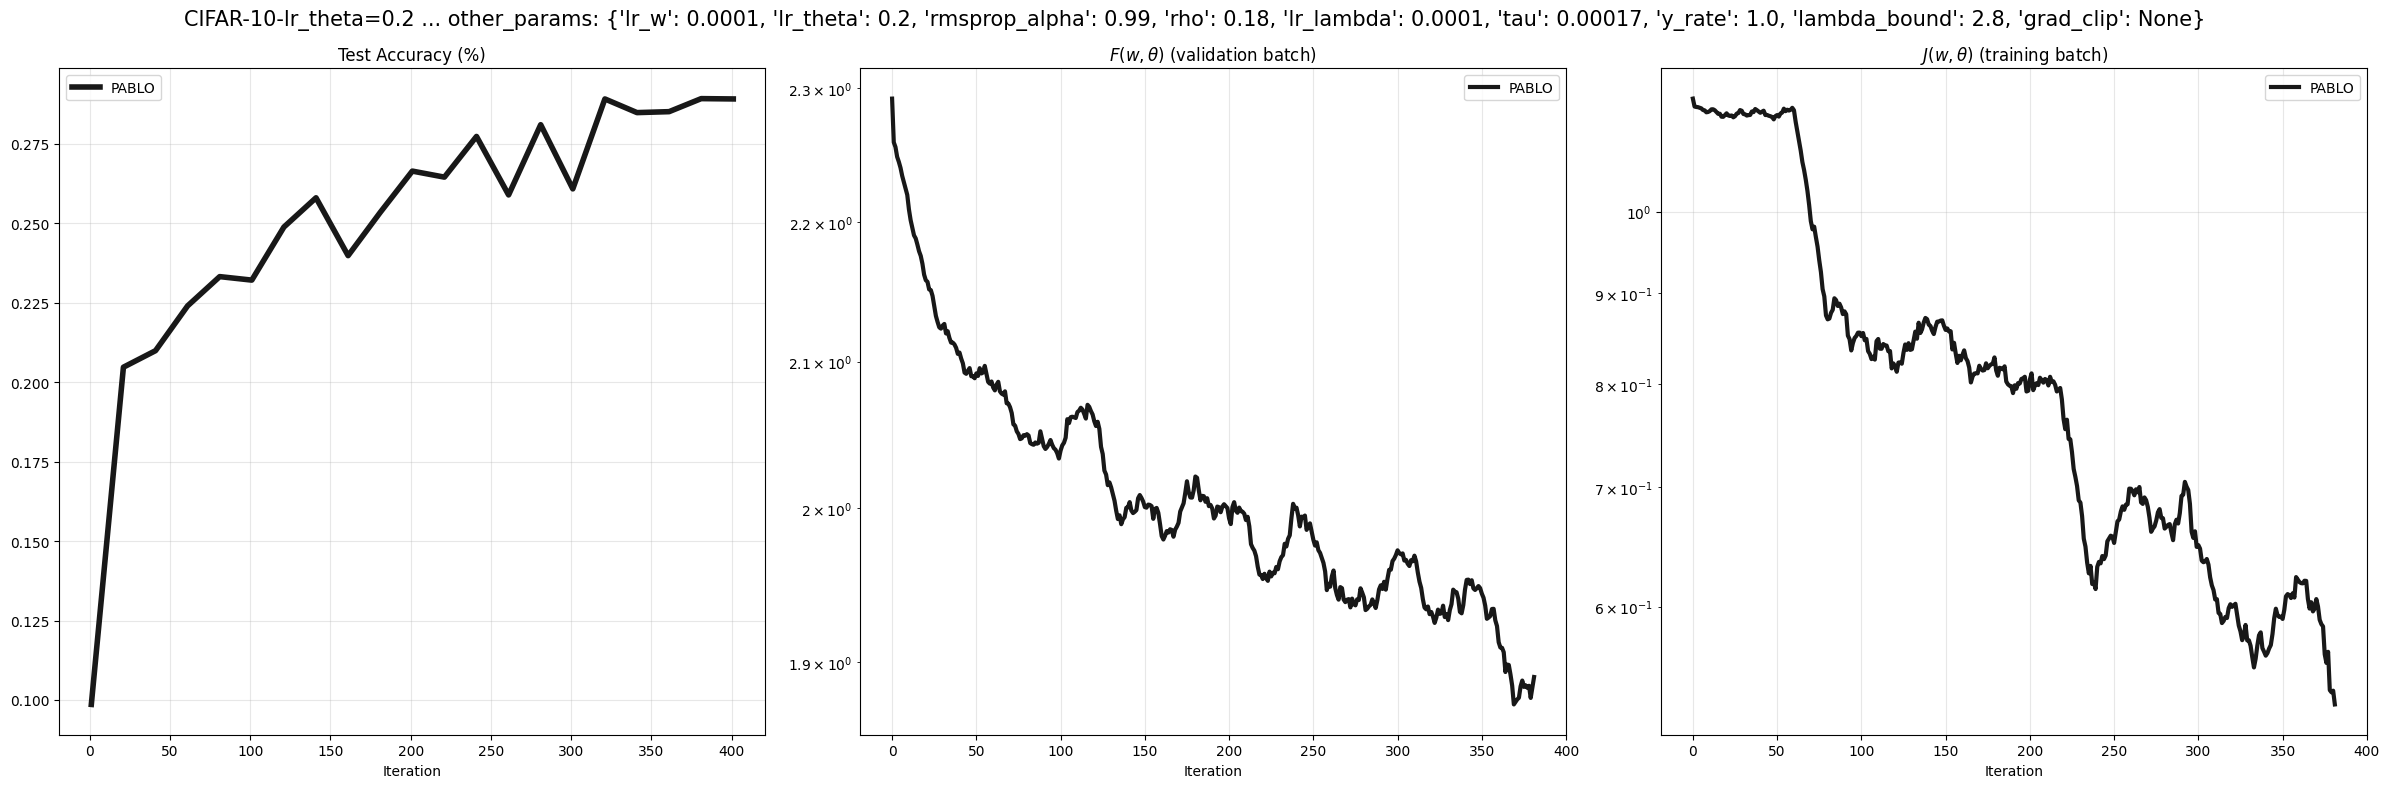

PABLO        100 | LL=0.6915 | UL=2.0029 | test acc=23.06% | clean w=0.356 | corrupt w=0.333 | cleaning F1=57.76% | 32s
PABLO        200 | LL=0.7288 | UL=2.0136 | test acc=26.20% | clean w=0.329 | corrupt w=0.305 | cleaning F1=58.60% | 63s
PABLO        300 | LL=0.8467 | UL=1.8826 | test acc=26.50% | clean w=0.295 | corrupt w=0.260 | cleaning F1=60.88% | 93s
PABLO        400 | LL=0.3285 | UL=1.9730 | test acc=28.63% | clean w=0.249 | corrupt w=0.224 | cleaning F1=61.60% | 123s



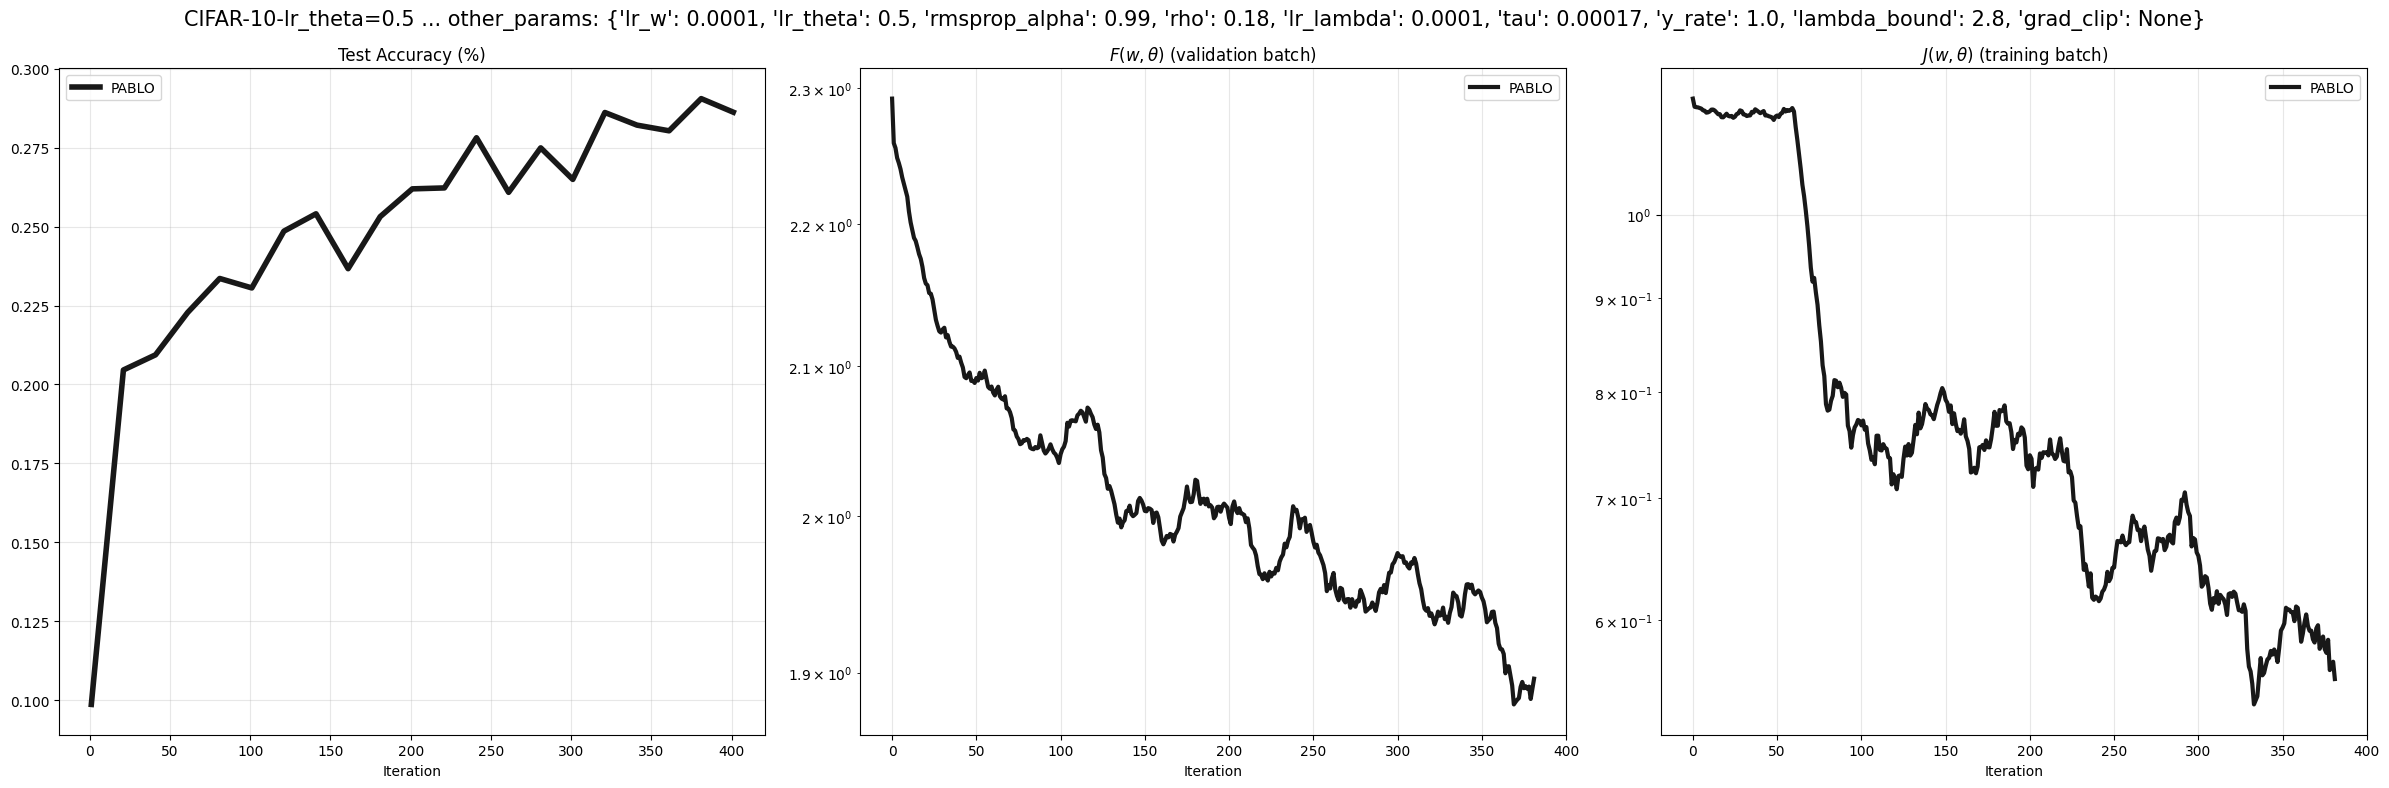

PABLO        100 | LL=0.6915 | UL=2.0029 | test acc=23.06% | clean w=0.356 | corrupt w=0.333 | cleaning F1=57.76% | 32s
PABLO        200 | LL=0.7288 | UL=2.0136 | test acc=26.20% | clean w=0.329 | corrupt w=0.305 | cleaning F1=58.60% | 62s
PABLO        300 | LL=0.8467 | UL=1.8826 | test acc=26.50% | clean w=0.295 | corrupt w=0.260 | cleaning F1=60.88% | 93s
PABLO        400 | LL=0.3285 | UL=1.9730 | test acc=28.63% | clean w=0.249 | corrupt w=0.224 | cleaning F1=61.60% | 123s



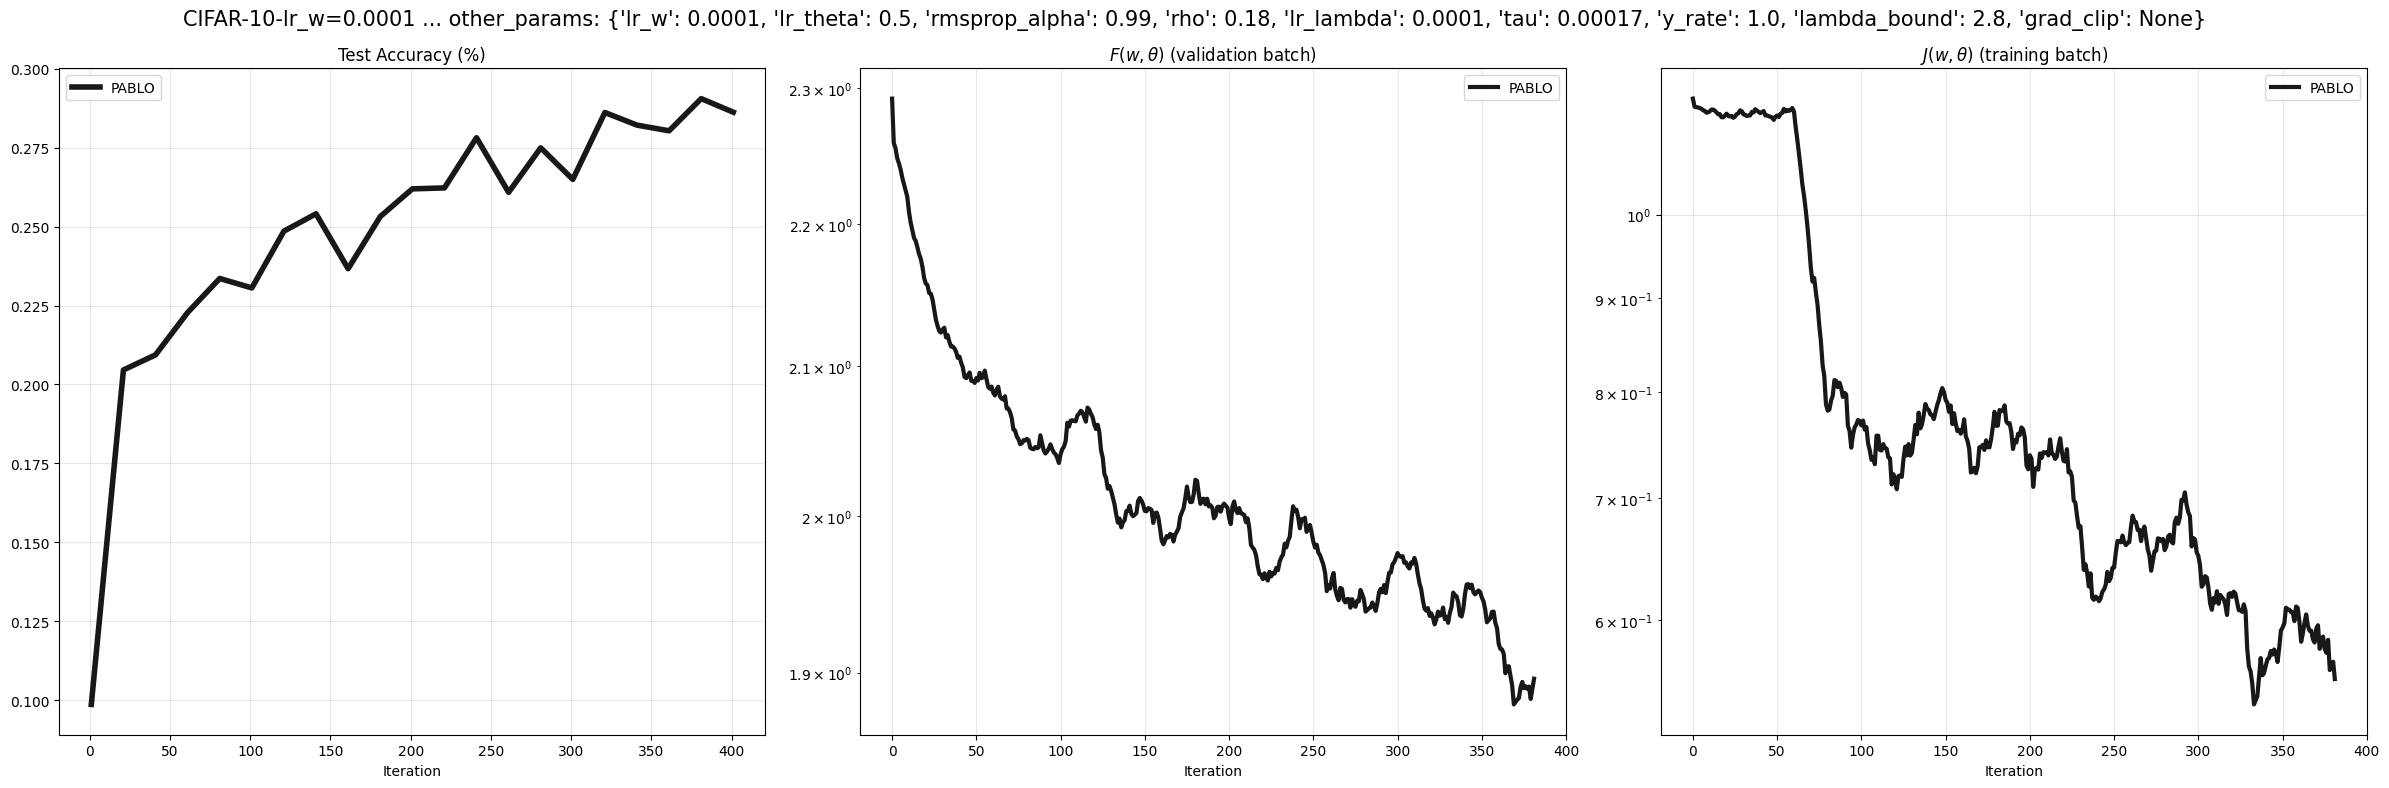

PABLO        100 | LL=0.8496 | UL=1.8692 | test acc=29.63% | clean w=0.344 | corrupt w=0.309 | cleaning F1=59.01% | 32s
PABLO        200 | LL=0.6823 | UL=1.7794 | test acc=34.49% | clean w=0.314 | corrupt w=0.281 | cleaning F1=59.63% | 62s
PABLO        300 | LL=0.6720 | UL=1.6282 | test acc=36.93% | clean w=0.274 | corrupt w=0.226 | cleaning F1=61.98% | 93s
PABLO        400 | LL=0.4644 | UL=1.7130 | test acc=39.52% | clean w=0.229 | corrupt w=0.185 | cleaning F1=63.07% | 123s



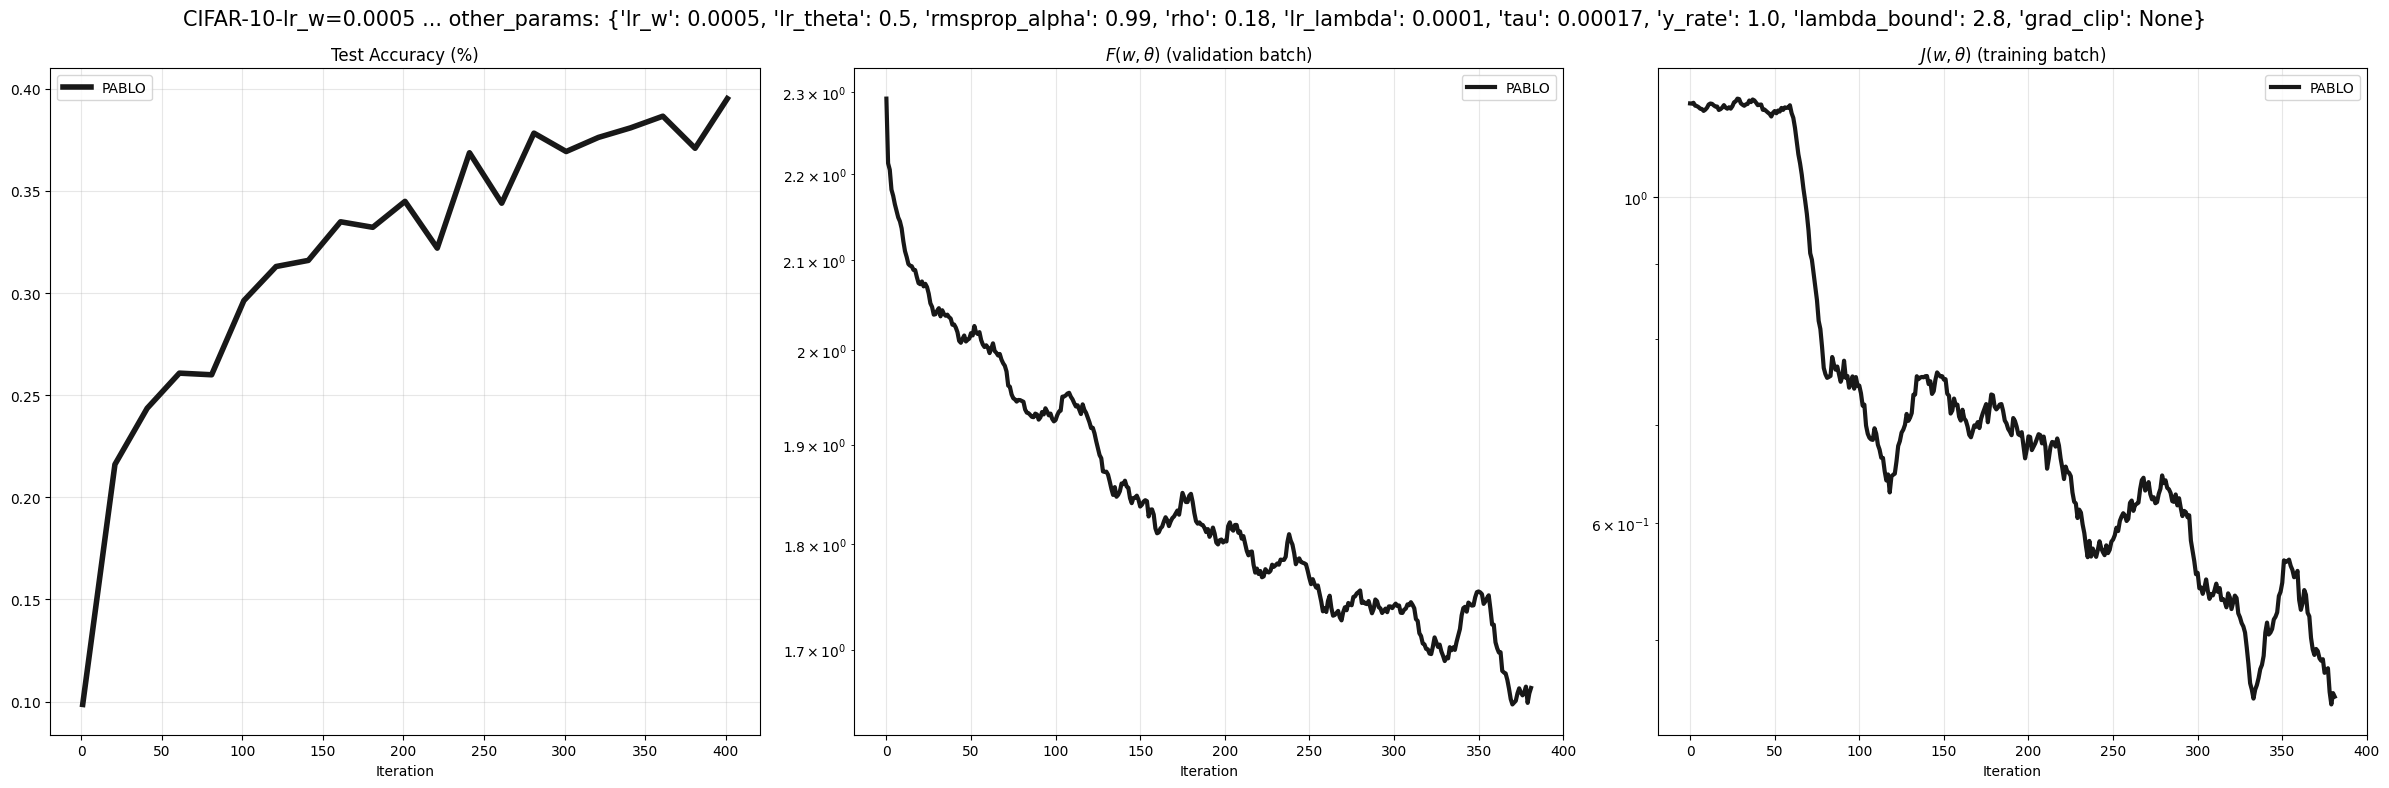

PABLO        100 | LL=0.6901 | UL=1.8678 | test acc=28.64% | clean w=0.342 | corrupt w=0.323 | cleaning F1=58.11% | 32s
PABLO        200 | LL=0.6345 | UL=1.7720 | test acc=32.26% | clean w=0.308 | corrupt w=0.289 | cleaning F1=59.01% | 63s
PABLO        300 | LL=0.6926 | UL=1.6281 | test acc=36.57% | clean w=0.270 | corrupt w=0.240 | cleaning F1=61.20% | 93s
PABLO        400 | LL=0.3786 | UL=1.7215 | test acc=40.02% | clean w=0.222 | corrupt w=0.192 | cleaning F1=62.48% | 124s



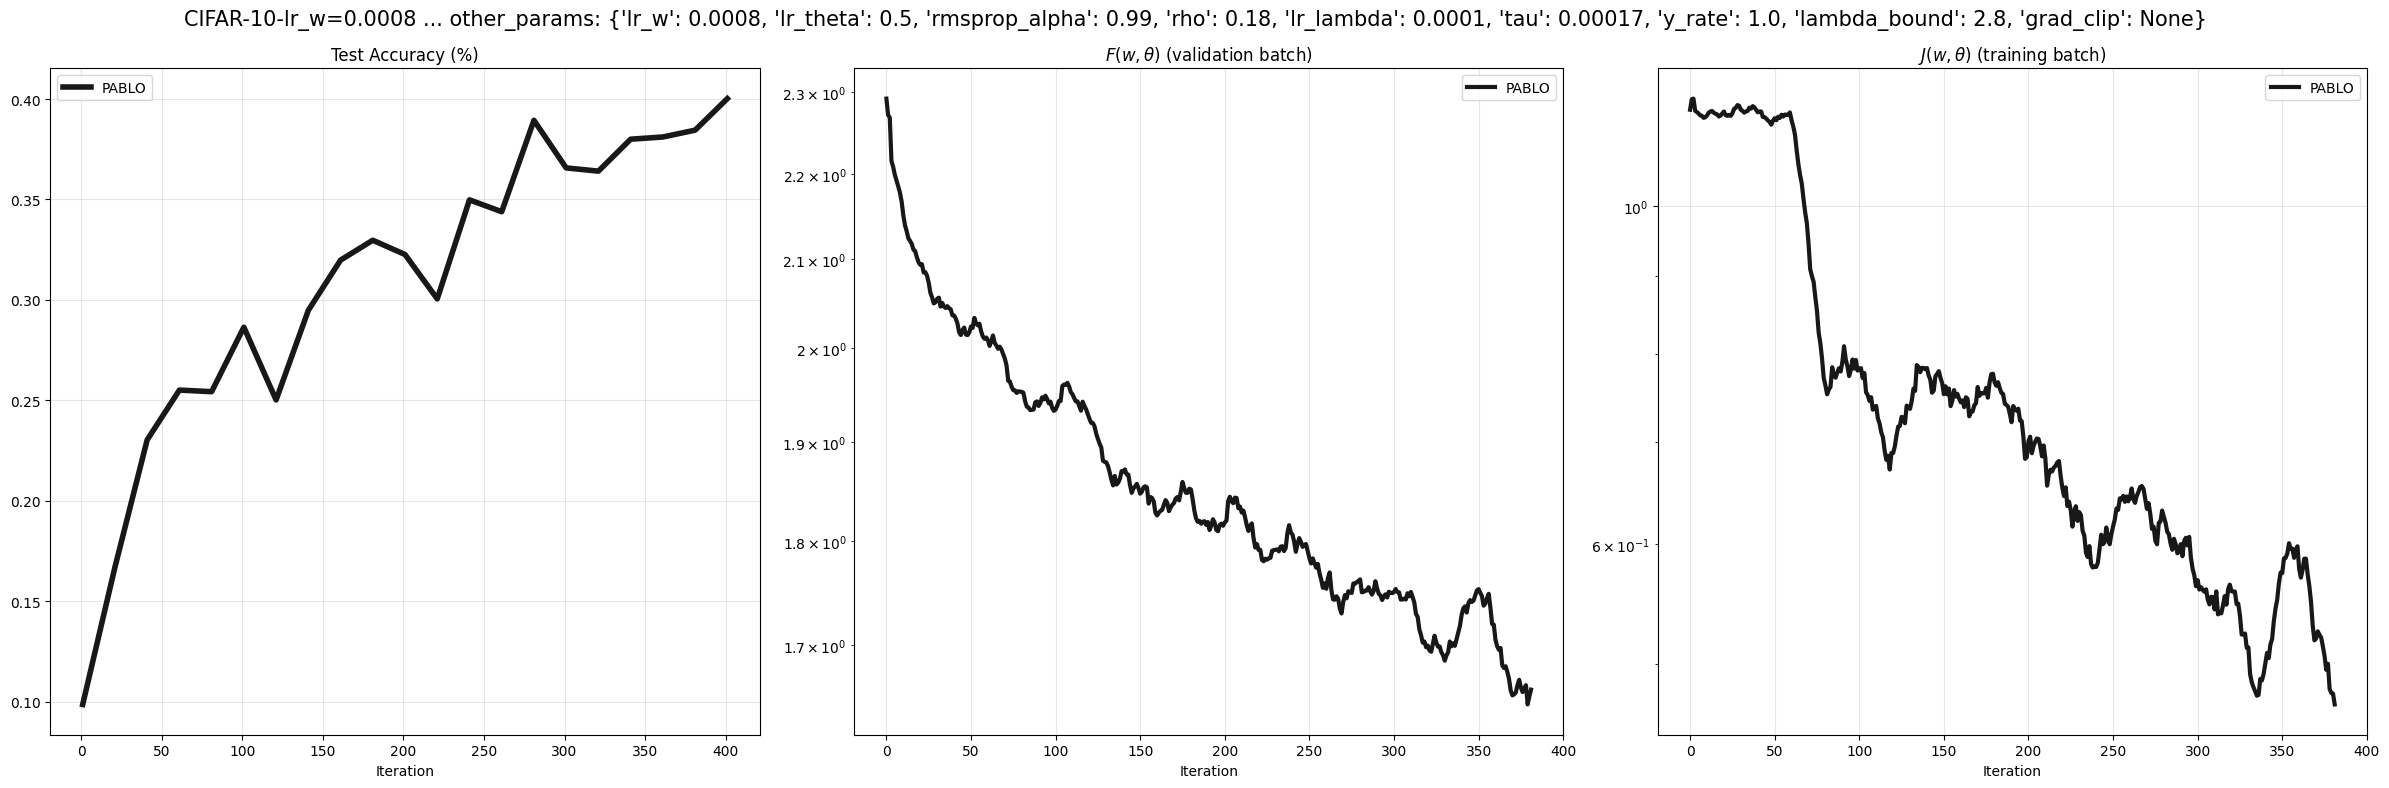

PABLO        100 | LL=0.7397 | UL=1.9084 | test acc=26.48% | clean w=0.350 | corrupt w=0.328 | cleaning F1=58.02% | 33s
PABLO        200 | LL=0.7058 | UL=1.7962 | test acc=32.20% | clean w=0.315 | corrupt w=0.296 | cleaning F1=58.96% | 64s
PABLO        300 | LL=0.8151 | UL=1.6385 | test acc=36.68% | clean w=0.283 | corrupt w=0.251 | cleaning F1=60.62% | 95s
PABLO        400 | LL=0.4461 | UL=1.7056 | test acc=39.62% | clean w=0.239 | corrupt w=0.199 | cleaning F1=62.69% | 126s



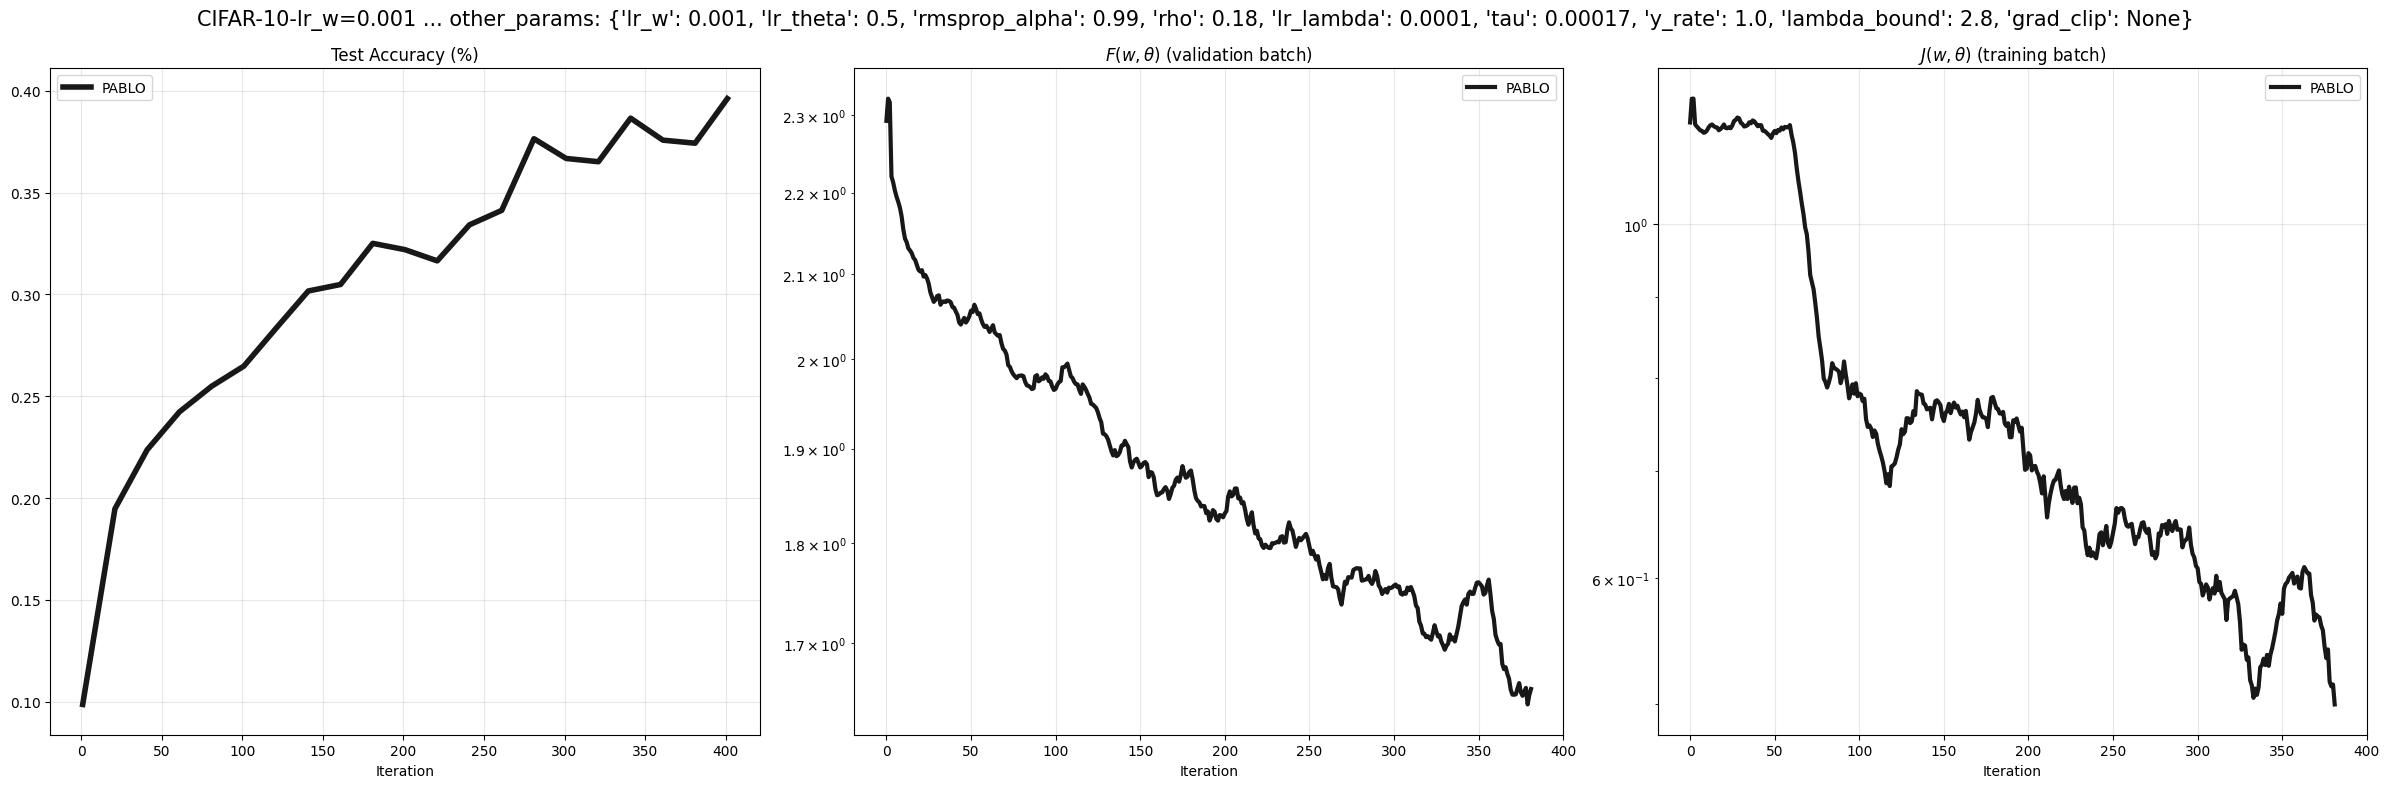

PABLO        100 | LL=0.7612 | UL=2.0959 | test acc=22.63% | clean w=0.387 | corrupt w=0.381 | cleaning F1=55.61% | 33s
PABLO        200 | LL=0.9001 | UL=2.0635 | test acc=26.18% | clean w=0.370 | corrupt w=0.364 | cleaning F1=56.28% | 64s
PABLO        300 | LL=0.9234 | UL=1.9411 | test acc=24.96% | clean w=0.347 | corrupt w=0.338 | cleaning F1=57.18% | 95s
PABLO        400 | LL=0.6658 | UL=2.0259 | test acc=26.98% | clean w=0.321 | corrupt w=0.306 | cleaning F1=58.54% | 126s



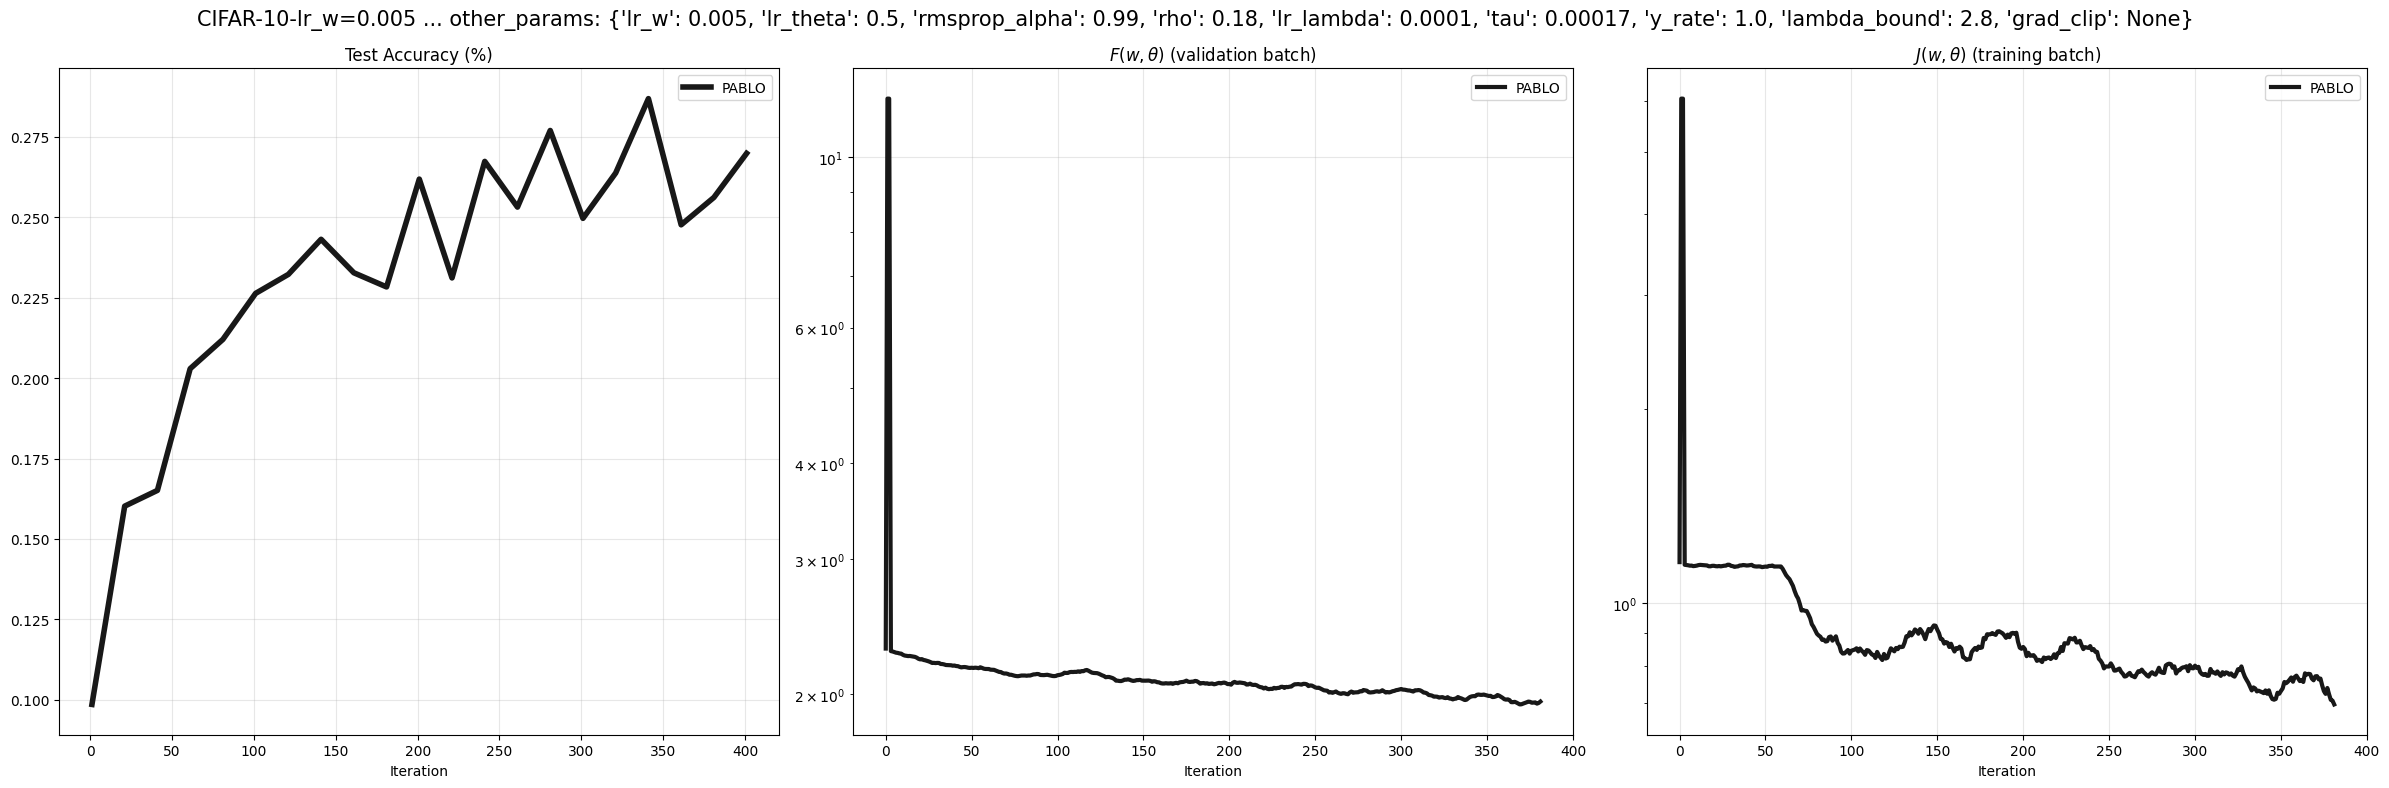

In [24]:
# "PABLO": dict(lr_w=0.004, lr_theta=0.8, rmsprop_alpha=0.99, rho=0.02, lr_lambda=0.0001,tau=0.00017, y_rate=1.0, lambda_bound=2.8, grad_clip=None),

BATCH_SIZE=64
NUM_ITERS = 400
EVAL_EVERY = 20
SEED=0



m = "PABLO"
params_to_test = { 
            #   "lr_theta": [0.1,0.2,0.5],
              "lr_w": [0.0001,0.0005,0.0008,0.001, 0.005],}
              

for param, param_vals in params_to_test.items():
    for param_val in param_vals:

        
        HPARAMS[m][param] = param_val

        results_cifar = {}
        for method in [m]:
            classifier = CIFARClassifier(seed=SEED).to(device)
            weight_model = SampleWeightModel(N_TRAIN).to(device)
            optimiser = build_optimiser(method, classifier, weight_model)

            history = run_hypercleaning(optimiser, classifier, weight_model, datasets_cifar, corrupted_mask_cifar,
                                        num_iters=NUM_ITERS, batch_size=BATCH_SIZE, seed=SEED,
                                        eval_every=EVAL_EVERY, print_every=100, device=device, name=method)
            results_cifar[method] = {"history": history, "classifier": classifier, "weight_model": weight_model}
            print()

        fig, axes = plt.subplots(1, 3, figsize=(24,8))

        for method, r in results_cifar.items():
            h = r["history"]
            axes[0].plot([i+1 for i in h["eval_iterations"]], h["test_accuracy"], color=COLOURS[method], label=method, linewidth=4)
        axes[0].set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3); axes[0].legend()

        for ax, (key, title) in zip(axes[1:], [("ul_loss", r"$F(w,\theta)$ (validation batch)"), ("ll_loss", r"$J(w,\theta)$ (training batch)")]):
            for method, r in results_cifar.items():
                plot_metric(r["history"][key],linewidth=3, plot_type="mov", mean_window=20, logy=True, marker="-", ax=ax)
                ax.lines[-1].set_color(COLOURS[method]); ax.lines[-1].set_label(method)
            ax.set_title(title); ax.set_xlabel("Iteration"); ax.grid(alpha=0.3)
            ax.legend()

        fig.suptitle(f"CIFAR-10-{param}={param_val} ... other_params: {HPARAMS[m]}", fontsize=15)
        plt.tight_layout()
        plt.show()

BOME         100 | LL=1.0921 | UL=1.8852 | test acc=26.73% | clean w=0.489 | corrupt w=0.477 | cleaning F1=59.12% | 48s
BOME         200 | LL=0.9999 | UL=1.8473 | test acc=32.22% | clean w=0.474 | corrupt w=0.437 | cleaning F1=63.48% | 90s
BOME         300 | LL=0.9920 | UL=1.6074 | test acc=37.75% | clean w=0.460 | corrupt w=0.397 | cleaning F1=64.98% | 132s
BOME         400 | LL=0.9169 | UL=1.5904 | test acc=38.20% | clean w=0.441 | corrupt w=0.351 | cleaning F1=66.65% | 172s



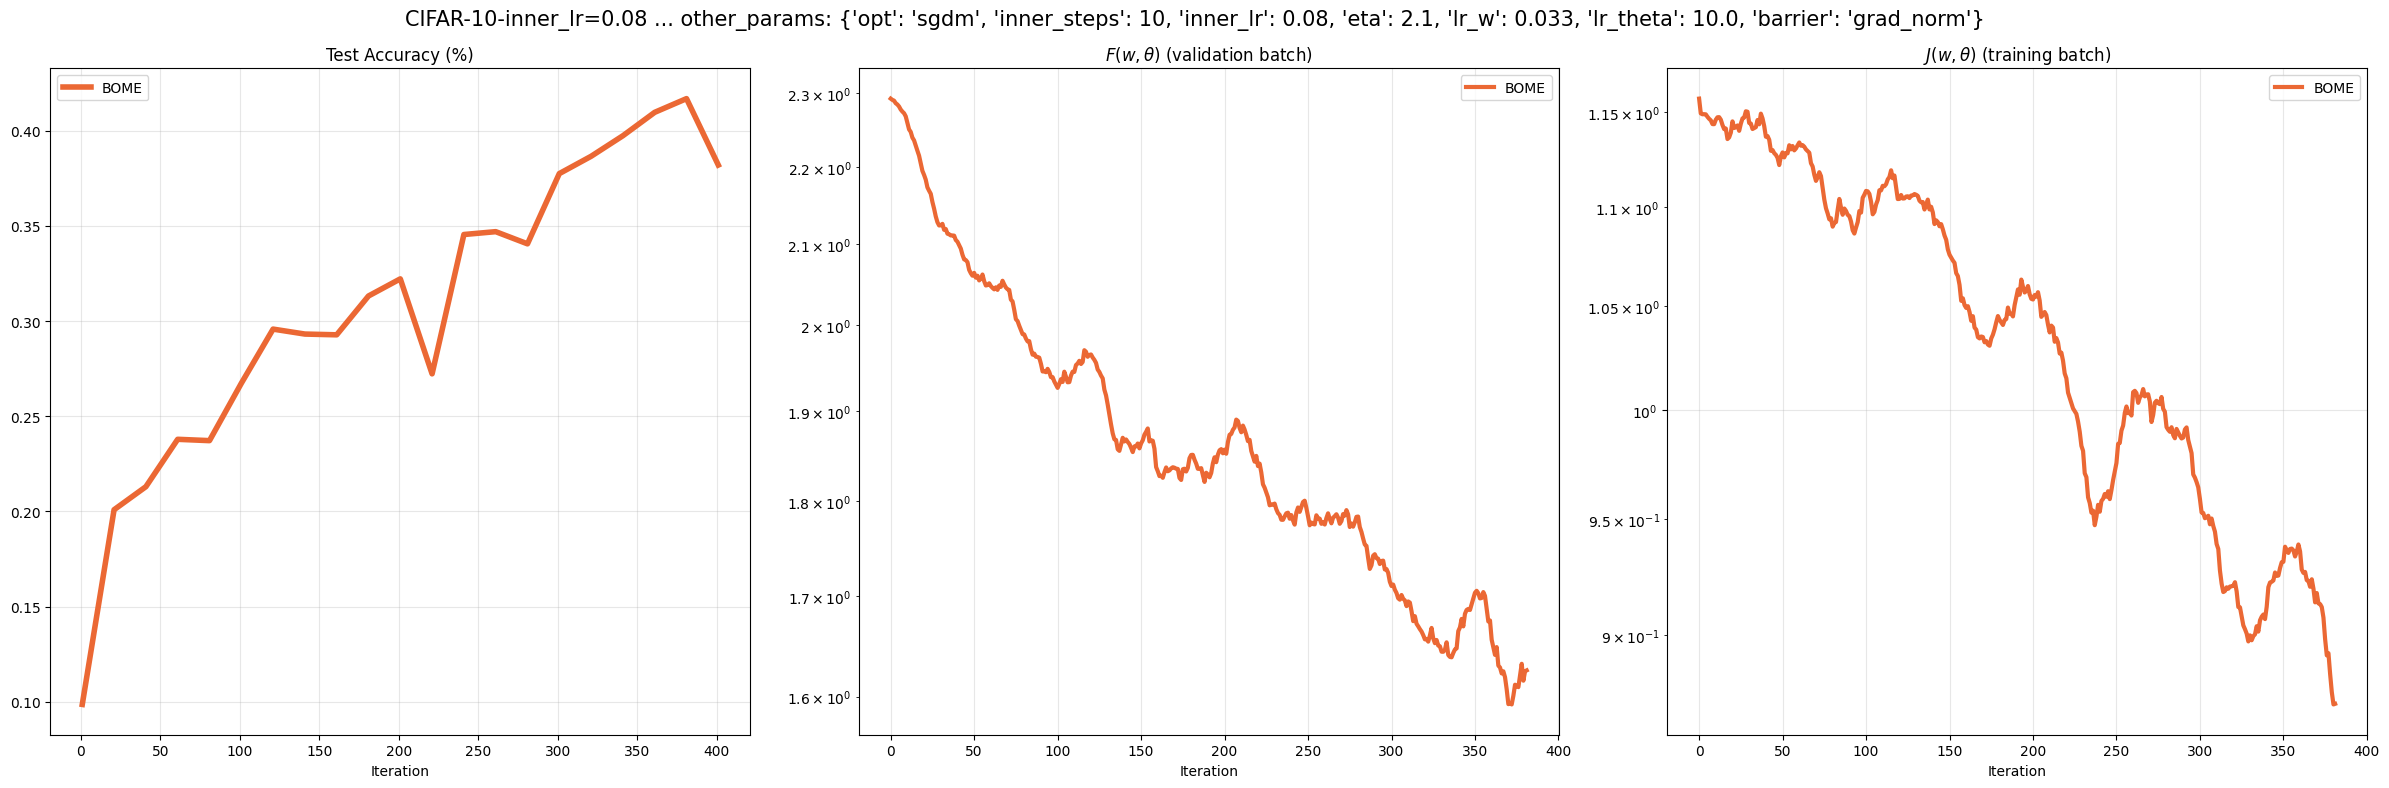

BOME         100 | LL=1.0617 | UL=1.8768 | test acc=26.58% | clean w=0.474 | corrupt w=0.460 | cleaning F1=58.51% | 47s
BOME         200 | LL=0.9339 | UL=1.8129 | test acc=32.74% | clean w=0.452 | corrupt w=0.404 | cleaning F1=63.53% | 95s
BOME         300 | LL=0.8974 | UL=1.6360 | test acc=36.81% | clean w=0.428 | corrupt w=0.347 | cleaning F1=65.70% | 140s
BOME         400 | LL=0.7632 | UL=1.5851 | test acc=39.71% | clean w=0.401 | corrupt w=0.292 | cleaning F1=67.06% | 184s



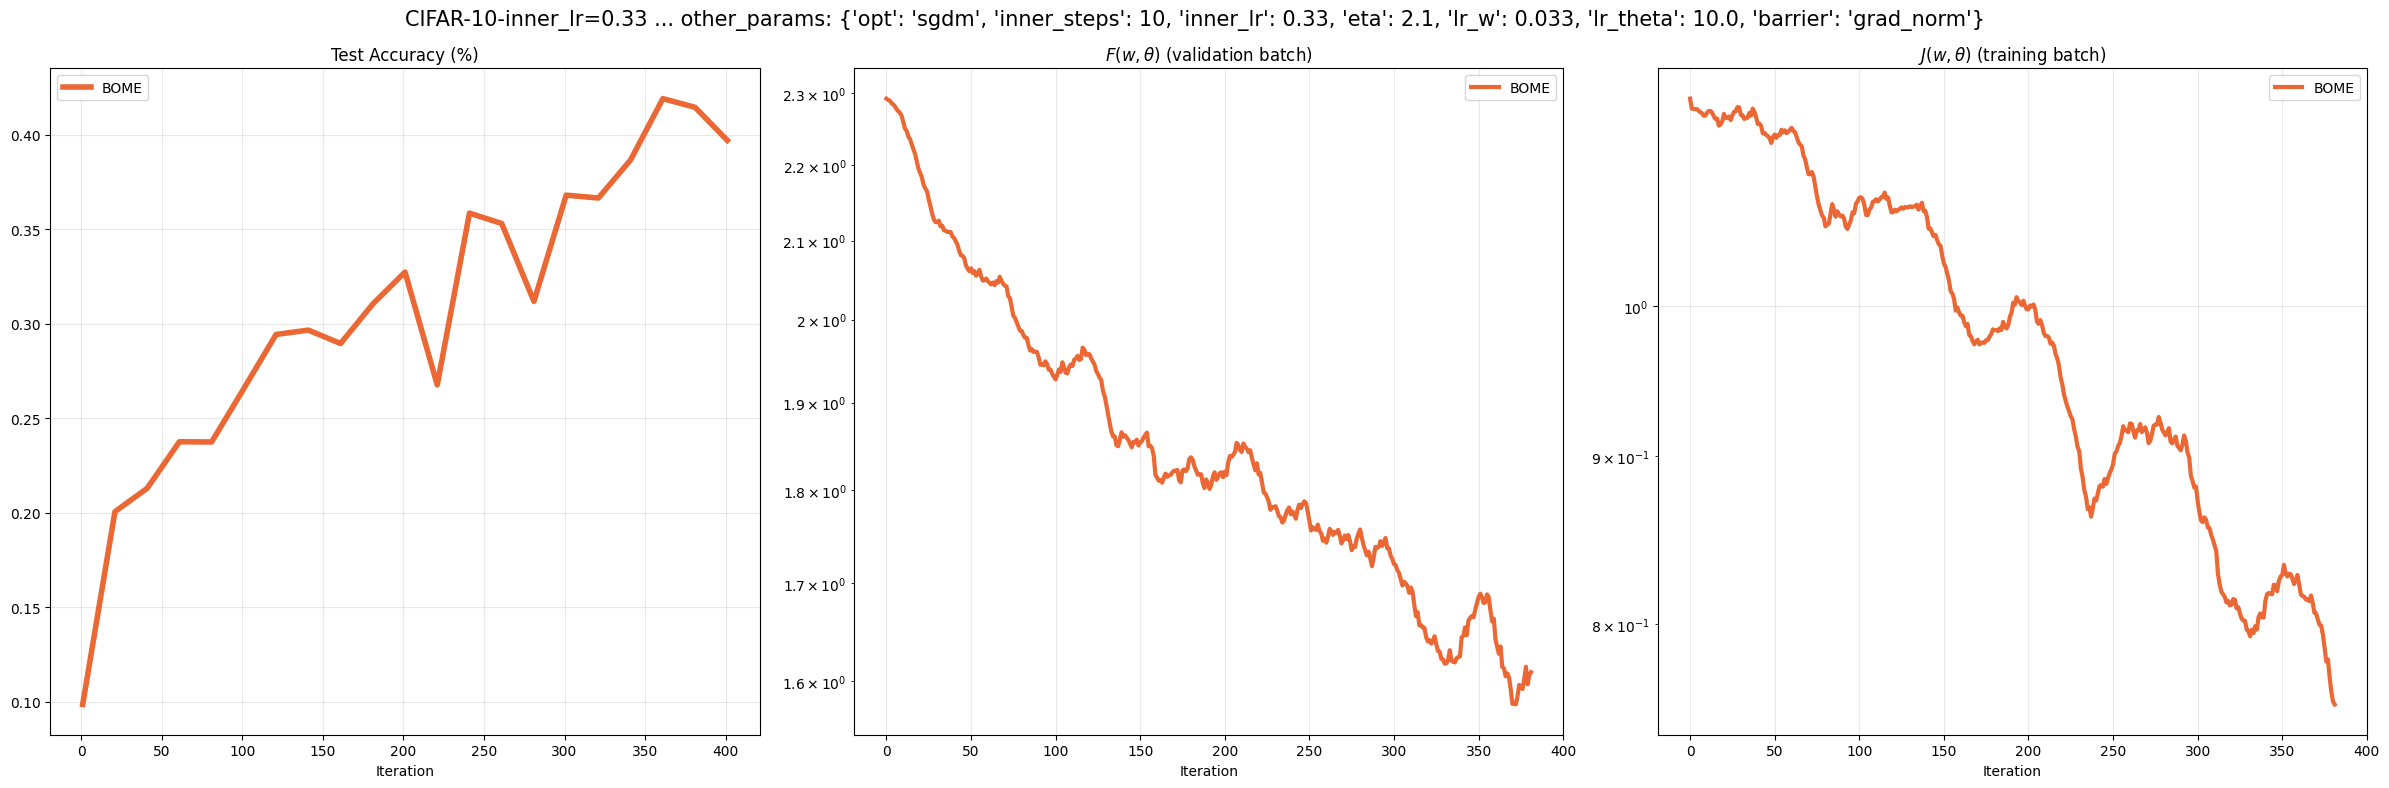

BOME         100 | LL=1.0576 | UL=1.8636 | test acc=26.31% | clean w=0.484 | corrupt w=0.453 | cleaning F1=60.20% | 46s
BOME         200 | LL=0.9888 | UL=1.7990 | test acc=33.18% | clean w=0.498 | corrupt w=0.396 | cleaning F1=65.64% | 89s
BOME         300 | LL=0.8980 | UL=1.5730 | test acc=36.92% | clean w=0.527 | corrupt w=0.348 | cleaning F1=69.11% | 133s
BOME         400 | LL=0.8496 | UL=1.6245 | test acc=40.32% | clean w=0.577 | corrupt w=0.324 | cleaning F1=71.32% | 177s



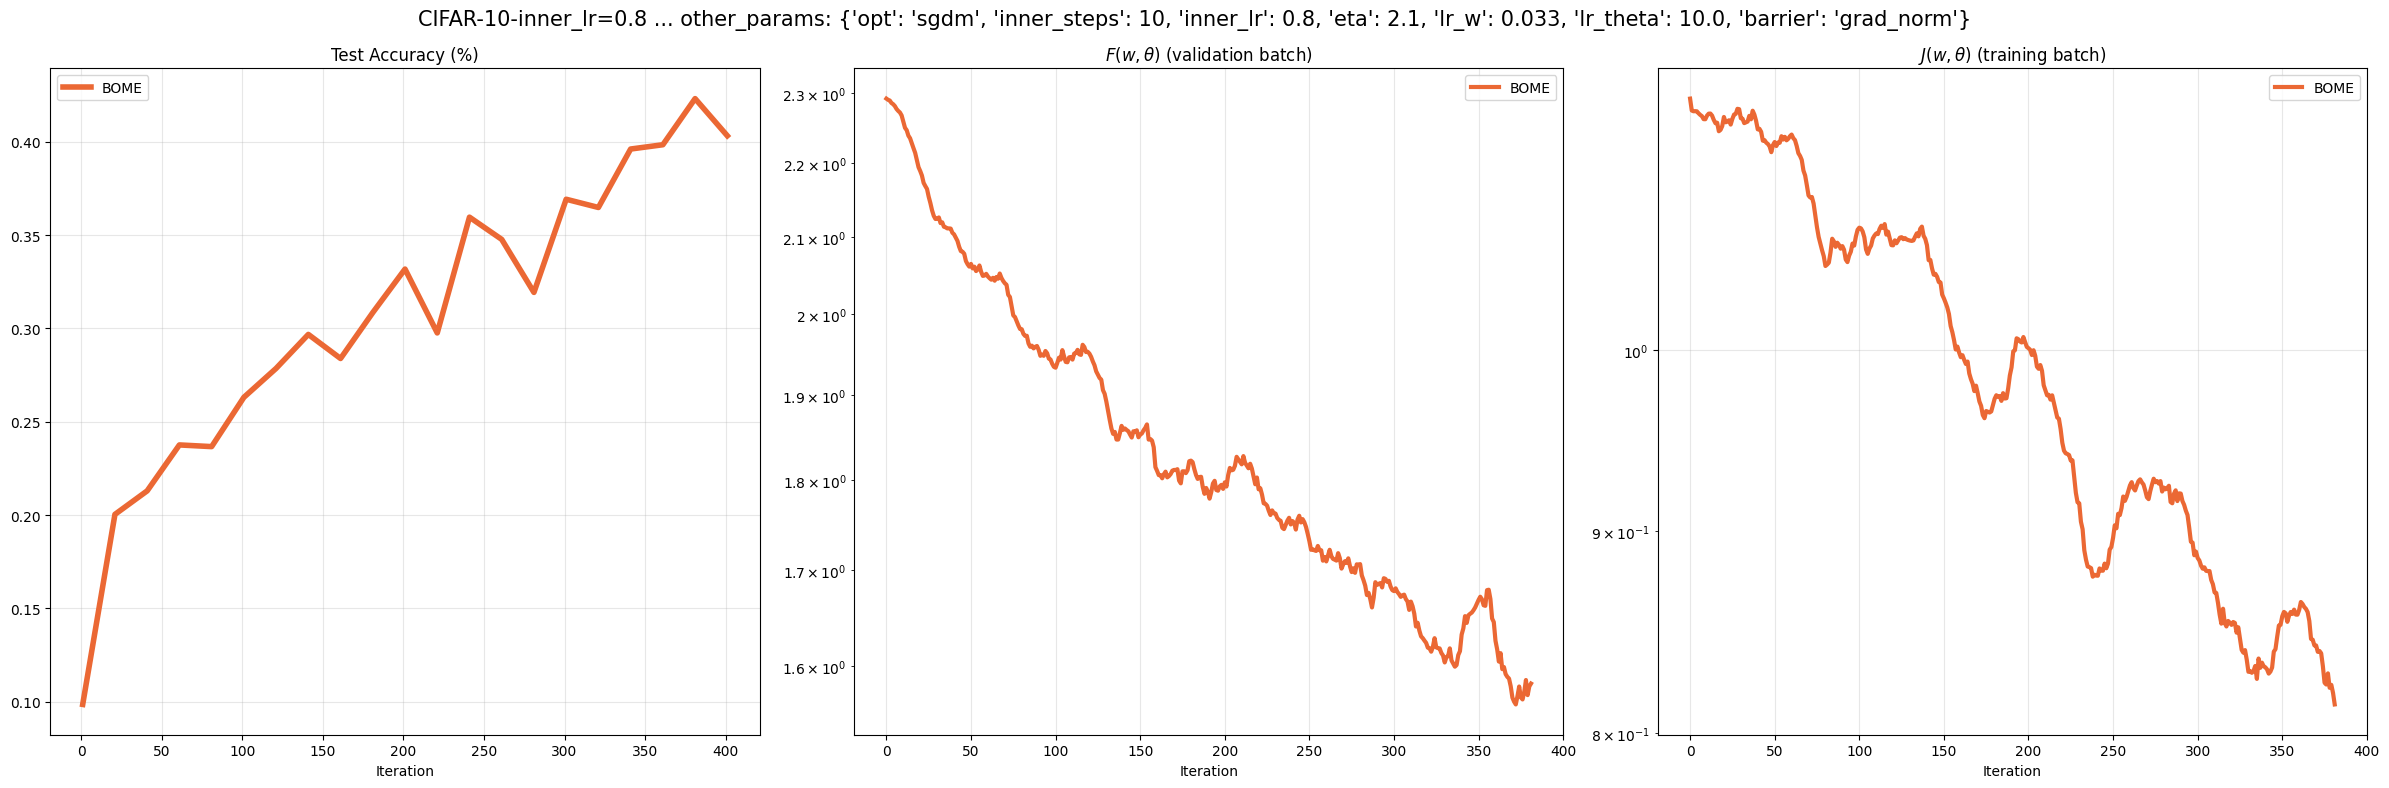

BOME         100 | LL=1.1380 | UL=1.8875 | test acc=25.47% | clean w=0.498 | corrupt w=0.494 | cleaning F1=45.02% | 45s
BOME         200 | LL=1.1740 | UL=1.7299 | test acc=31.55% | clean w=0.501 | corrupt w=0.482 | cleaning F1=54.07% | 89s
BOME         300 | LL=1.2914 | UL=1.4790 | test acc=36.66% | clean w=0.503 | corrupt w=0.474 | cleaning F1=58.99% | 134s
BOME         400 | LL=1.3963 | UL=1.5651 | test acc=39.30% | clean w=0.514 | corrupt w=0.470 | cleaning F1=62.96% | 178s



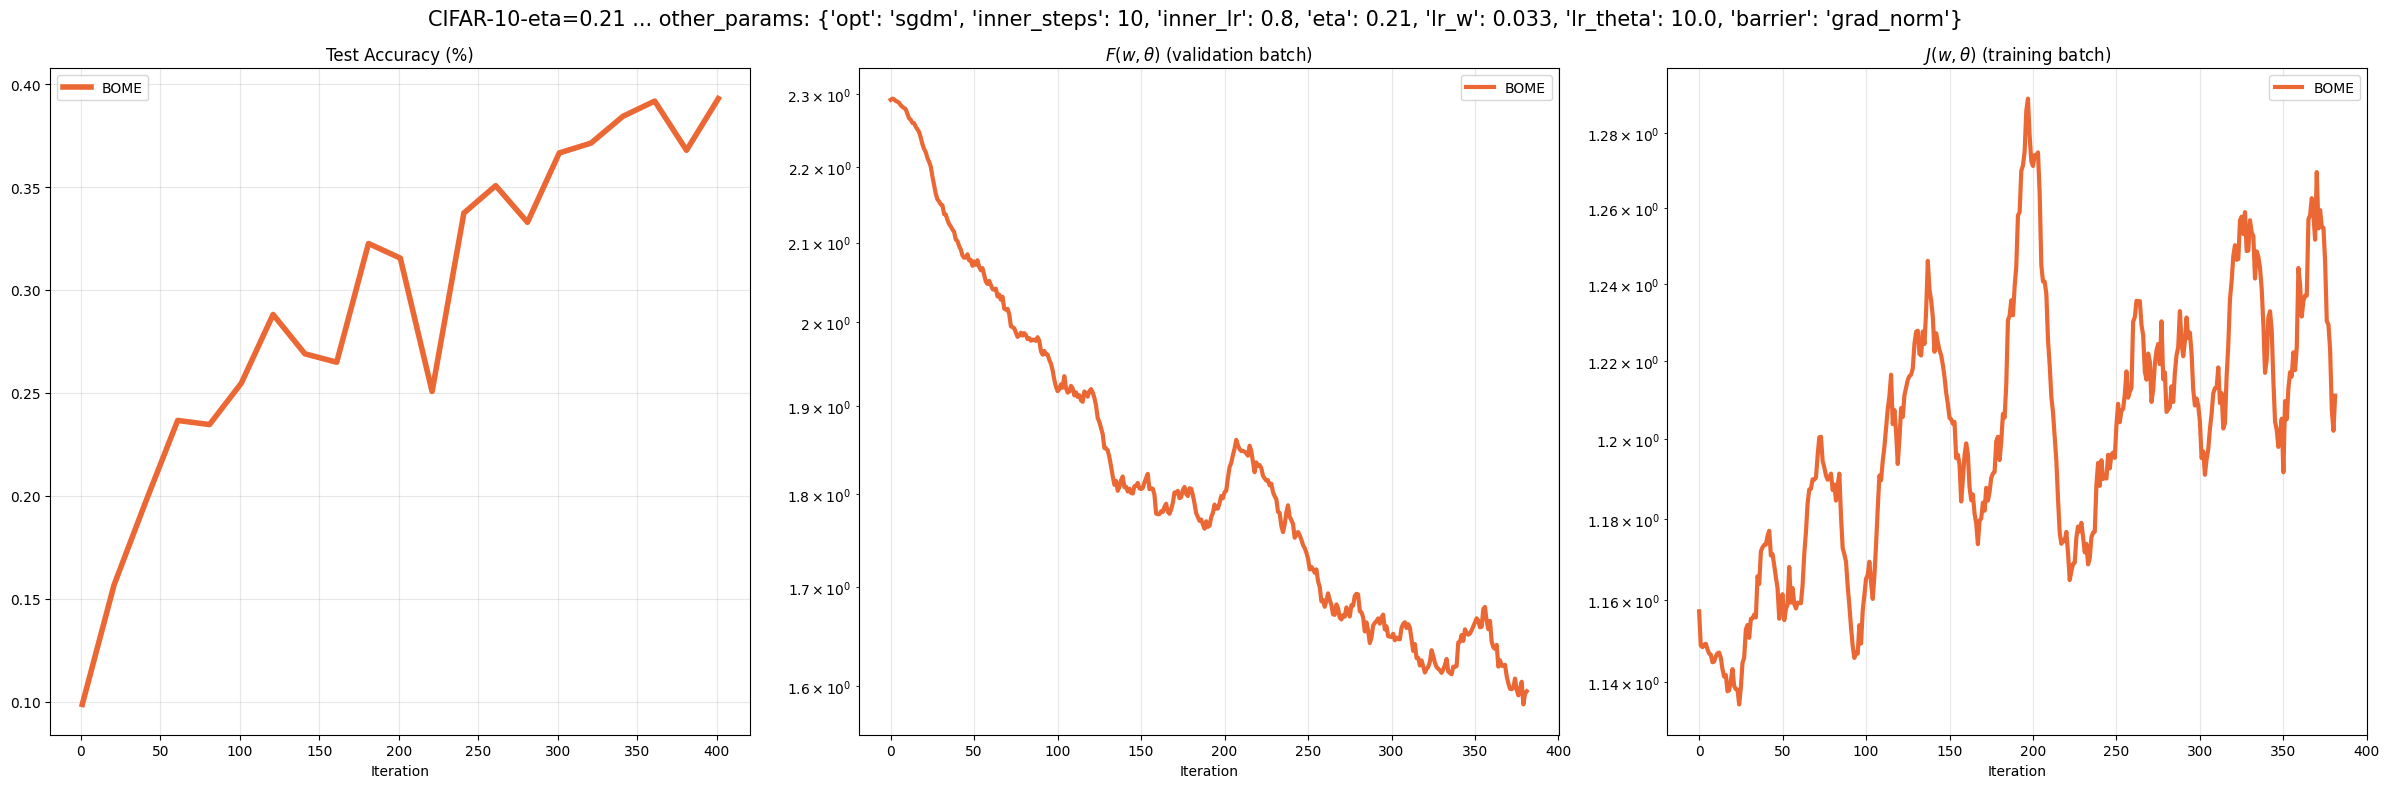

BOME         100 | LL=1.1122 | UL=1.8775 | test acc=26.95% | clean w=0.493 | corrupt w=0.476 | cleaning F1=58.38% | 46s
BOME         200 | LL=1.0479 | UL=1.7464 | test acc=34.72% | clean w=0.505 | corrupt w=0.442 | cleaning F1=63.72% | 90s
BOME         300 | LL=1.0496 | UL=1.5095 | test acc=37.98% | clean w=0.519 | corrupt w=0.412 | cleaning F1=67.65% | 134s
BOME diverged at iteration 389: LL=nan UL=nan



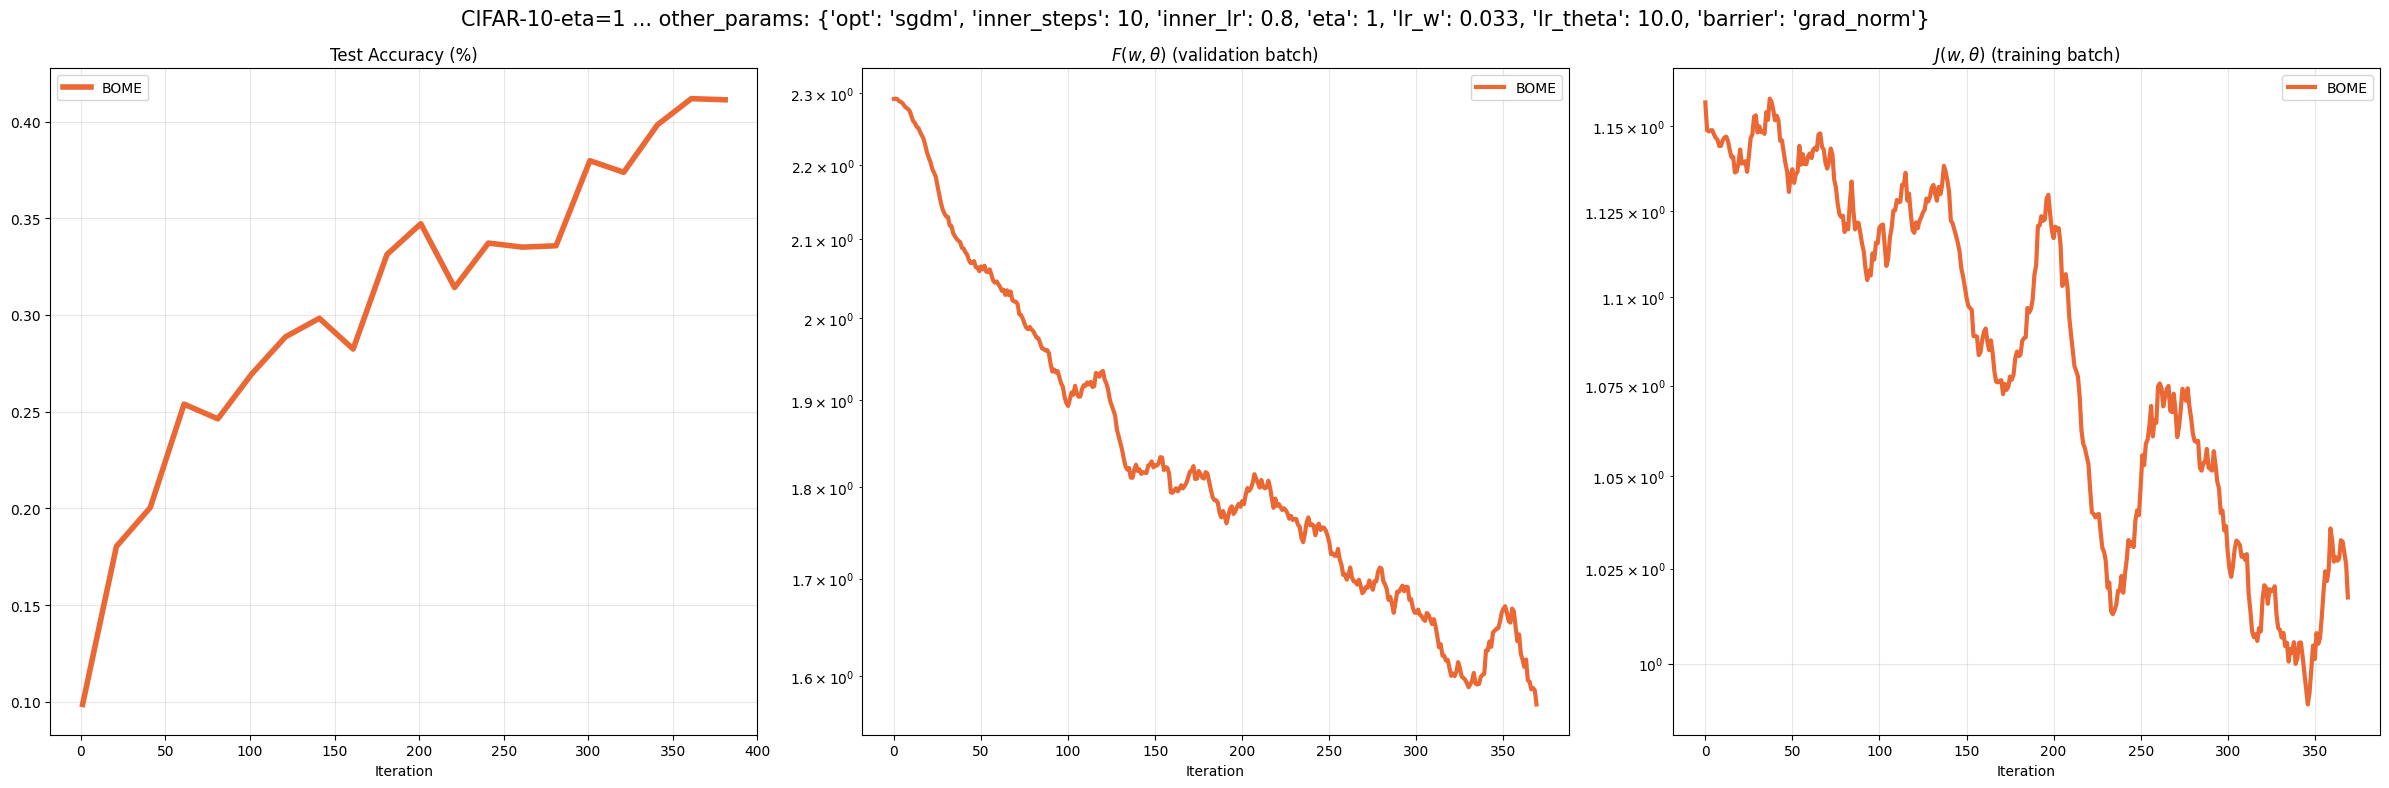

BOME         100 | LL=1.0576 | UL=1.8636 | test acc=26.31% | clean w=0.484 | corrupt w=0.453 | cleaning F1=60.20% | 47s
BOME         200 | LL=0.9888 | UL=1.7990 | test acc=33.18% | clean w=0.498 | corrupt w=0.396 | cleaning F1=65.64% | 96s
BOME         300 | LL=0.8980 | UL=1.5730 | test acc=36.92% | clean w=0.527 | corrupt w=0.348 | cleaning F1=69.11% | 142s
BOME         400 | LL=0.8496 | UL=1.6245 | test acc=40.32% | clean w=0.577 | corrupt w=0.324 | cleaning F1=71.32% | 188s



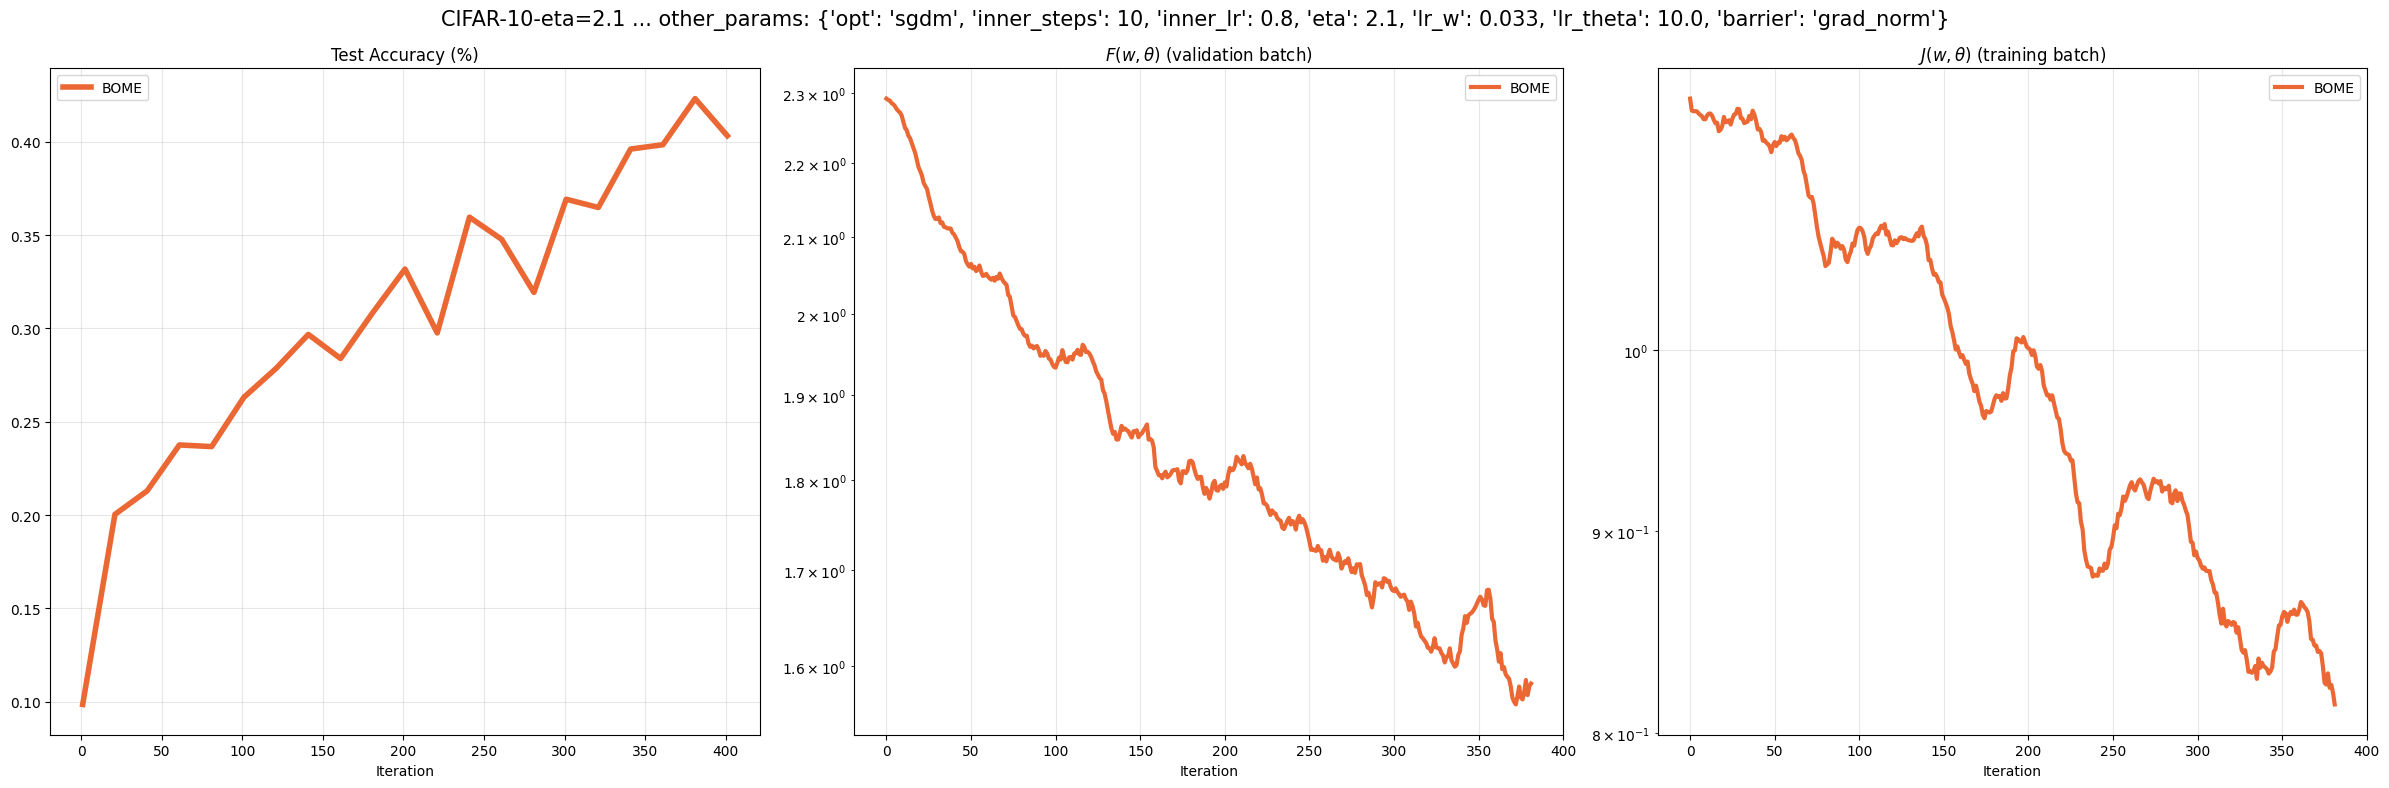

BOME         100 | LL=1.0640 | UL=2.2600 | test acc=14.59% | clean w=0.462 | corrupt w=0.471 | cleaning F1=56.67% | 49s
BOME         200 | LL=0.9885 | UL=2.1663 | test acc=22.38% | clean w=0.429 | corrupt w=0.442 | cleaning F1=57.89% | 95s
BOME         300 | LL=0.9524 | UL=2.0247 | test acc=22.20% | clean w=0.413 | corrupt w=0.389 | cleaning F1=62.09% | 142s
BOME         400 | LL=0.8039 | UL=2.0267 | test acc=23.23% | clean w=0.416 | corrupt w=0.344 | cleaning F1=64.69% | 188s



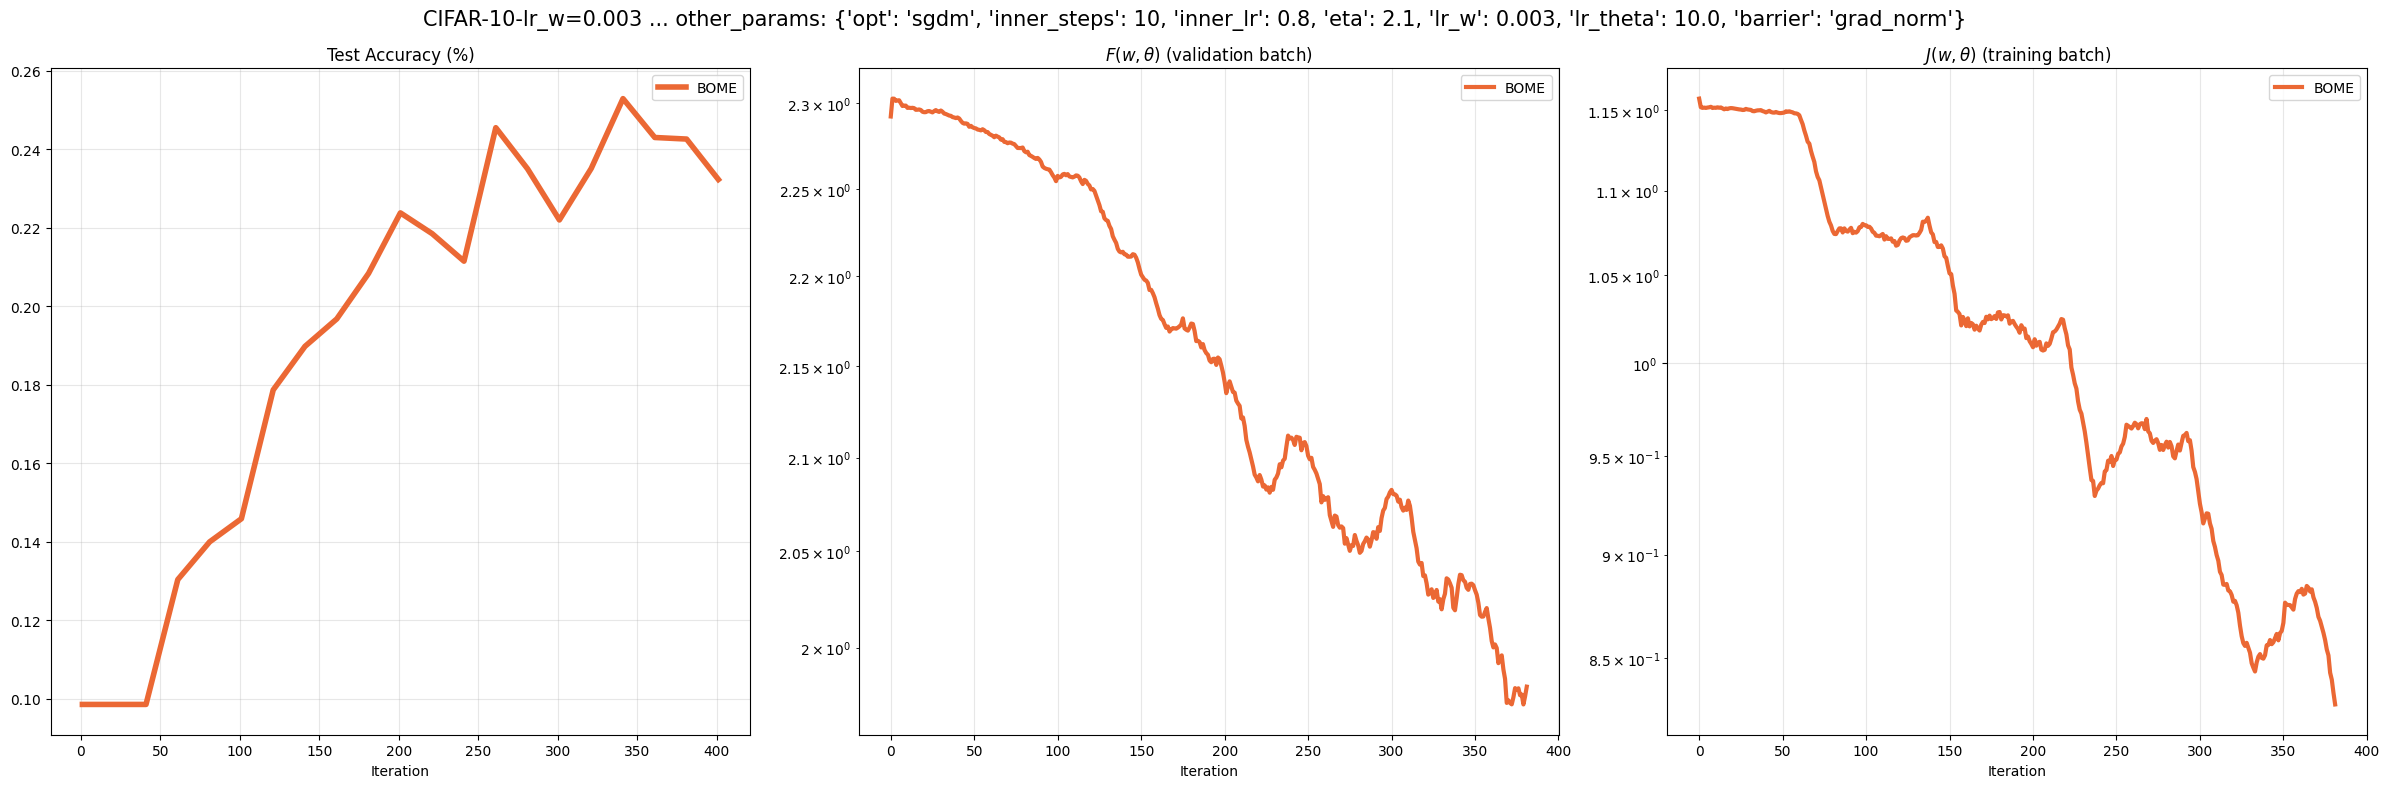

BOME         100 | LL=1.0321 | UL=2.0712 | test acc=20.83% | clean w=0.467 | corrupt w=0.470 | cleaning F1=56.80% | 47s
BOME         200 | LL=0.9937 | UL=1.9955 | test acc=26.06% | clean w=0.459 | corrupt w=0.416 | cleaning F1=61.71% | 92s
BOME         300 | LL=0.9083 | UL=1.7139 | test acc=26.77% | clean w=0.495 | corrupt w=0.374 | cleaning F1=65.06% | 137s
BOME         400 | LL=0.8352 | UL=1.8203 | test acc=33.64% | clean w=0.550 | corrupt w=0.345 | cleaning F1=68.24% | 181s



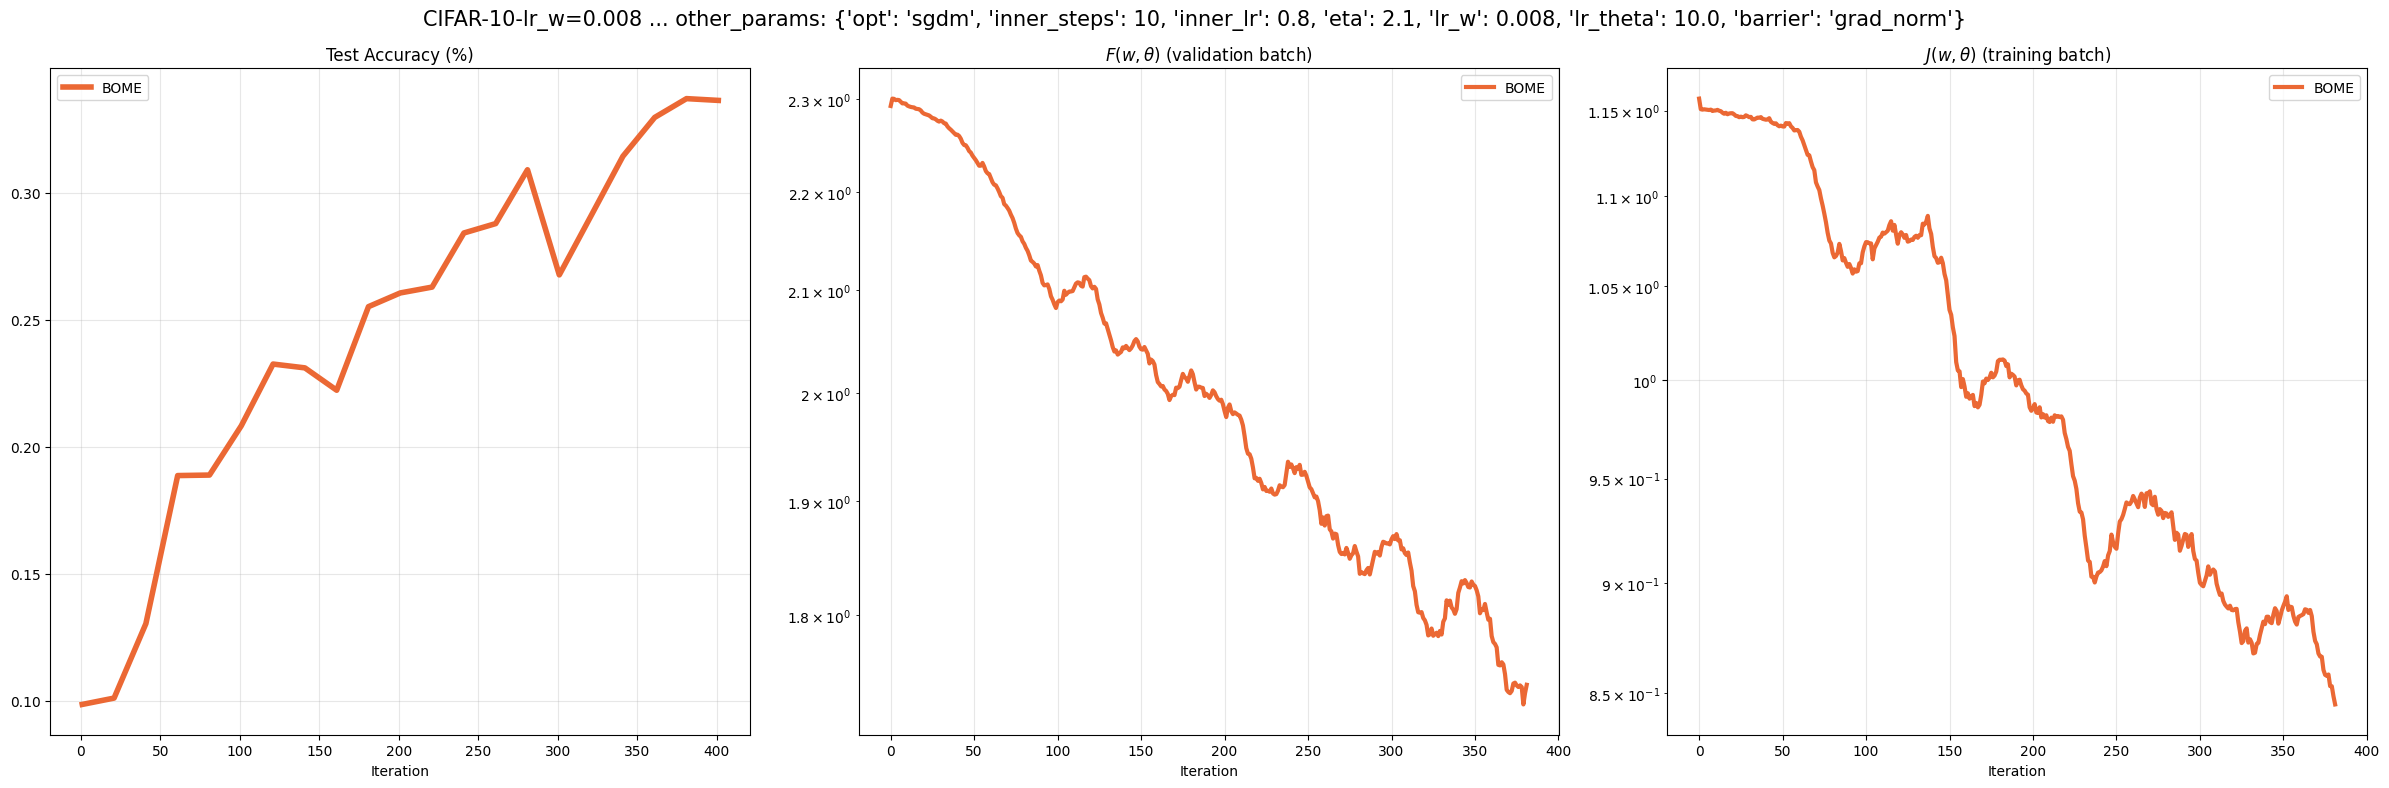

BOME         100 | LL=1.0576 | UL=1.8636 | test acc=26.31% | clean w=0.484 | corrupt w=0.453 | cleaning F1=60.20% | 47s
BOME         200 | LL=0.9888 | UL=1.7990 | test acc=33.18% | clean w=0.498 | corrupt w=0.396 | cleaning F1=65.64% | 91s
BOME         300 | LL=0.8980 | UL=1.5730 | test acc=36.92% | clean w=0.527 | corrupt w=0.348 | cleaning F1=69.11% | 134s
BOME         400 | LL=0.8496 | UL=1.6245 | test acc=40.32% | clean w=0.577 | corrupt w=0.324 | cleaning F1=71.32% | 178s



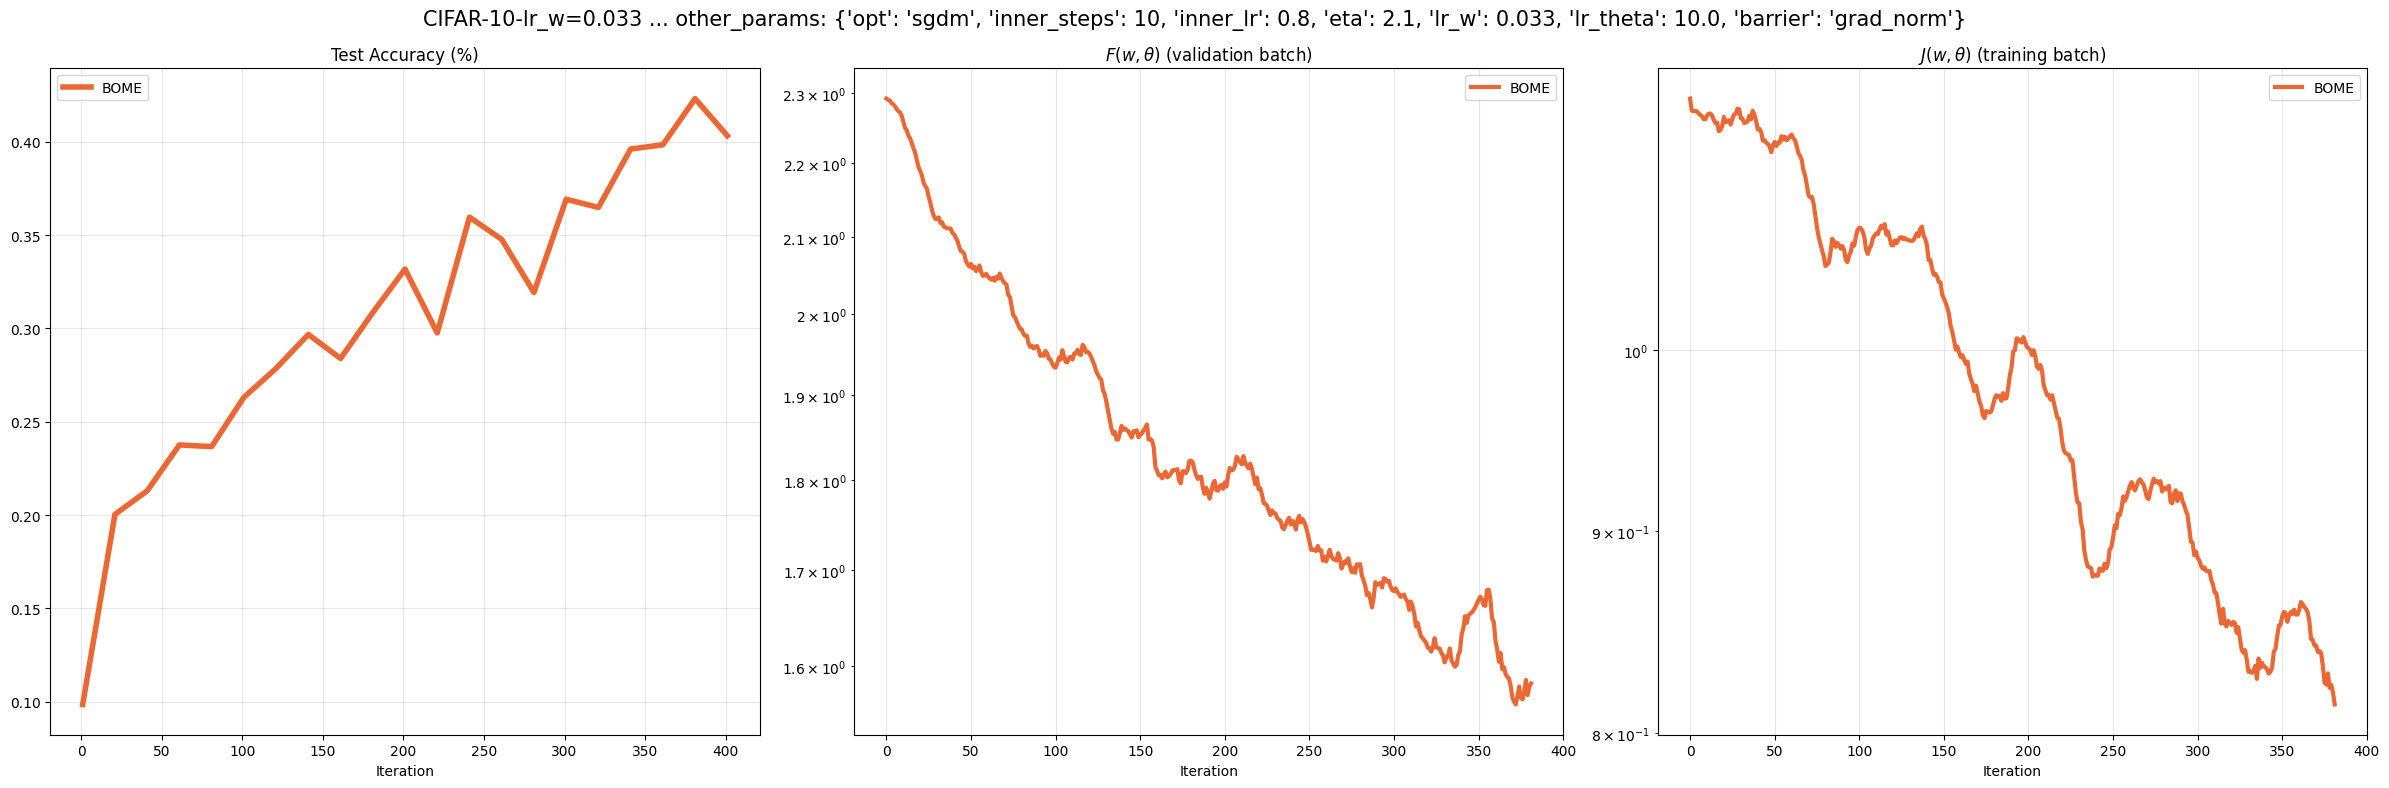

BOME         100 | LL=1.0881 | UL=1.8606 | test acc=27.51% | clean w=0.476 | corrupt w=0.453 | cleaning F1=58.77% | 46s
BOME         200 | LL=0.8585 | UL=1.7794 | test acc=33.88% | clean w=0.458 | corrupt w=0.389 | cleaning F1=63.71% | 90s
BOME         300 | LL=0.8657 | UL=1.5993 | test acc=36.68% | clean w=0.428 | corrupt w=0.327 | cleaning F1=65.90% | 133s
BOME         400 | LL=0.7159 | UL=1.6135 | test acc=41.68% | clean w=0.391 | corrupt w=0.265 | cleaning F1=67.69% | 177s



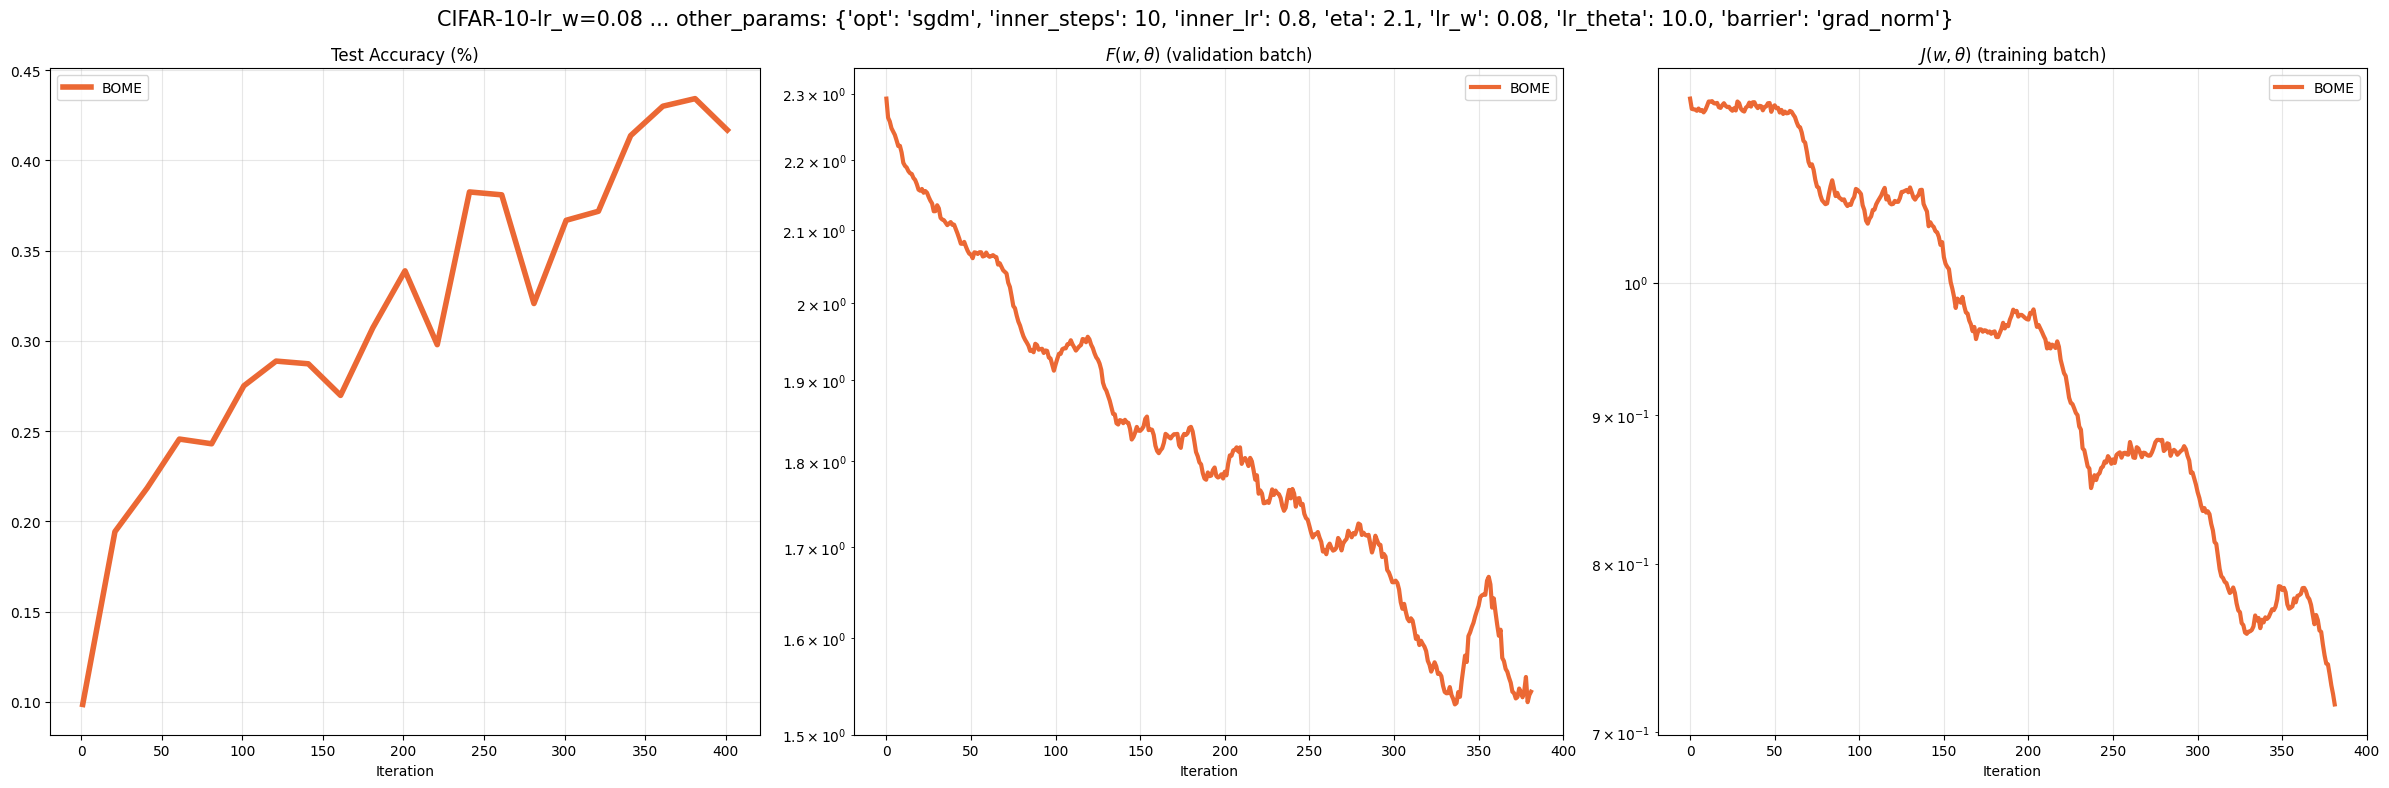

BOME         100 | LL=1.1907 | UL=1.9052 | test acc=28.00% | clean w=0.497 | corrupt w=0.495 | cleaning F1=58.58% | 48s
BOME         200 | LL=1.0679 | UL=1.8425 | test acc=30.86% | clean w=0.495 | corrupt w=0.485 | cleaning F1=63.95% | 91s
BOME         300 | LL=1.0960 | UL=1.7213 | test acc=32.04% | clean w=0.492 | corrupt w=0.475 | cleaning F1=66.02% | 135s
BOME         400 | LL=1.1071 | UL=1.5900 | test acc=42.83% | clean w=0.487 | corrupt w=0.461 | cleaning F1=67.33% | 178s



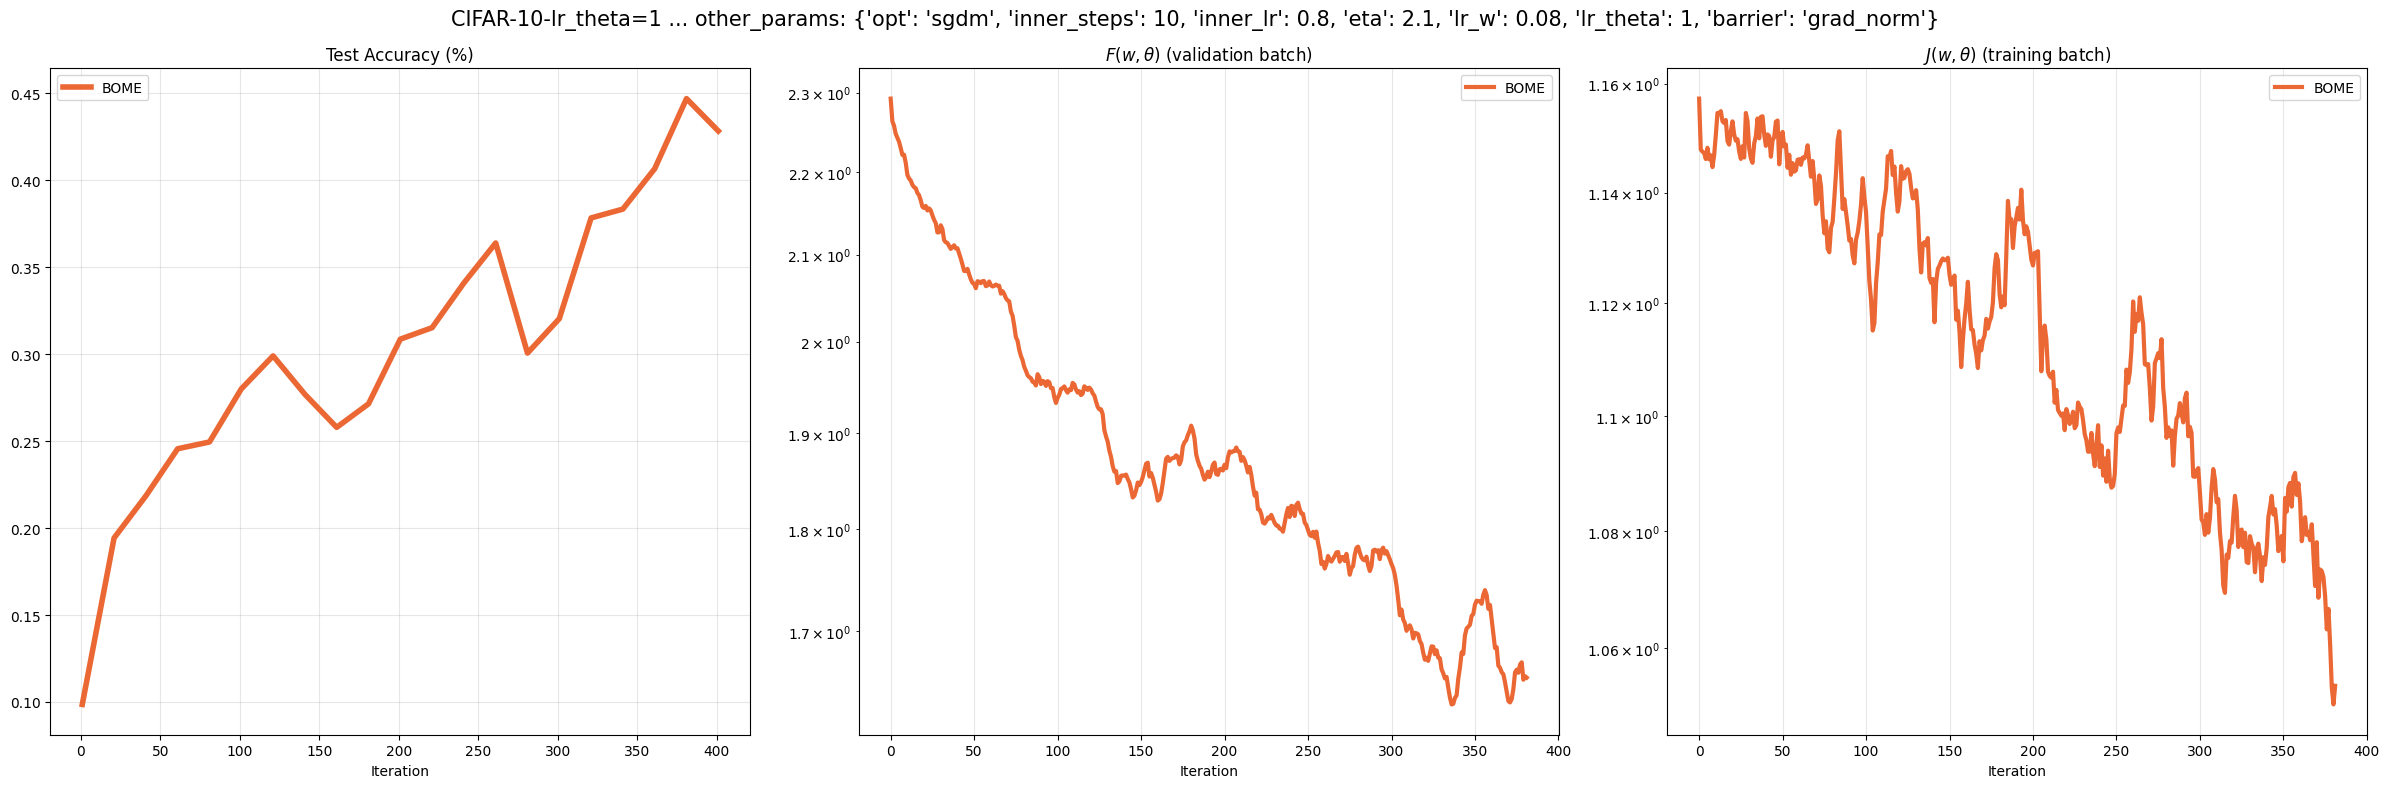

BOME         100 | LL=1.1455 | UL=1.8858 | test acc=27.66% | clean w=0.487 | corrupt w=0.475 | cleaning F1=58.51% | 45s
BOME         200 | LL=0.9768 | UL=1.8560 | test acc=30.45% | clean w=0.475 | corrupt w=0.435 | cleaning F1=63.65% | 88s
BOME         300 | LL=0.9823 | UL=1.6618 | test acc=35.62% | clean w=0.460 | corrupt w=0.393 | cleaning F1=66.35% | 131s
BOME         400 | LL=0.9282 | UL=1.4703 | test acc=42.05% | clean w=0.436 | corrupt w=0.345 | cleaning F1=67.12% | 173s



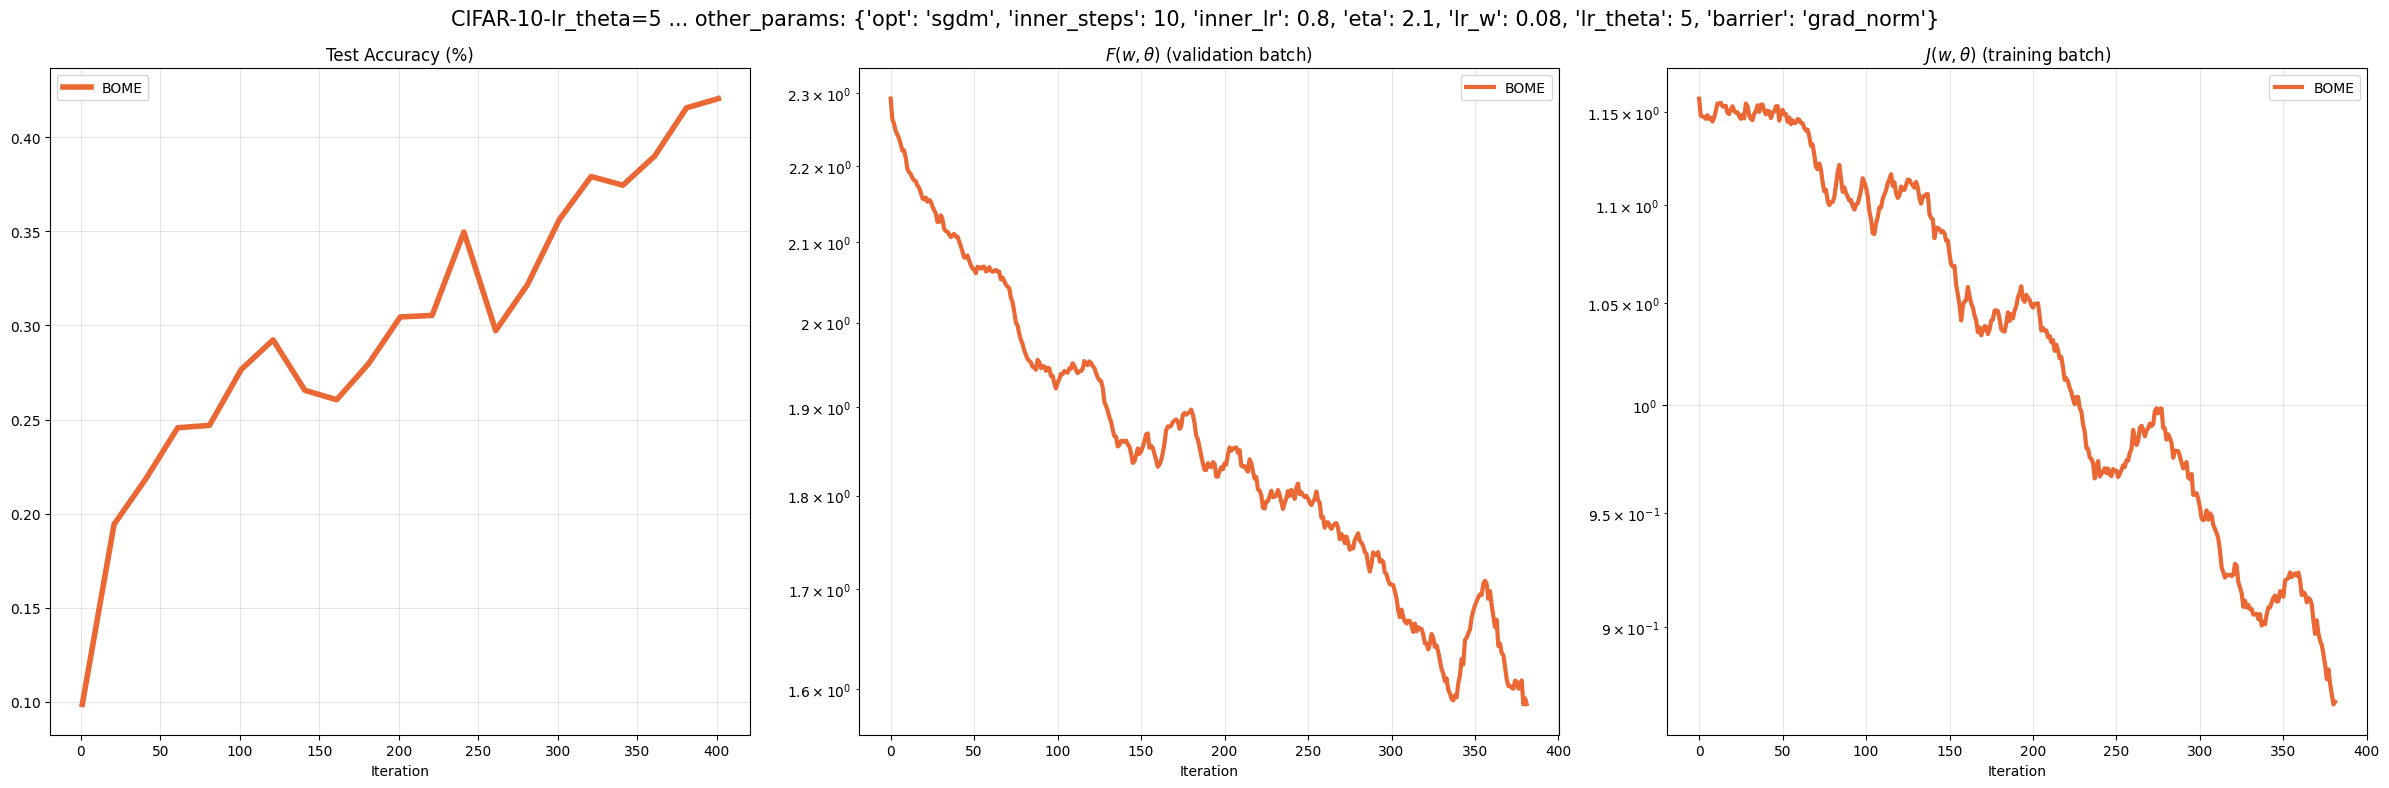

BOME         100 | LL=1.0881 | UL=1.8606 | test acc=27.51% | clean w=0.476 | corrupt w=0.453 | cleaning F1=58.77% | 44s
BOME         200 | LL=0.8585 | UL=1.7794 | test acc=33.88% | clean w=0.458 | corrupt w=0.389 | cleaning F1=63.71% | 88s
BOME         300 | LL=0.8657 | UL=1.5993 | test acc=36.68% | clean w=0.428 | corrupt w=0.327 | cleaning F1=65.90% | 131s
BOME         400 | LL=0.7159 | UL=1.6135 | test acc=41.68% | clean w=0.391 | corrupt w=0.265 | cleaning F1=67.69% | 174s



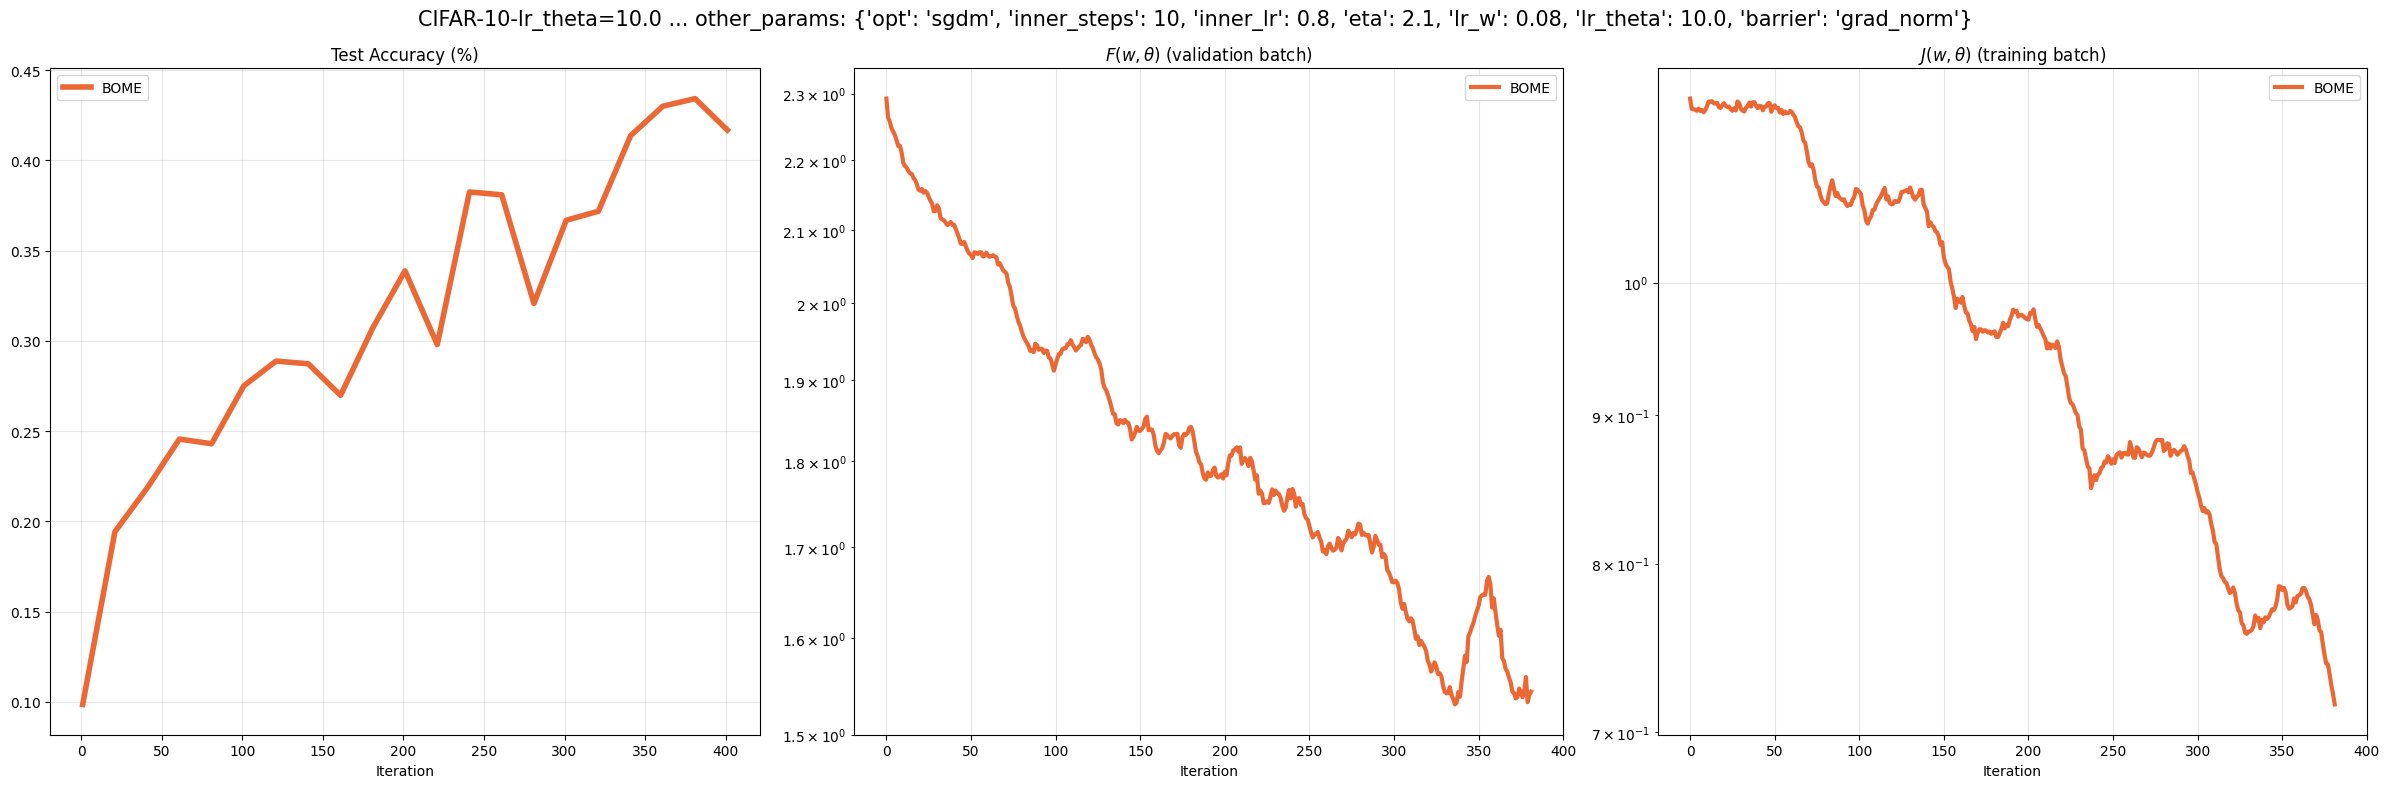

BOME         100 | LL=1.0424 | UL=1.8464 | test acc=27.73% | clean w=0.465 | corrupt w=0.436 | cleaning F1=58.79% | 45s
BOME         200 | LL=0.7867 | UL=1.7151 | test acc=32.41% | clean w=0.443 | corrupt w=0.356 | cleaning F1=64.02% | 88s
BOME         300 | LL=0.7957 | UL=1.5651 | test acc=37.13% | clean w=0.417 | corrupt w=0.291 | cleaning F1=65.92% | 131s
BOME         400 | LL=0.7000 | UL=1.4156 | test acc=42.03% | clean w=0.377 | corrupt w=0.231 | cleaning F1=67.90% | 174s



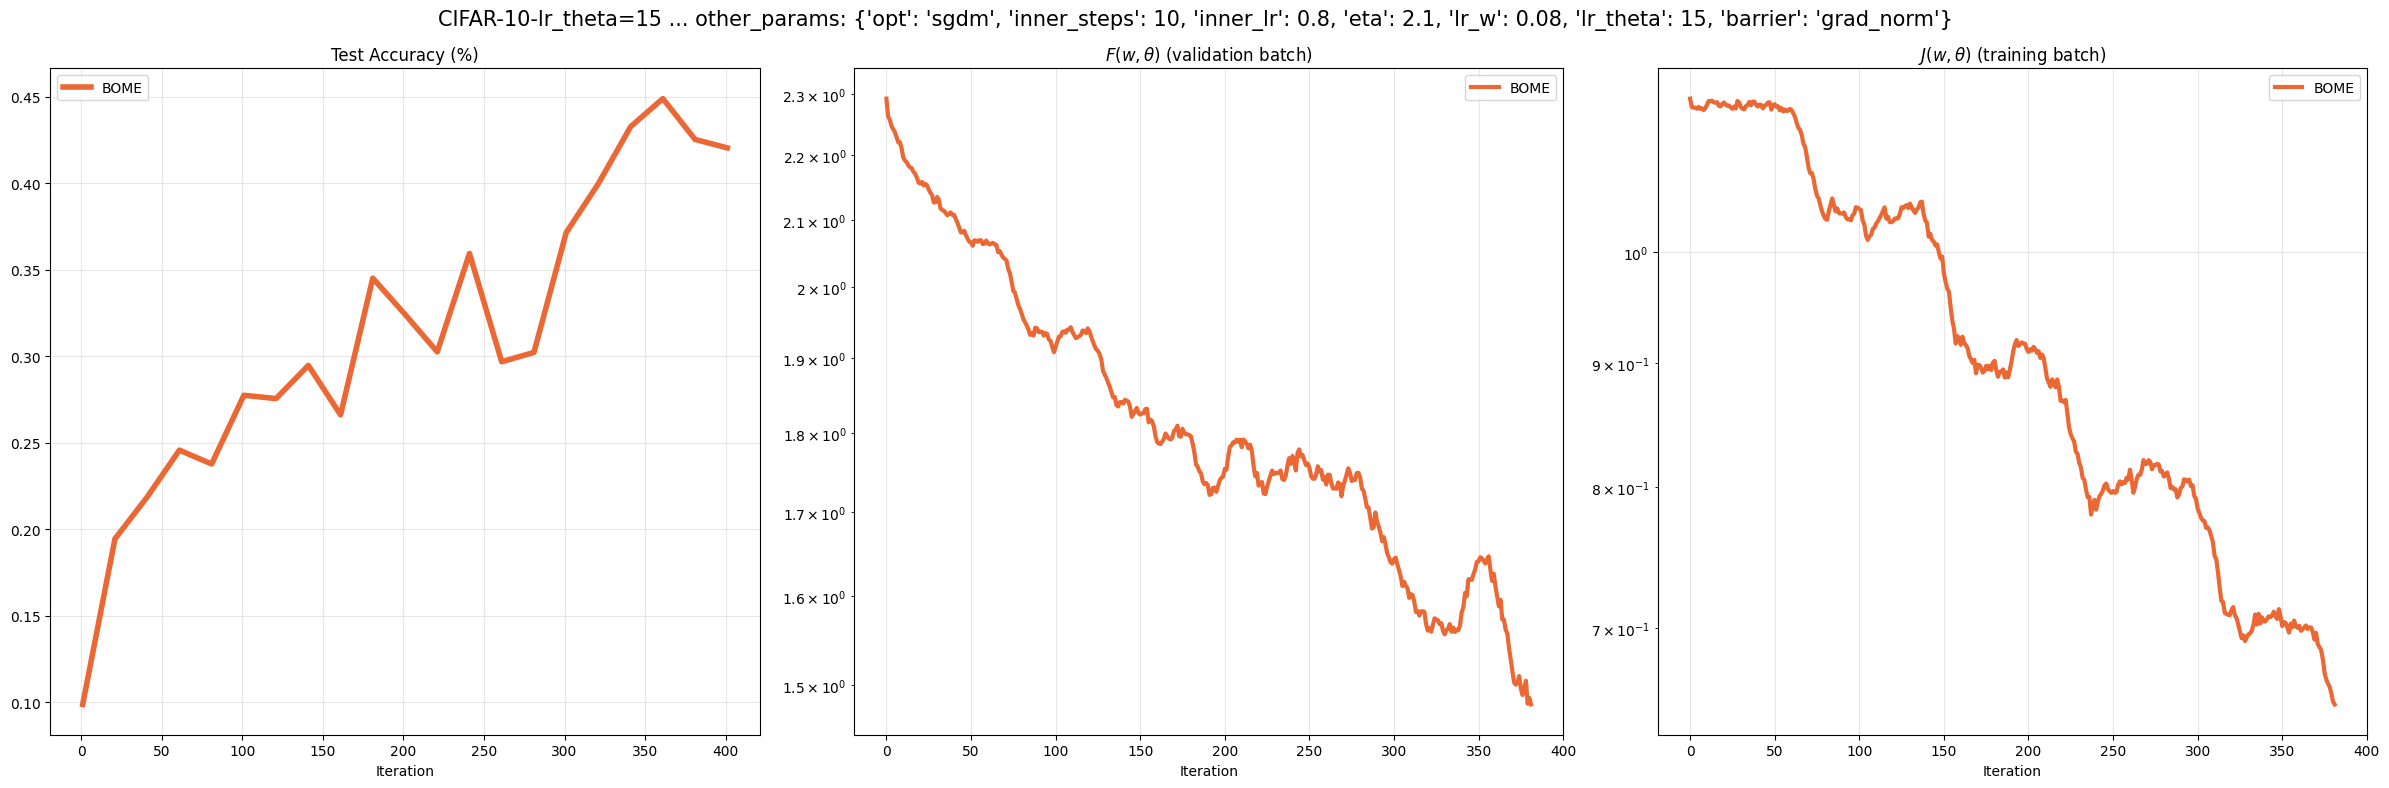

In [15]:
BATCH_SIZE=64
NUM_ITERS = 400
EVAL_EVERY = 20
SEED=0



m = "BOME"
param = "lr_lambda"
params_to_test = {"inner_lr": [0.08, 0.33, 0.8],
              "eta": [0.21, 1, 2.1], 
              "lr_w": [0.003,0.008, 0.033, 0.08], 
              "lr_theta": [1,5,10.0,15],}
              

for param, param_vals in params_to_test.items():
    for param_val in param_vals:

        
        HPARAMS[m][param] = param_val

        results_cifar = {}
        for method in [m]:
            classifier = CIFARClassifier(seed=SEED).to(device)
            weight_model = SampleWeightModel(N_TRAIN).to(device)
            optimiser = build_optimiser(method, classifier, weight_model)

            history = run_hypercleaning(optimiser, classifier, weight_model, datasets_cifar, corrupted_mask_cifar,
                                        num_iters=NUM_ITERS, batch_size=BATCH_SIZE, seed=SEED,
                                        eval_every=EVAL_EVERY, print_every=100, device=device, name=method)
            results_cifar[method] = {"history": history, "classifier": classifier, "weight_model": weight_model}
            print()

        fig, axes = plt.subplots(1, 3, figsize=(24,8))

        for method, r in results_cifar.items():
            h = r["history"]
            axes[0].plot([i+1 for i in h["eval_iterations"]], h["test_accuracy"], color=COLOURS[method], label=method, linewidth=4)
        axes[0].set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3); axes[0].legend()

        for ax, (key, title) in zip(axes[1:], [("ul_loss", r"$F(w,\theta)$ (validation batch)"), ("ll_loss", r"$J(w,\theta)$ (training batch)")]):
            for method, r in results_cifar.items():
                plot_metric(r["history"][key],linewidth=3, plot_type="mov", mean_window=20, logy=True, marker="-", ax=ax)
                ax.lines[-1].set_color(COLOURS[method]); ax.lines[-1].set_label(method)
            ax.set_title(title); ax.set_xlabel("Iteration"); ax.grid(alpha=0.3)
            ax.legend()

        fig.suptitle(f"CIFAR-10-{param}={param_val} ... other_params: {HPARAMS[m]}", fontsize=15)
        plt.tight_layout()
        plt.show()

AAL          100 | LL=1.1181 | UL=2.0262 | test acc=24.82% | clean w=0.500 | corrupt w=0.500 | cleaning F1=58.05% | 21s
AAL          200 | LL=1.1340 | UL=2.0142 | test acc=26.59% | clean w=0.500 | corrupt w=0.500 | cleaning F1=63.52% | 41s
AAL          300 | LL=1.1633 | UL=1.7506 | test acc=32.70% | clean w=0.500 | corrupt w=0.500 | cleaning F1=66.57% | 62s
AAL          400 | LL=1.1758 | UL=1.8014 | test acc=35.06% | clean w=0.500 | corrupt w=0.500 | cleaning F1=68.25% | 82s
AAL          500 | LL=1.2143 | UL=1.8407 | test acc=30.25% | clean w=0.500 | corrupt w=0.500 | cleaning F1=69.68% | 103s
AAL          600 | LL=1.1367 | UL=1.7969 | test acc=36.15% | clean w=0.500 | corrupt w=0.499 | cleaning F1=70.81% | 125s
AAL          700 | LL=1.1125 | UL=1.7958 | test acc=41.20% | clean w=0.500 | corrupt w=0.499 | cleaning F1=71.60% | 149s
AAL          800 | LL=1.0521 | UL=1.8840 | test acc=31.92% | clean w=0.500 | corrupt w=0.499 | cleaning F1=72.32% | 176s
AAL          900 | LL=1.0868 | UL=1.

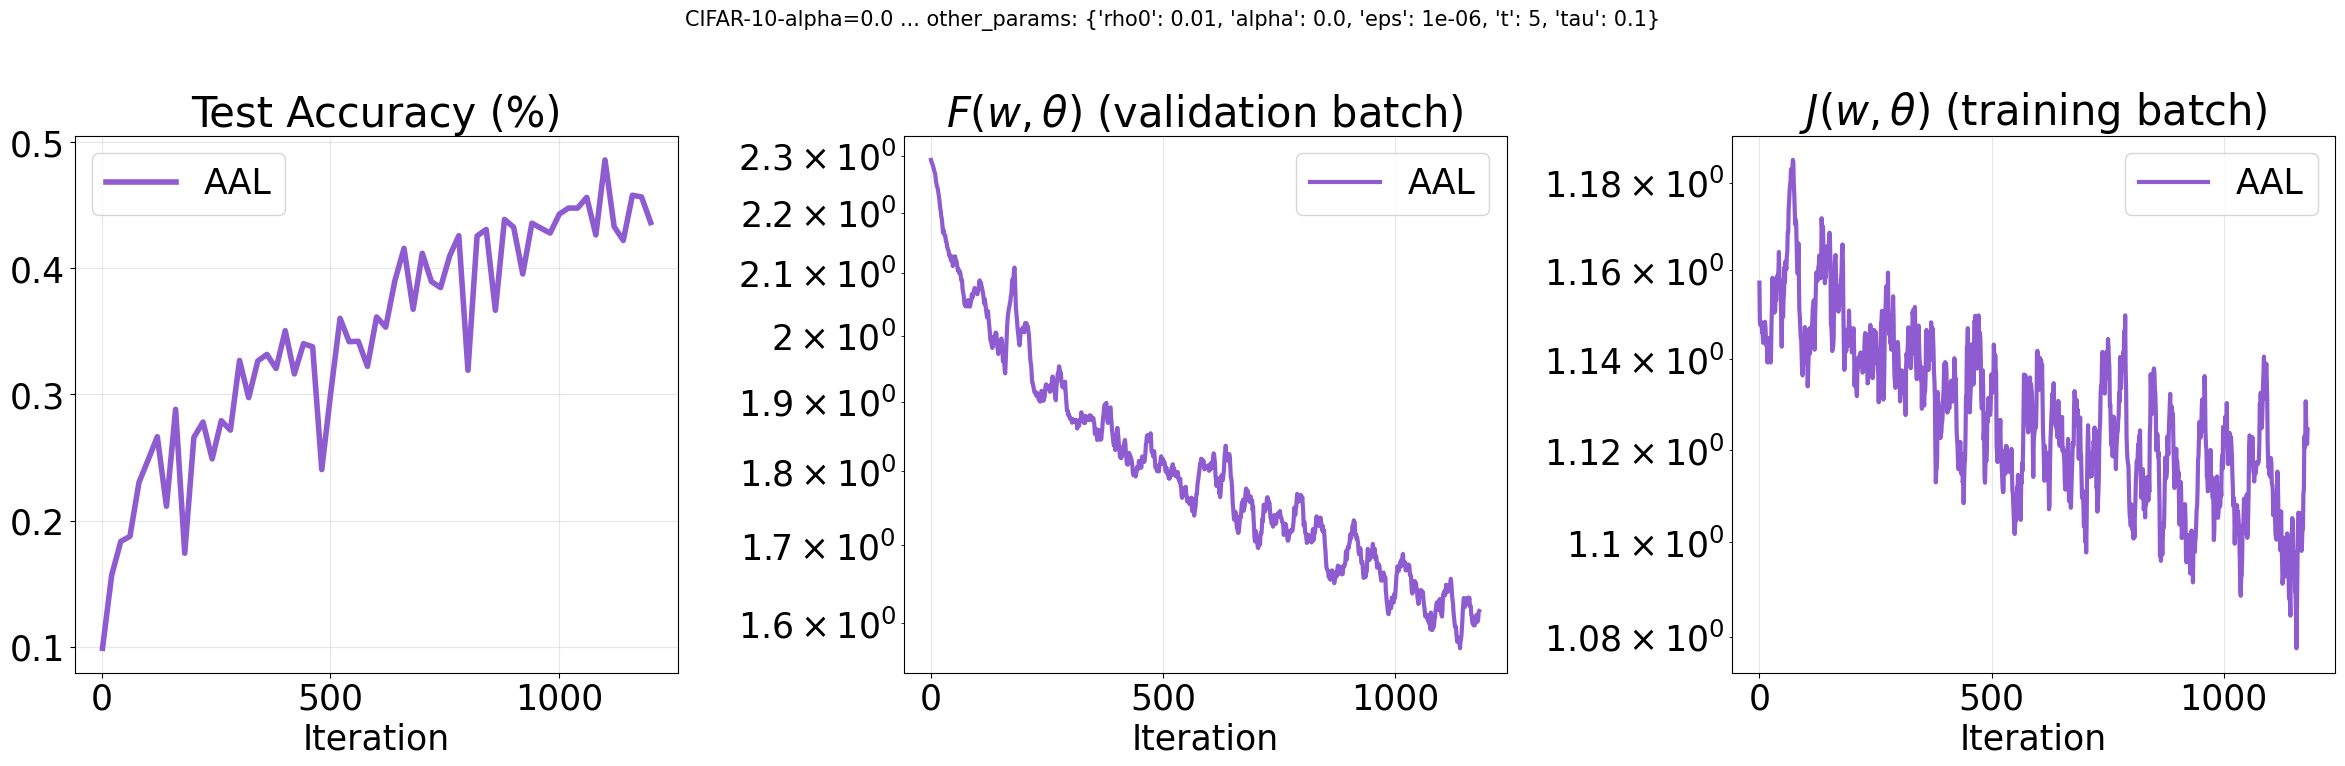

AAL          100 | LL=1.1181 | UL=2.0262 | test acc=24.78% | clean w=0.500 | corrupt w=0.500 | cleaning F1=58.05% | 29s
AAL          200 | LL=1.1327 | UL=2.0275 | test acc=26.07% | clean w=0.500 | corrupt w=0.500 | cleaning F1=63.50% | 57s
AAL          300 | LL=1.1620 | UL=1.7533 | test acc=32.71% | clean w=0.500 | corrupt w=0.500 | cleaning F1=66.56% | 84s
AAL          400 | LL=1.1746 | UL=1.8028 | test acc=34.93% | clean w=0.500 | corrupt w=0.500 | cleaning F1=68.21% | 111s
AAL          500 | LL=1.2074 | UL=1.8416 | test acc=30.46% | clean w=0.500 | corrupt w=0.500 | cleaning F1=69.77% | 138s
AAL          600 | LL=1.1328 | UL=1.8027 | test acc=36.41% | clean w=0.500 | corrupt w=0.499 | cleaning F1=70.96% | 164s
AAL          700 | LL=1.1135 | UL=1.8044 | test acc=41.32% | clean w=0.500 | corrupt w=0.499 | cleaning F1=71.76% | 191s
AAL          800 | LL=1.0554 | UL=1.8898 | test acc=31.59% | clean w=0.500 | corrupt w=0.499 | cleaning F1=72.40% | 217s
AAL          900 | LL=1.0869 | UL=1

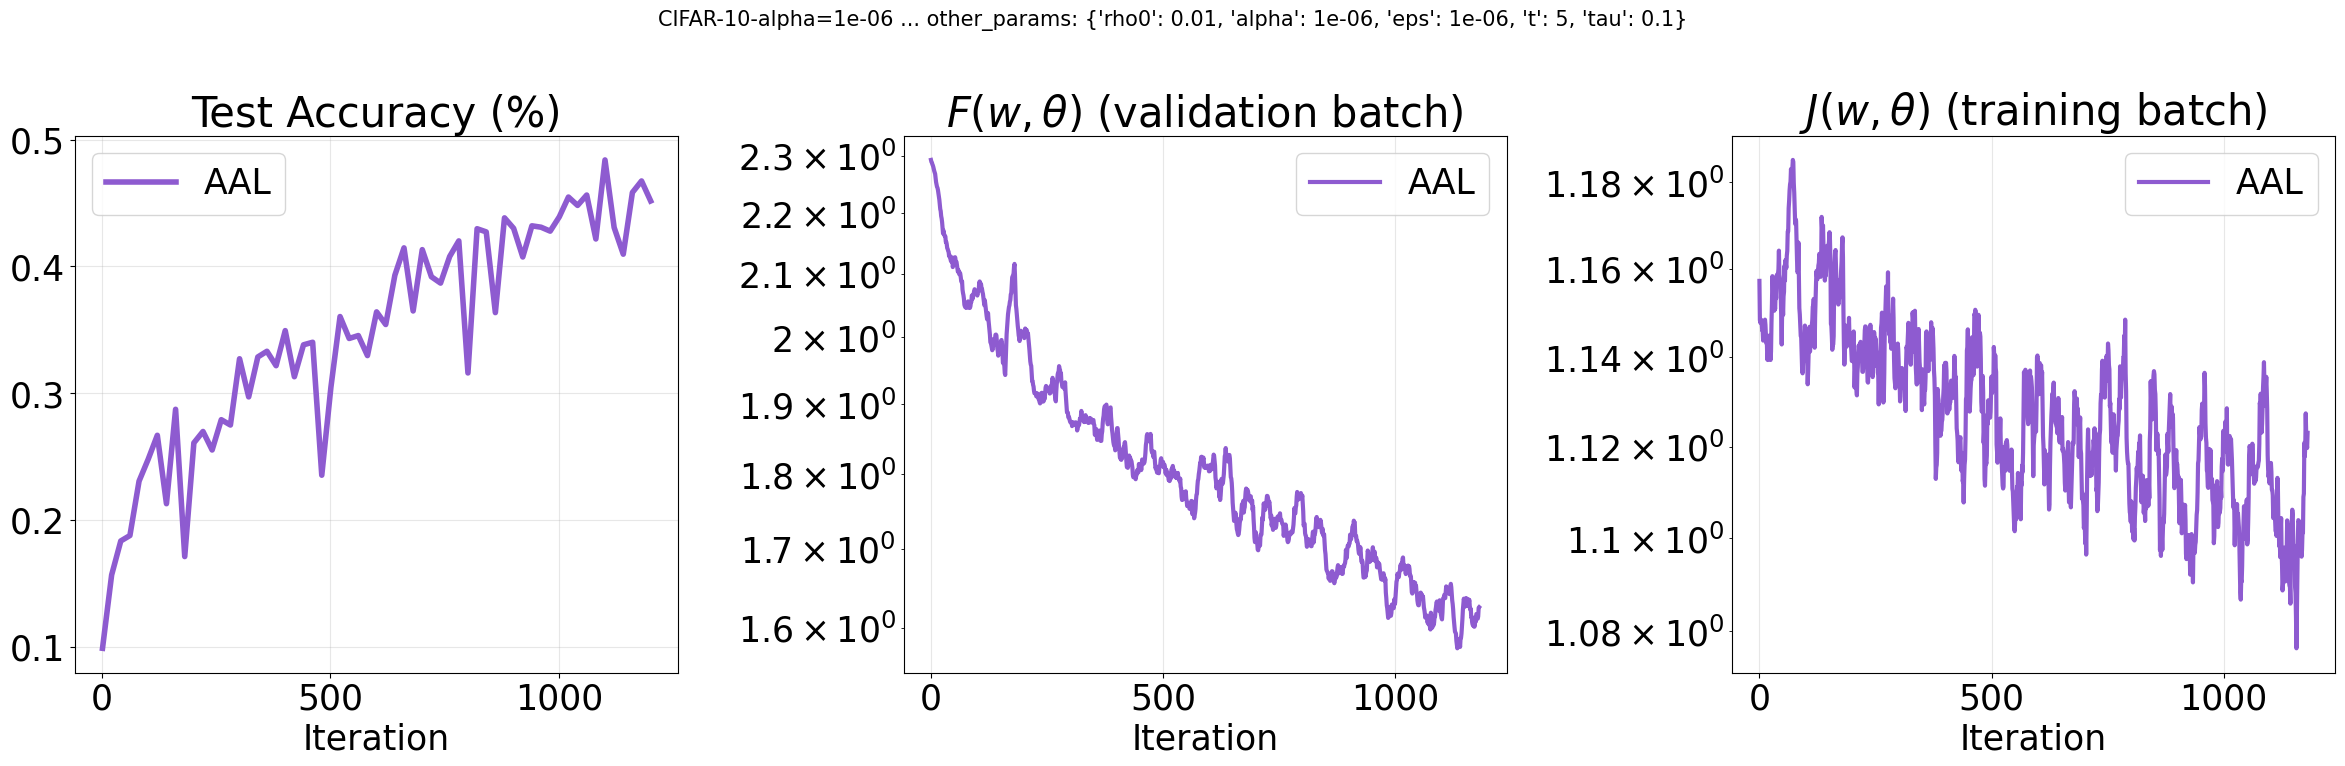

AAL          100 | LL=1.1118 | UL=2.0301 | test acc=24.90% | clean w=0.500 | corrupt w=0.500 | cleaning F1=58.15% | 28s
AAL          200 | LL=1.1280 | UL=2.0424 | test acc=25.00% | clean w=0.500 | corrupt w=0.500 | cleaning F1=63.75% | 55s
AAL          300 | LL=1.1364 | UL=1.7921 | test acc=31.18% | clean w=0.500 | corrupt w=0.500 | cleaning F1=66.94% | 81s
AAL          400 | LL=1.1605 | UL=1.8572 | test acc=33.20% | clean w=0.500 | corrupt w=0.500 | cleaning F1=68.56% | 107s
AAL          500 | LL=1.1844 | UL=1.8878 | test acc=33.25% | clean w=0.500 | corrupt w=0.500 | cleaning F1=70.12% | 134s
AAL          600 | LL=1.1041 | UL=1.8559 | test acc=38.13% | clean w=0.500 | corrupt w=0.499 | cleaning F1=71.32% | 160s
AAL          700 | LL=1.1028 | UL=1.8673 | test acc=40.13% | clean w=0.500 | corrupt w=0.499 | cleaning F1=72.23% | 186s
AAL          800 | LL=1.0574 | UL=1.9170 | test acc=34.36% | clean w=0.500 | corrupt w=0.499 | cleaning F1=72.78% | 213s
AAL          900 | LL=1.0786 | UL=1

KeyboardInterrupt: 

In [170]:
m = "AAL"

HPARAMS["AAL"] = dict(rho0=0.01, alpha=0.000, eps=1e-6, t=5, tau=0.1)
NUM_ITERS = 1200
params_to_test = {
                # "p": [5e-5,1e-4,5e-3],
                # "tau": [0.1, 0.5, 1, 2],
            #   "t": [5, 6, 8,], 
              "alpha": [0.0, 1e-6, 1e-4], }
              

for param, param_vals in params_to_test.items():
    for param_val in param_vals:

        
        HPARAMS[m][param] = param_val

        results_cifar = {}
        for method in [m]:
            classifier = CIFARClassifier(seed=SEED).to(device)
            weight_model = SampleWeightModel(N_TRAIN).to(device)
            optimiser = build_optimiser(method, classifier, weight_model)

            history = run_hypercleaning(optimiser, classifier, weight_model, datasets_cifar, corrupted_mask_cifar,
                                        num_iters=NUM_ITERS, batch_size=BATCH_SIZE, seed=SEED,
                                        eval_every=EVAL_EVERY, print_every=100, device=device, name=method)
            results_cifar[method] = {"history": history, "classifier": classifier, "weight_model": weight_model}
            
            print()
        print('TestAcc last 100:', ScoreTest(results_cifar[m]["history"]["test_accuracy"]))

        fig, axes = plt.subplots(1, 3, figsize=(24,8))

        for method, r in results_cifar.items():
            h = r["history"]
            axes[0].plot([i+1 for i in h["eval_iterations"]], h["test_accuracy"], color=COLOURS[method], label=method, linewidth=4)
        axes[0].set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3); axes[0].legend()

        for ax, (key, title) in zip(axes[1:], [("ul_loss", r"$F(w,\theta)$ (validation batch)"), ("ll_loss", r"$J(w,\theta)$ (training batch)")]):
            for method, r in results_cifar.items():
                plot_metric(r["history"][key],linewidth=3, plot_type="mov", mean_window=20, logy=True, marker="-", ax=ax)
                ax.lines[-1].set_color(COLOURS[method]); ax.lines[-1].set_label(method)
            ax.set_title(title); ax.set_xlabel("Iteration"); ax.grid(alpha=0.3)
            ax.legend()

        fig.suptitle(f"CIFAR-10-{param}={param_val} ... other_params: {HPARAMS[m]}", fontsize=15)
        plt.tight_layout()
        plt.show()

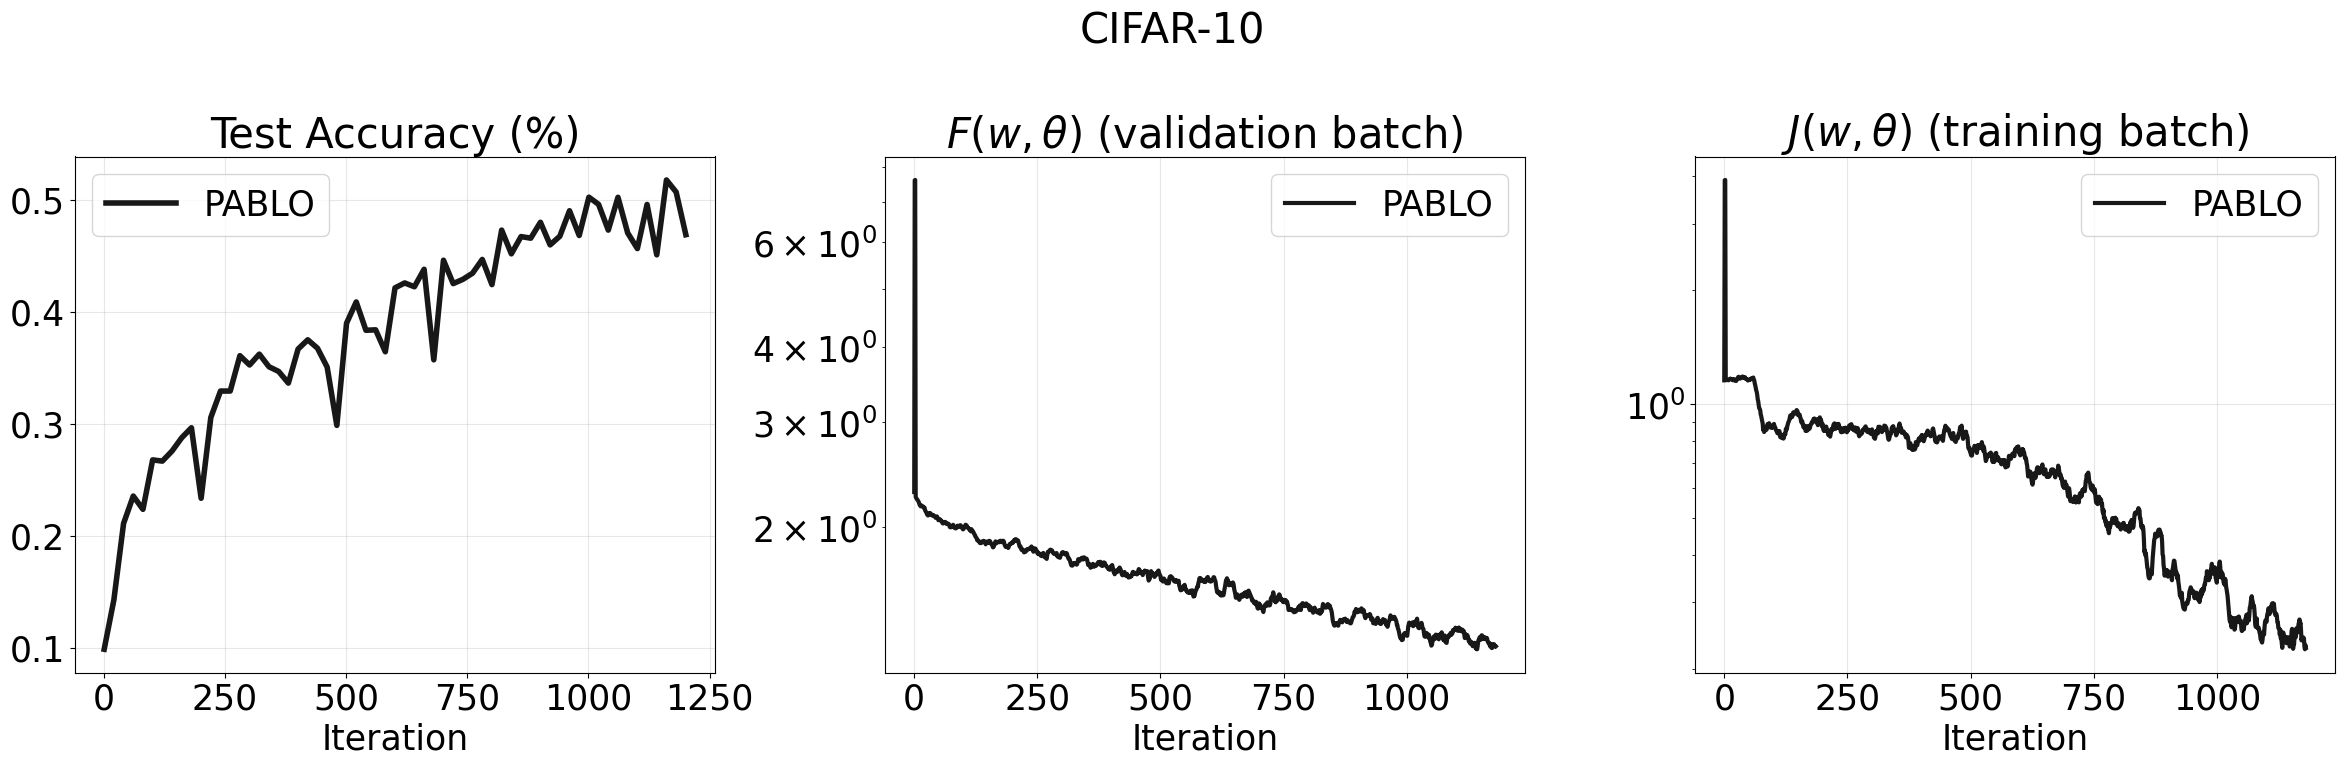

method      test acc   test F1  clean F1  clean w  corrupt w
PABLO         46.90%    44.32%    68.59%    0.238      0.081


In [152]:
fig, axes = plt.subplots(1, 3, figsize=(24,8))

for method, r in results_cifar.items():
    h = r["history"]
    axes[0].plot([i+1 for i in h["eval_iterations"]], h["test_accuracy"], color=COLOURS[method], label=method, linewidth=4)
axes[0].set_title('Test Accuracy (%)'); axes[0].set_xlabel("Iteration"); axes[0].grid(alpha=0.3); axes[0].legend()

for ax, (key, title) in zip(axes[1:], [("ul_loss", r"$F(w,\theta)$ (validation batch)"), ("ll_loss", r"$J(w,\theta)$ (training batch)")]):
    for method, r in results_cifar.items():
        plot_metric(r["history"][key],linewidth=3, plot_type="mov", mean_window=20, logy=True, marker="-", ax=ax)
        ax.lines[-1].set_color(COLOURS[method]); ax.lines[-1].set_label(method)
    ax.set_title(title); ax.set_xlabel("Iteration"); ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("CIFAR-10")
plt.tight_layout()
plt.show()

print(f"{'method':<10} {'test acc':>9} {'test F1':>9} {'clean F1':>9} {'clean w':>8} {'corrupt w':>10}")
for method, r in results_cifar.items():
    h = r["history"]
    print(f"{method:<10} {100*h['test_accuracy'][-1]:8.2f}% {100*h['test_macro_f1'][-1]:8.2f}% "
          f"{100*h['cleaning_f1'][-1]:8.2f}% {h['clean_weight'][-1]:8.3f} {h['corrupted_weight'][-1]:10.3f}"
          + ("" if h["valid"] else "   (diverged)"))

## Synthetic Data Generation: Multilinear Regression vs Baseline

OLS regression comparing three generation strategies against **baseline** (no turns, no seq_efsm, no markov), controlling for student model, log synthetic data size, epochs, and LoRA.

- **turns_only**: `turns_uniform` or `turns_matching`, without seq_efsm or markov augmentation
- **seq_efsm**: EFSM-based sequential generation (co-occurs with `turns_uniform`)
- **markov**: any Markov-based sequential generation (`seq_mark_uni_data`, `seq_mark_complete_data`)

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

CSV_PATH = '/Users/aaronfainman/Documents/1.1 Distil/Code backup/HelperScripts/mutator-results-fin - Sheet7.csv'

# ── Load & clean ──────────────────────────────────────────────────────────────
df_raw = pd.read_csv(CSV_PATH)
_bool_cols = ['baseline', 'turns_uniform', 'turns_matching', 'seq_mark_complete_data',
              'seq_mark_uni_data', 'seq_markov_complete_complete', 'seq_efsm', 'lora']
for c in _bool_cols:
    df_raw[c] = df_raw[c].map({True: True, False: False, 'TRUE': True, 'FALSE': False})

OUTCOME_COLS = [
    'tool_call_equivalence', 'bfcl_correct', 'bfcl_state', 'bfcl_response',
    'bfcl_avg_response_per_turn', 'bfcl_avg_state_per_turn',
    'llm_as_a_judge', 'llm_as_a_judge_ref_free',
]

d = df_raw.dropna(subset=['tool_call_equivalence']).copy()

# ── Treatment groups (mutually exclusive; baseline is the omitted reference) ─
d['markov']     = d['seq_mark_complete_data'] | d['seq_mark_uni_data'] | d['seq_markov_complete_complete']
d['turns_only'] = (d['turns_uniform'] | d['turns_matching']) & ~d['seq_efsm'] & ~d['markov']

# ── Covariates ────────────────────────────────────────────────────────────────
d['log_syn_size'] = np.log1p(d['synthetic_data_size'])
_student_dummies  = pd.get_dummies(d['student'], prefix='student', drop_first=True)
d = pd.concat([d, _student_dummies], axis=1)

TREATMENT_COLS = ['turns_only', 'seq_efsm', 'markov']
COVARIATE_COLS = ['log_syn_size', 'epochs', 'lora'] + list(_student_dummies.columns)

analysis = d.dropna(subset=OUTCOME_COLS + COVARIATE_COLS, how='any').copy()
print(f"N={len(analysis)}  baseline={analysis['baseline'].sum()}  "
      f"turns_only={analysis['turns_only'].sum()}  "
      f"seq_efsm={analysis['seq_efsm'].sum()}  markov={analysis['markov'].sum()}")

# ── OLS for each outcome ──────────────────────────────────────────────────────
X = sm.add_constant(analysis[TREATMENT_COLS + COVARIATE_COLS].astype(float))
ols_results = {o: sm.OLS(analysis[o].astype(float), X).fit() for o in OUTCOME_COLS}

# ── Summary table ─────────────────────────────────────────────────────────────
def _fmt(coef, pval):
    stars = '***' if pval < 0.001 else ('**' if pval < 0.01 else ('*' if pval < 0.05 else '  '))
    return f"{coef:+.4f}{stars}"

rows = []
for o in OUTCOME_COLS:
    r = ols_results[o]
    row = {'outcome': o, 'R²': f"{r.rsquared:.3f}"}
    for t in TREATMENT_COLS:
        row[t] = _fmt(r.params[t], r.pvalues[t])
    rows.append(row)

tbl = pd.DataFrame(rows).set_index('outcome')
print("\nOLS Coefficients vs Baseline   (* p<.05  ** p<.01  *** p<.001)\n")
display(tbl[TREATMENT_COLS + ['R²']])

In [ ]:
import matplotlib.colors as mcolors

OUTCOME_LABELS = {
    'tool_call_equivalence':      'Tool Call Equiv.',
    'bfcl_correct':               'BFCL Correct',
    'bfcl_state':                 'BFCL State',
    'bfcl_response':              'BFCL Response',
    'bfcl_avg_response_per_turn': 'Avg Response/Turn',
    'bfcl_avg_state_per_turn':    'Avg State/Turn',
    'llm_as_a_judge':             'LLM-as-Judge',
    'llm_as_a_judge_ref_free':    'LLM-as-Judge (RF)',
}

fig, axes = plt.subplots(1, len(TREATMENT_COLS), figsize=(15, 5), sharey=True)
fig.subplots_adjust(wspace=0.08)

for ax, treatment in zip(axes, TREATMENT_COLS):
    coefs = [ols_results[o].params[treatment] for o in OUTCOME_COLS]
    pvals = [ols_results[o].pvalues[treatment] for o in OUTCOME_COLS]

    bar_colors = [mcolors.to_rgba('#2196F3' if c >= 0 else '#F44336', 1.0 if p < 0.05 else 0.3)
                  for c, p in zip(coefs, pvals)]
    ax.barh(range(len(OUTCOME_COLS)), coefs, color=bar_colors)
    ax.axvline(0, color='black', linewidth=0.8)

    for i, (c, p) in enumerate(zip(coefs, pvals)):
        label = f'{c:+.3f}' + ('*' * (1 + int(p < 0.01) + int(p < 0.001)) if p < 0.05 else '')
        ax.text(c + np.sign(c) * 0.001, i, label,
                va='center', ha='left' if c >= 0 else 'right', fontsize=8)

    ax.set_yticks(range(len(OUTCOME_COLS)))
    ax.set_yticklabels([OUTCOME_LABELS[o] for o in OUTCOME_COLS])
    ax.set_title(treatment, fontsize=13, fontweight='bold')
    ax.set_xlabel('Coefficient vs baseline')
    ax.grid(axis='x', alpha=0.3)

fig.suptitle('OLS Coefficients vs Baseline\n'
             '(opaque = p < 0.05; blue = positive, red = negative)',
             fontsize=12)
plt.tight_layout()
plt.show()